In [112]:
# # in_dir = '../example_station/input'
# station_id = '042006' #'026017'
# qc_column = 2
# qc_flags = '3'
# round_decimals =1

# def load_station_data(station_id: str) -> pd.DataFrame:
#     url = f"https://catalogue.ceh.ac.uk/datastore/eidchub/211710ac-f01b-4b52-807f-373babb1c368/1_RiverFlowStations/{station_id}.csv"
#     return pd.read_csv(url, parse_dates=["datetime"], index_col="datetime")
# df = load_station_data(station_id)
# df.head()

# # Clean rows where value is string 'NA' (but keep numeric instances of NAN)
# df = remove_empty(df)
# # Ensure values are numeric
# df["value"] = pd.to_numeric(df["value"], errors="coerce")

# flag_padded = normalize_flag_to_3char(df["flag"])

# # Store the padded flags in the dataframe so they are visible when inspecting the data
# df["flag_padded"] = flag_padded

# flagged_rows = build_qc_mask(flag_padded, qc_column=qc_column, qc_flags=qc_flags)

# # Preview which rows have been flagged
# print(f"\n{flagged_rows.sum()} rows flagged for interpolation out of {len(df)} total rows.")
# print("\nFlagged rows:")
# print(df.loc[flagged_rows, ["flag", "flag_padded", "value"]].head(10))

# Interpolation tool

This is a QC (Quality Control) driven data interpolation tool for UK-Flow-15 time-series flow data.  

The code reads CSV files containing sensor readings every 15 minutes, finds data points flagged as poor quality, replaces them with interpolated values, and saves the cleaned data.

### Quality Control Flags
Each timestep in the flow data is assigned a three-digit QC code as part of the quality control procedure. Each digit of the three-digit code (X,Y,Z) represents the result of an independent check:
 
- (X): Consistency check against other established UK hydrological products 
- (Y): Standard QC anomaly checks 
- (Z): High-flow event checks 

![QC Code](InputFigures/QC_Code.png)

For each of the three checks, the digit value indicates the severity of the issue — for example, a 0 might mean the data passed cleanly, while higher digits indicate progressively worse problems. 

The tables below list the meaning of the range of possible values for each of the three checks. So, for a value of 204, this means that for 1974-12-28 15:45:00:
 
- (X): 2 -> Mismatch >20% between 15-min values and POT values (Consistency check against other established UK hydrological products)
- (Y): 0 -> No issues found (Standard QC anomaly checks)
- (Z): 4 -> Event with >0.1 annual likelihood and no concurrent high flow in the hydrometric area (High-flow event checks) 

<img src="InputFigures/QC_Table1.png" width="400" height="200">
<img src="InputFigures/QC_Table2.png" width="400" height="200">
<img src="InputFigures/QC_Table3-2.png" width="400" height="200">
<img src="InputFigures/QC_Table3-1.png" width="400" height="200"> 

### Filtering by QC Flag

The presence of these QC flags allows users to identify 'bad' data points in the timeseries, and to replace their values using time-based interpolation from the surrounding 'good' data. 

To filter out bad data, two things must be specified:  

- qc_column — which column to look at (0=X, 1=Y, 2=Z)
- qc_flags — which digit values in that position should be treated as bad data

For example, qc_column=1, qc_flags="38" would flag any timestep where the Y check returned a 3 or an 8:

"137" → Y digit is 3 → flagged ✗  
"060" → Y digit is 6 → not flagged ✓  
"238" → Y digit is 3 → flagged ✗  

Flagged values are then replaced by time-based interpolation from the surrounding good data.

### Initial setup variables

In [1]:
import os
import pandas as pd
import sys
sys.path.insert(1, '../')
from functions import *
import matplotlib.pyplot as plt

station_id = '042006' #'026017'
qc_column = 2
qc_flags = '238'
round_decimals =1

## Read in and clean the flow data

In [26]:
def load_station_data(station_id: str) -> pd.DataFrame:
    url = f"https://catalogue.ceh.ac.uk/datastore/eidchub/211710ac-f01b-4b52-807f-373babb1c368/1_RiverFlowStations/{station_id}.csv"
    return pd.read_csv(url, parse_dates=["datetime"], index_col="datetime")
df = load_station_data(station_id)
df.head()

,value,resolution,flag
datetime,,,
1981-08-01 00:00:00,0.623,NaN,0.0
1981-08-01 00:15:00,0.628,15.0,0.0
1981-08-01 00:30:00,0.633,15.0,0.0
1981-08-01 00:45:00,0.637,15.0,0.0
1981-08-01 01:00:00,0.642,15.0,0.0


### Data Format:
Each station has a CSV file with these columns:

- Datetime — timestamp (used as the index)  
- Value — the flow measurement at the station in m3s-1
- Resolution - the original temporal interval between each observation in minutes. Regular intervals are indicated numerically, for instance, 120 representing a two-hour interval. Special cases include irregular time intervals, which are coded as 0, and intervals with an anomalous one-second gap, coded as 1   
- Flag — a quality control code, e.g. 060 or 137 

In [27]:
# Clean rows where value is string 'NA' (but keep numeric instances of NAN)
df = remove_empty(df)
# Ensure values are numeric
df["value"] = pd.to_numeric(df["value"], errors="coerce")

# =============================================================================
# Standardise QC flags
# =============================================================================
# QC flags are stored as numbers (e.g. 60, 7, 137) but we need to inspect
# individual digits by position. To do this reliably, we first convert all
# flags to zero-padded 3-character strings so that every flag has exactly
# three digits and the X, Y, Z positions are always consistent.
#
#   7   ->  "007"   (X=0, Y=0, Z=7)
#   60  ->  "060"   (X=0, Y=6, Z=0)
#   137 ->  "137"   (X=1, Y=3, Z=7)

flag_padded = normalize_flag_to_3char(df["flag"])

# Store the padded flags in the dataframe so they are visible when inspecting the data
df["flag_padded"] = flag_padded

###  Run Interpolation 

In [28]:
# =============================================================================
# STEP 2: IDENTIFY FLAGGED (BAD) ROWS
# =============================================================================
# Using the padded flags, we now identify which rows should be interpolated.
# This is controlled by two parameters:
#
#   qc_column : which digit position to inspect (0=X, 1=Y, 2=Z)
#   qc_flags  : which digit values at that position indicate bad data
#
# For example, qc_column=1 and qc_flags="38" would flag any row where
# the Y digit is a 3 or an 8.
#
# The result is a boolean Series (True/False for every row) indicating
# which rows are flagged for interpolation.

flagged_rows = build_qc_mask(flag_padded, qc_column=qc_column, qc_flags=qc_flags)

# Preview which rows have been flagged
print(f"\n{flagged_rows.sum()} rows flagged for interpolation out of {len(df)} total rows.")
df.loc[flagged_rows, ["flag", "flag_padded", "value"]][:40]


187 rows flagged for interpolation out of 1487328 total rows.


,flag,flag_padded,value
datetime,,,
2014-11-10 09:30:00,133.0,133,69.177
2018-11-17 16:45:00,172.0,172,628.257
2018-11-17 17:00:00,172.0,172,628.257
2018-11-17 17:15:00,172.0,172,628.257
2018-11-17 17:30:00,172.0,172,628.257
2018-11-17 17:45:00,172.0,172,628.257
2018-11-17 18:00:00,172.0,172,628.257
2018-11-17 18:15:00,172.0,172,628.257
2018-11-17 18:30:00,172.0,172,628.257


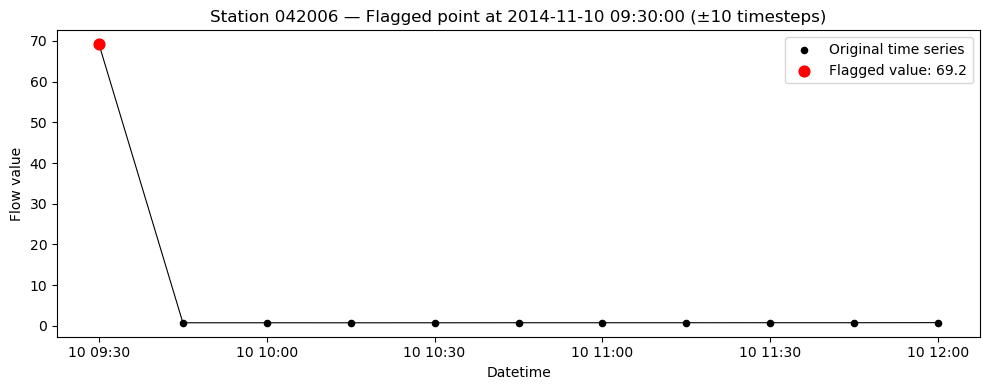

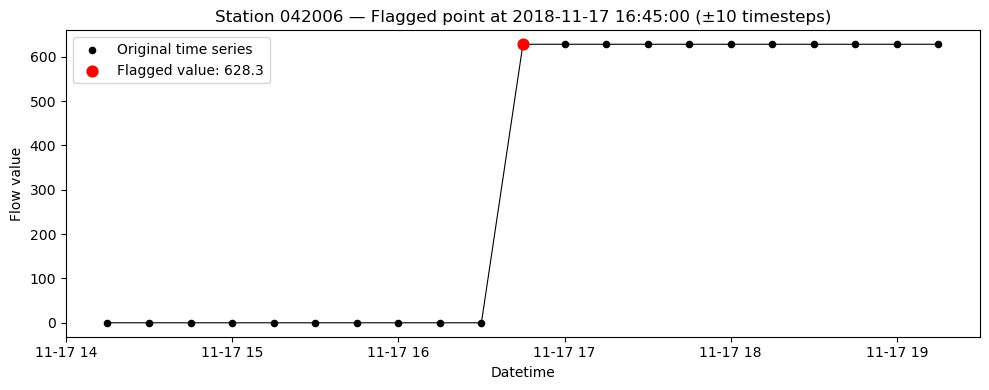

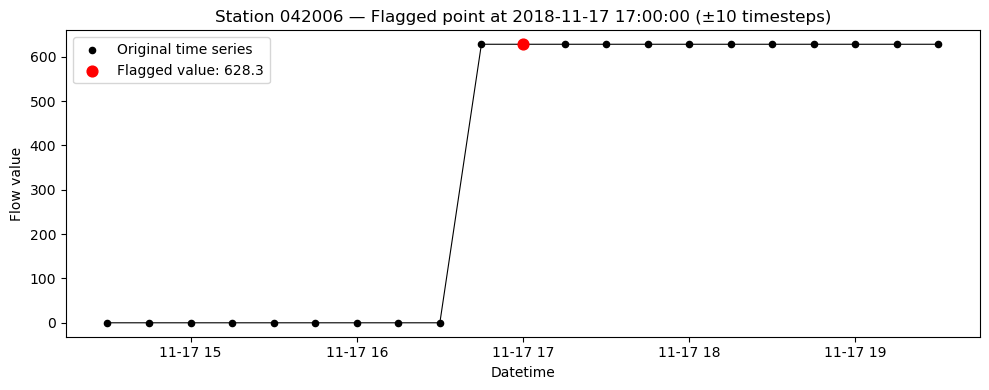

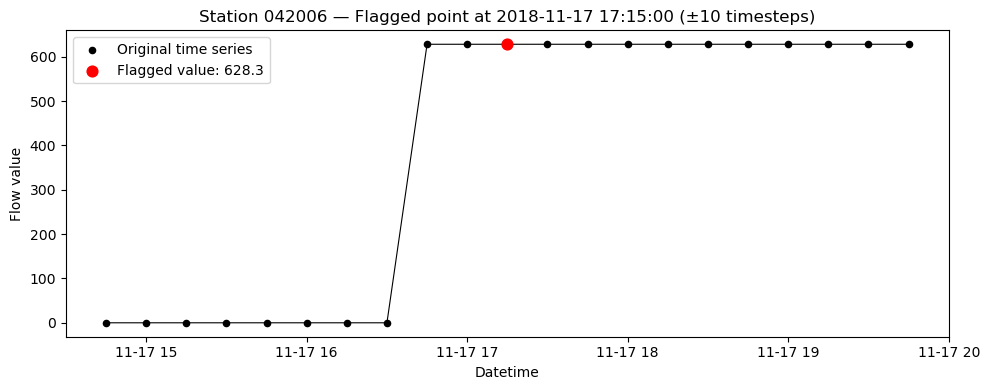

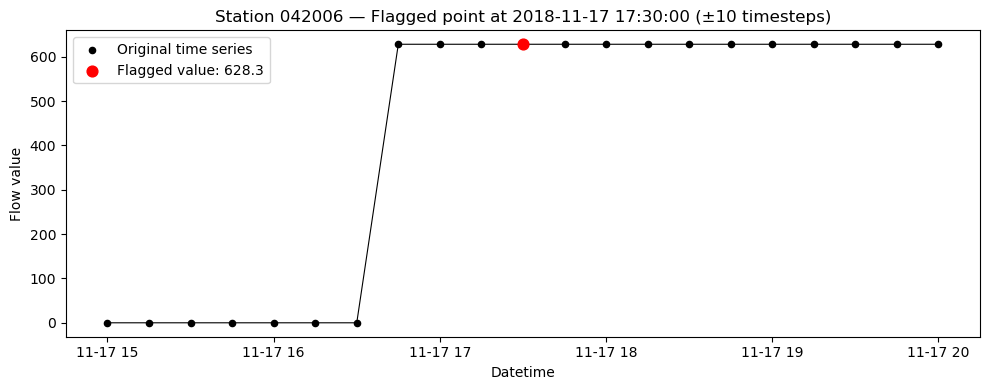

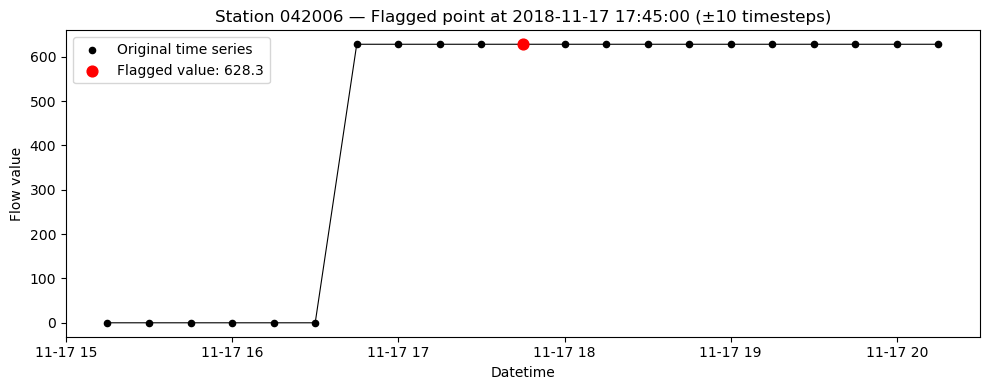

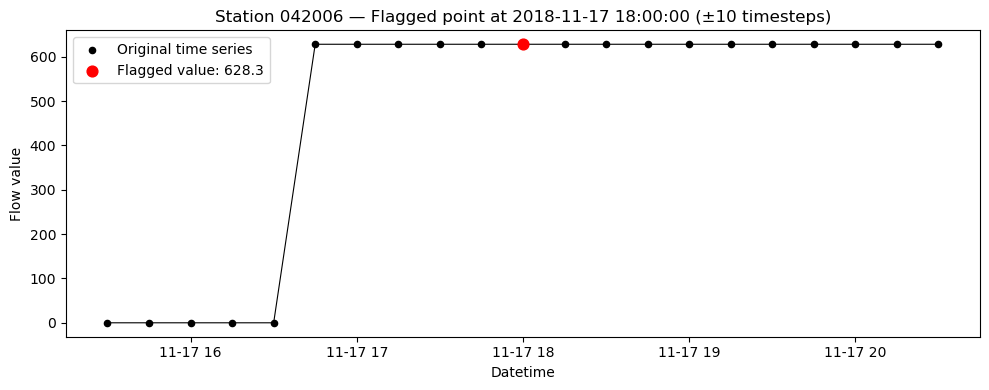

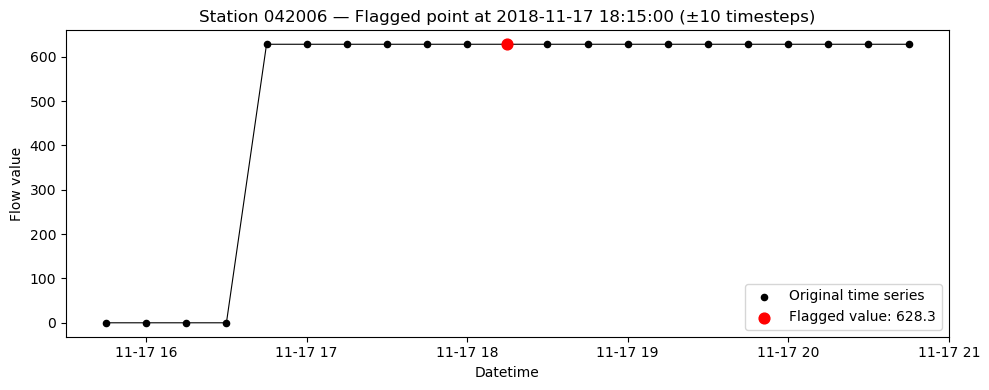

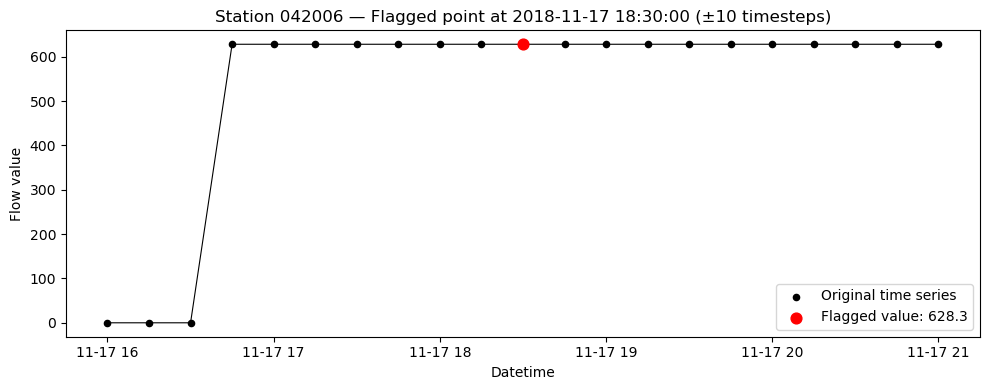

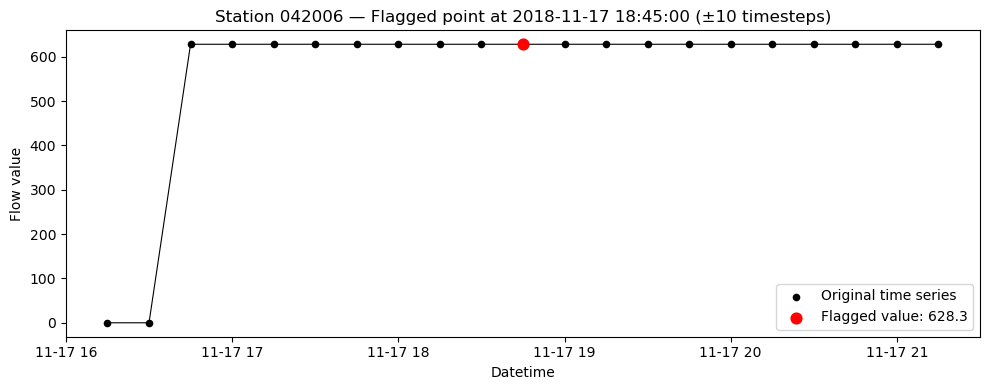

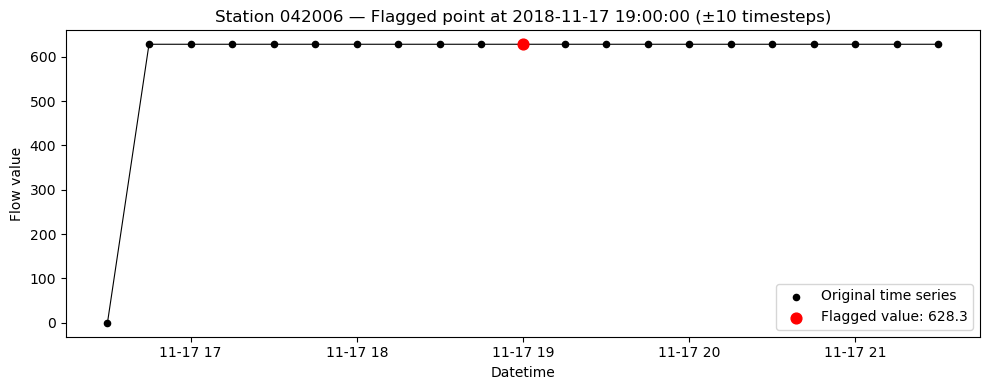

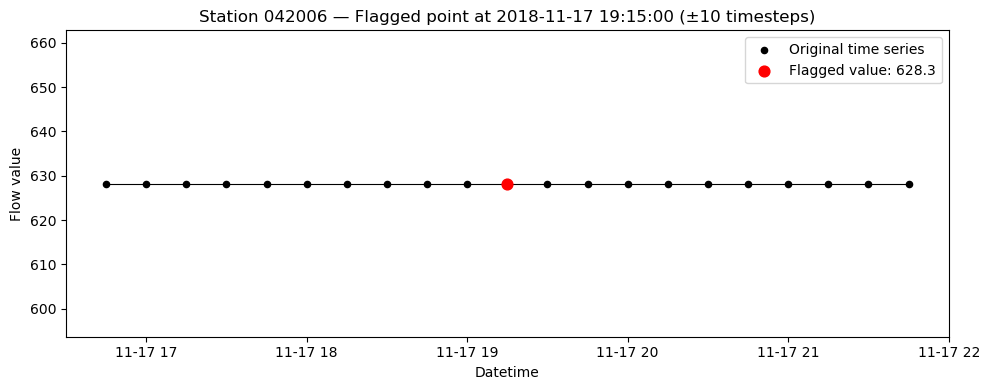

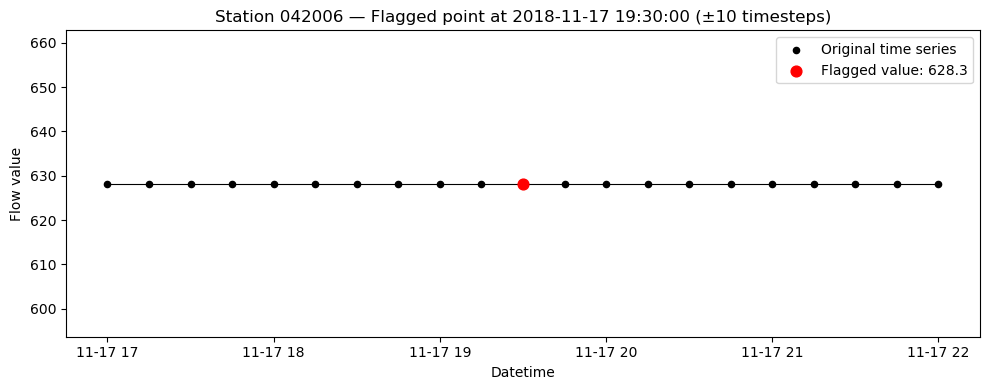

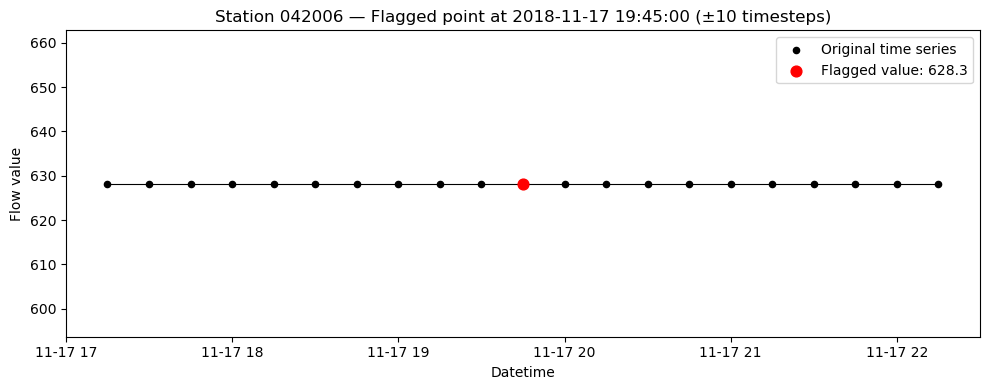

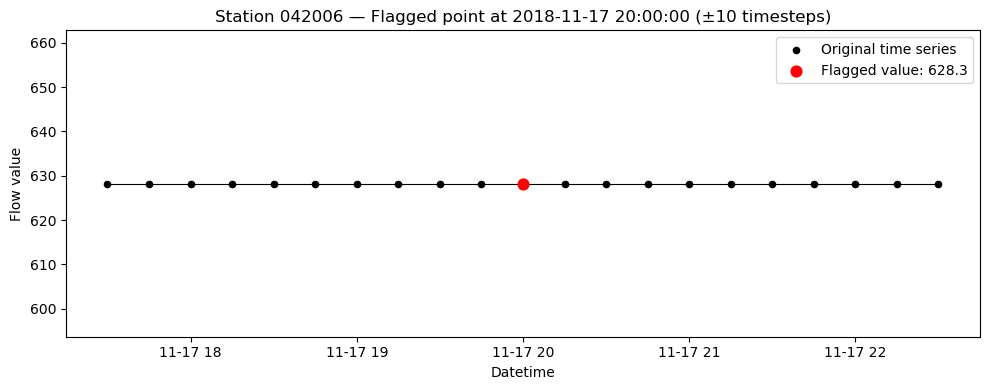

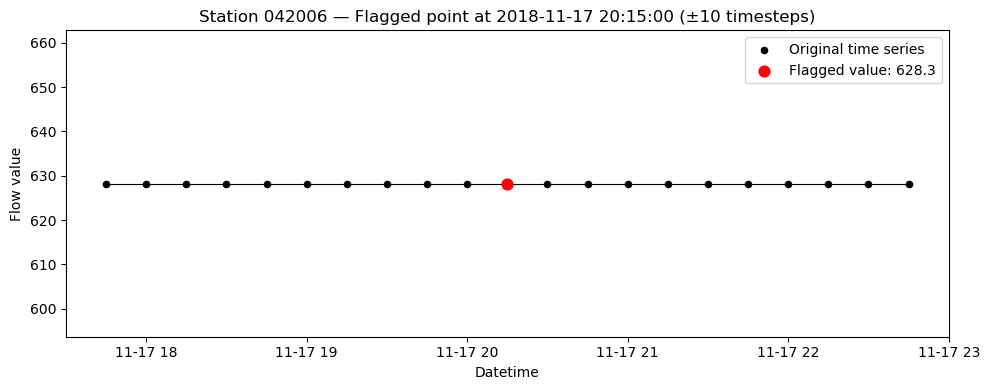

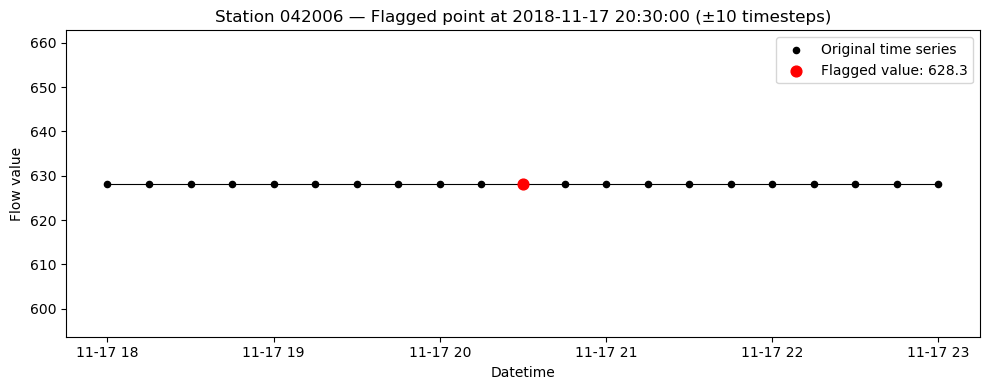

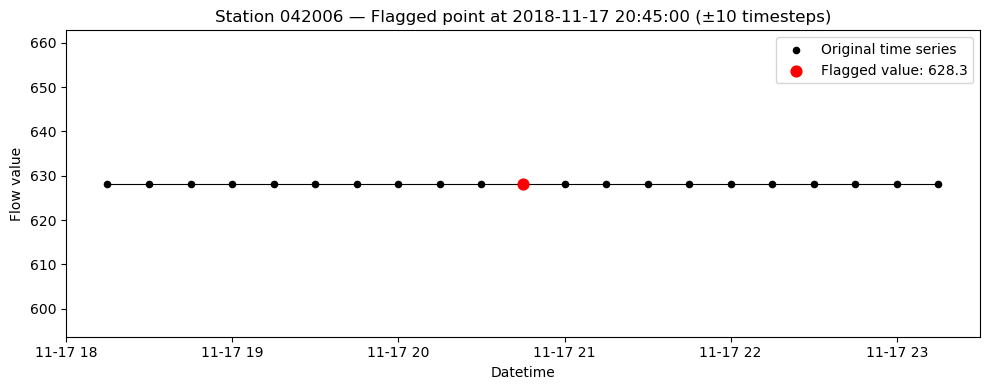

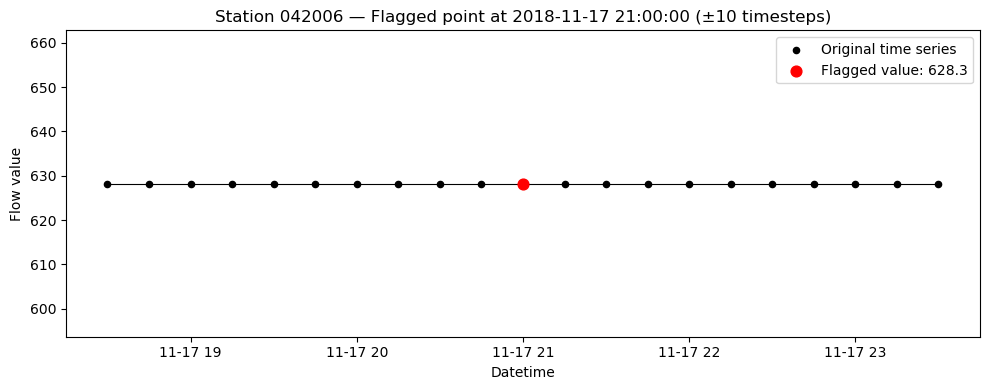

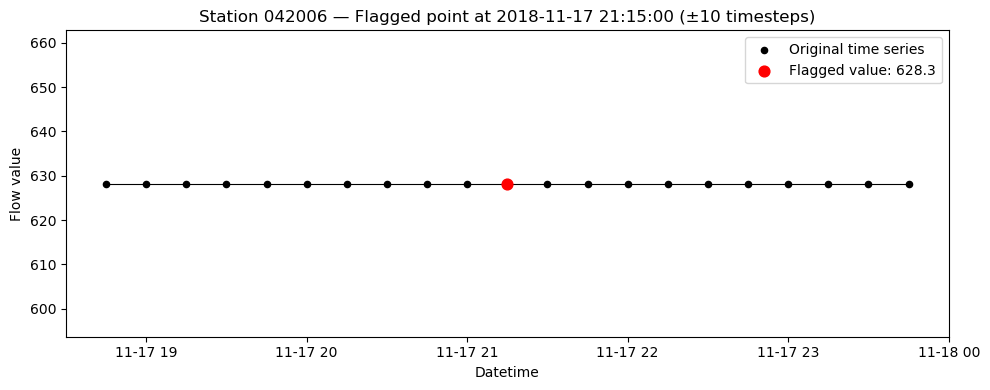

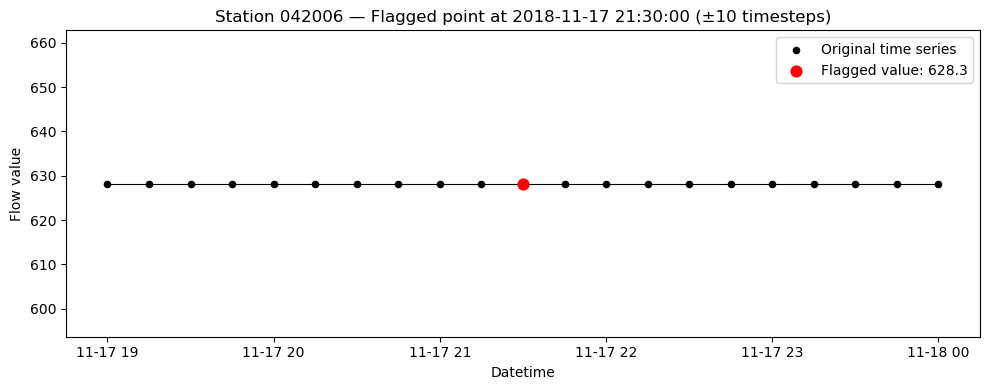

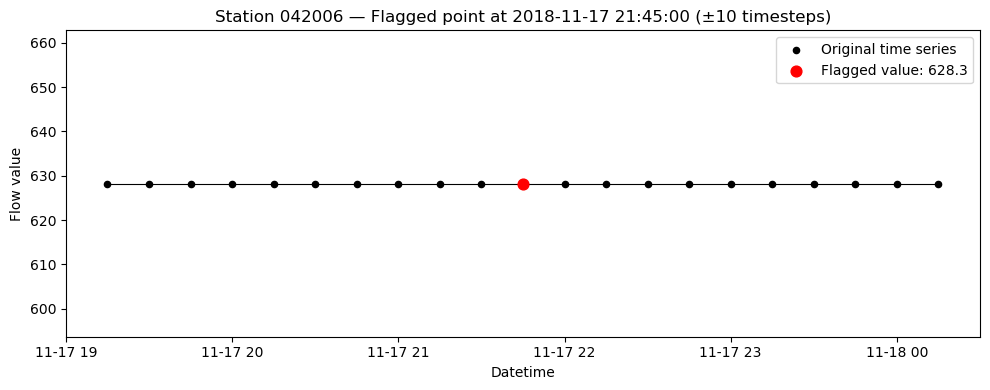

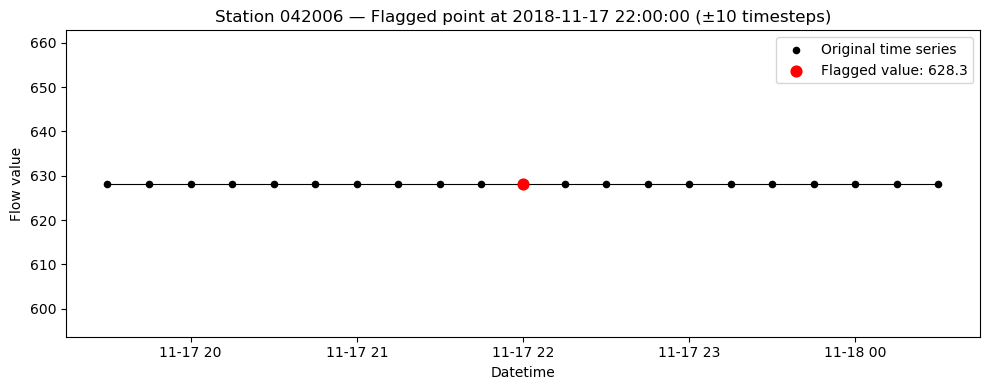

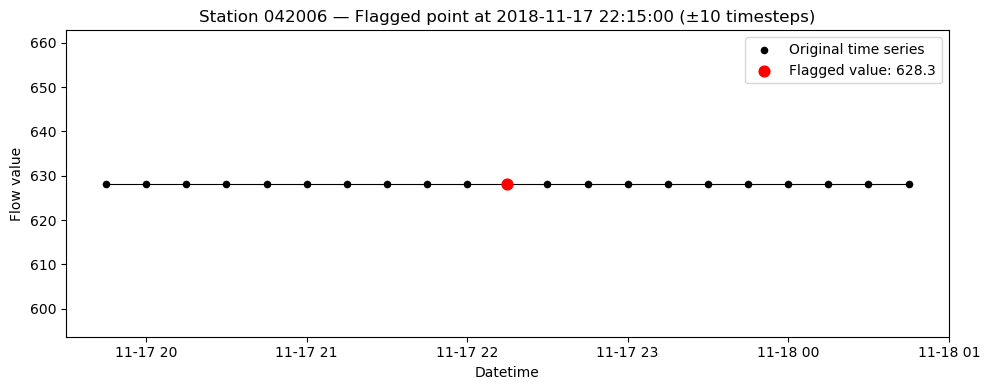

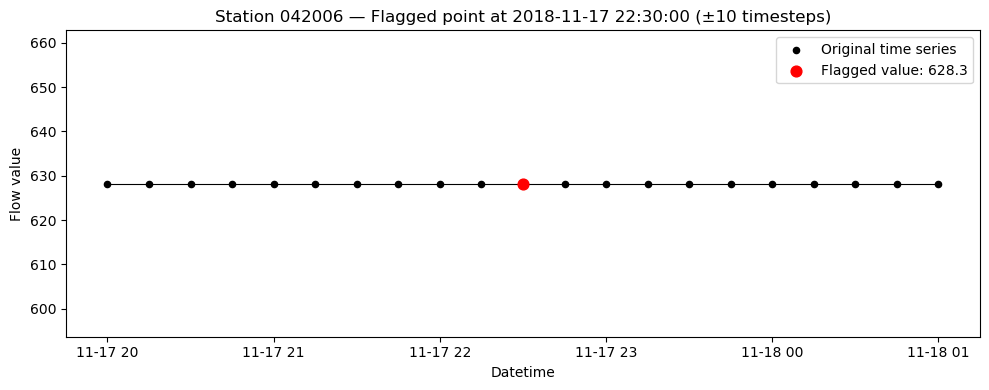

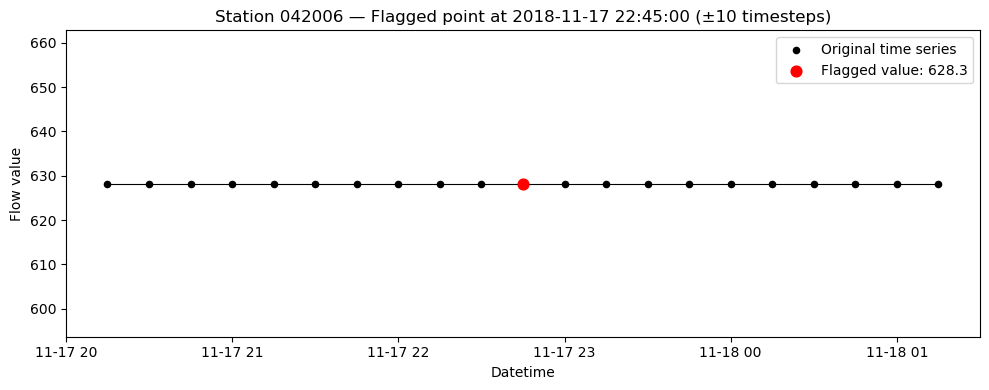

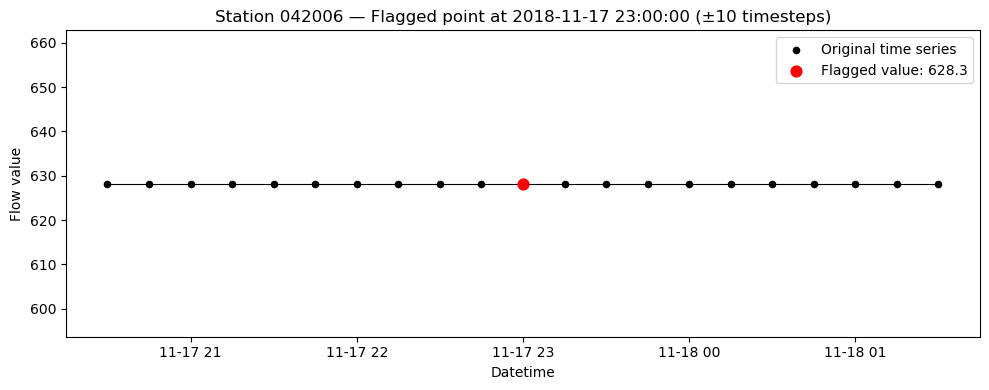

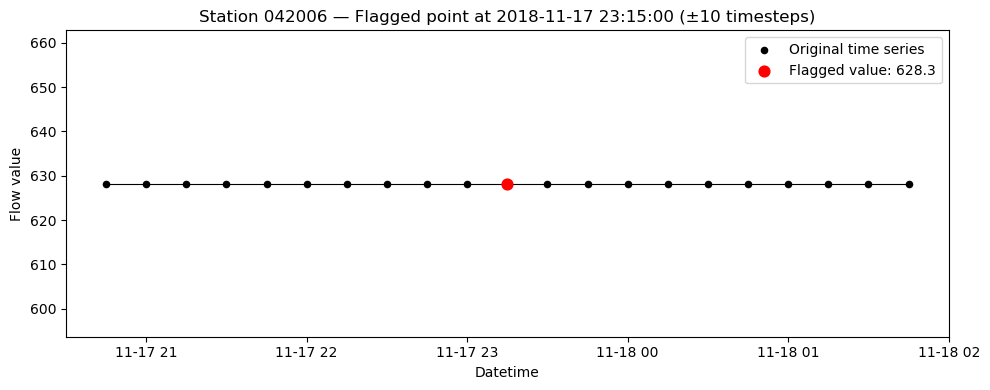

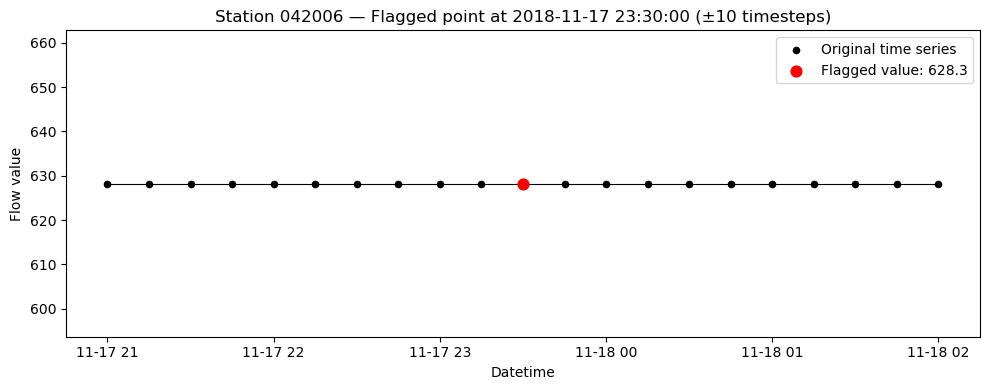

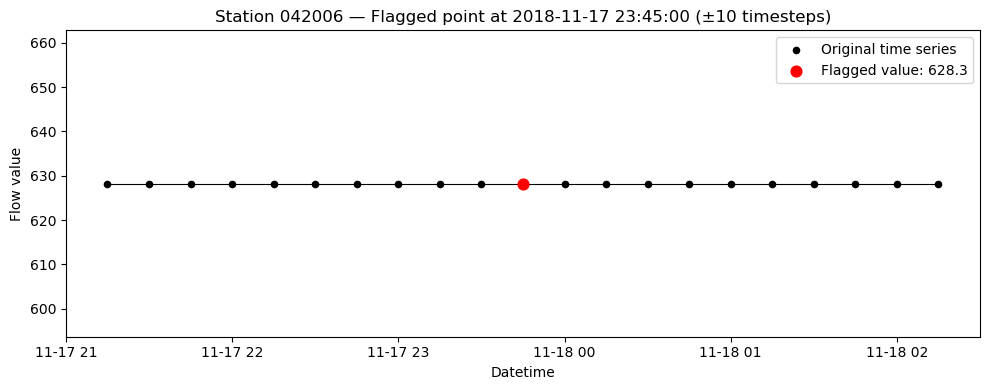

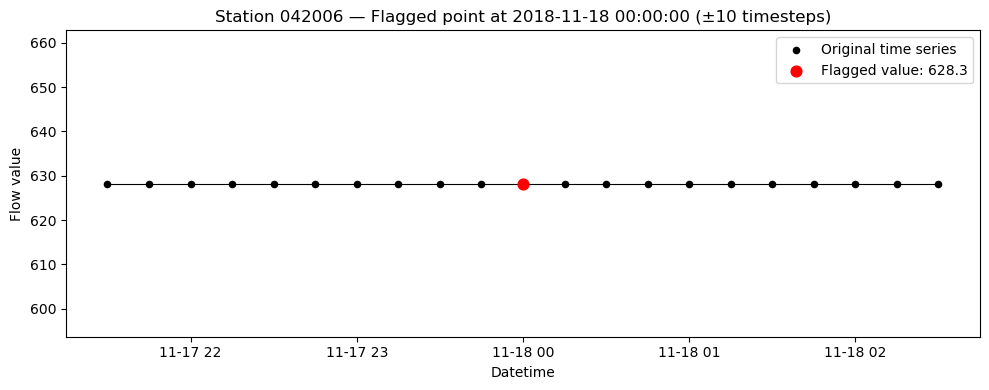

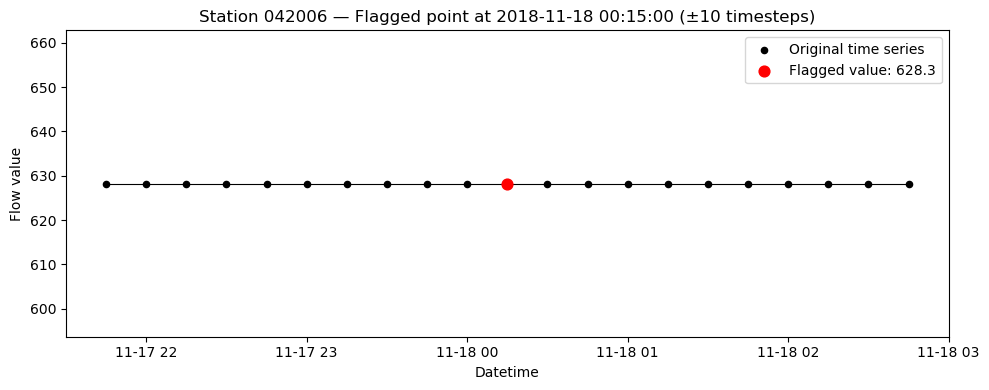

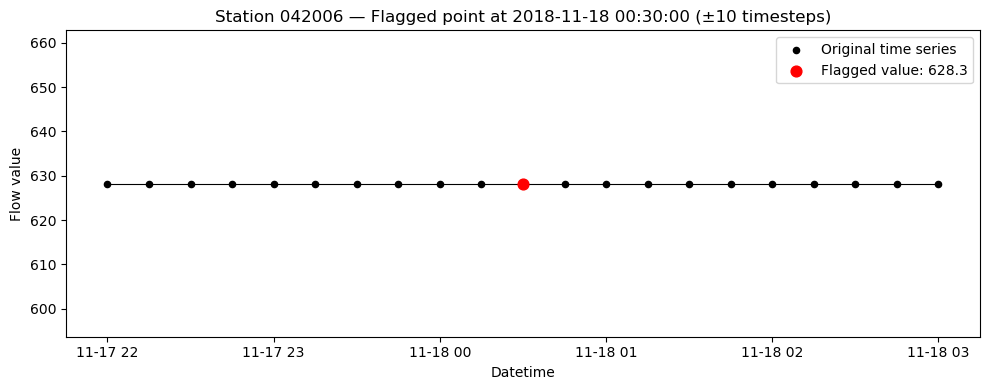

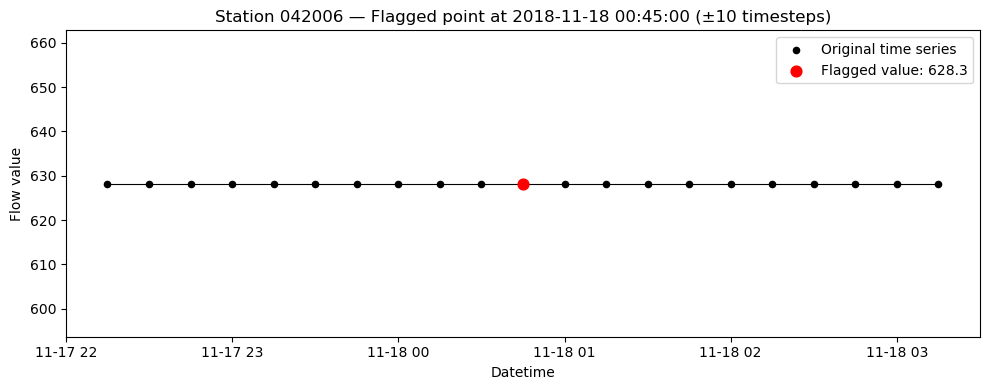

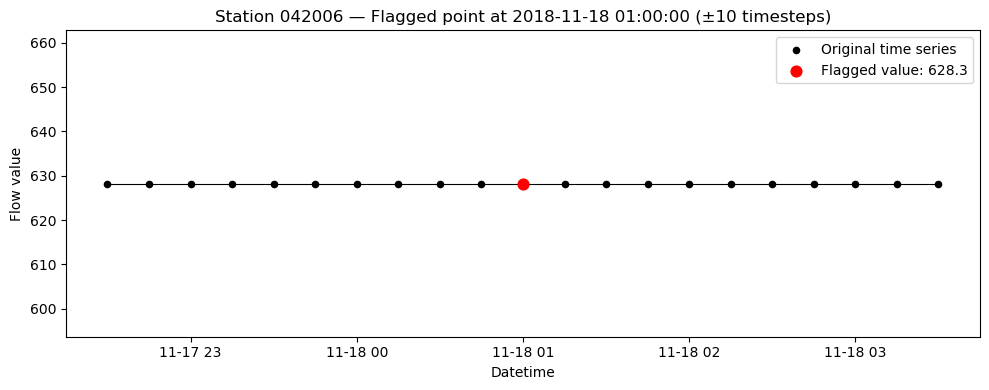

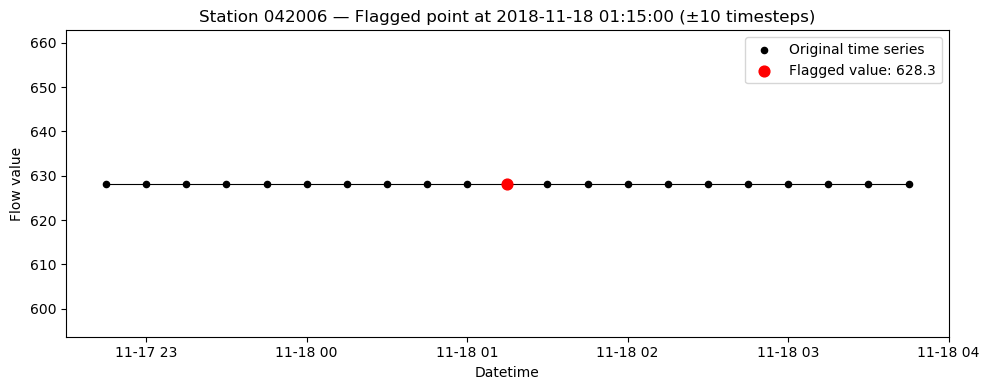

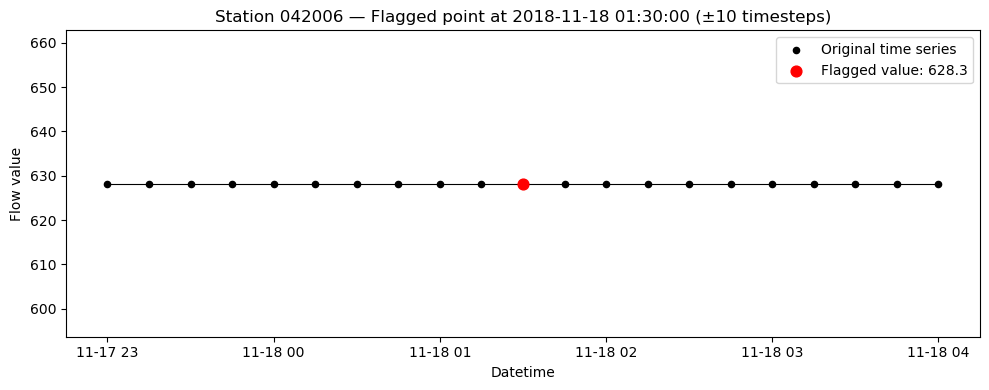

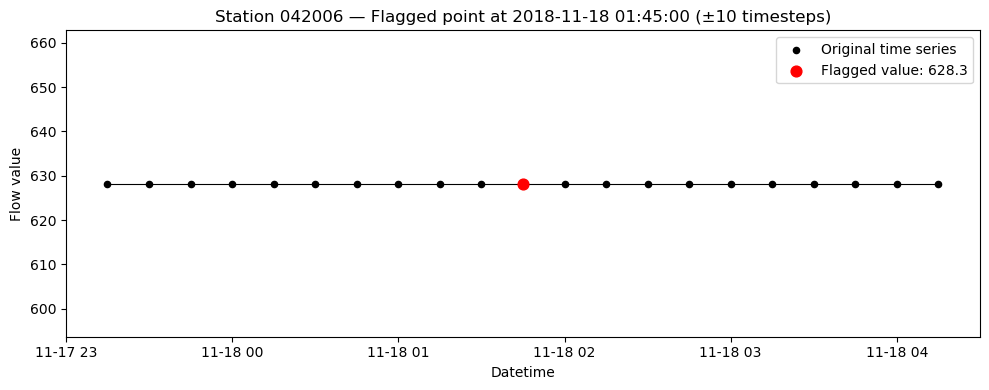

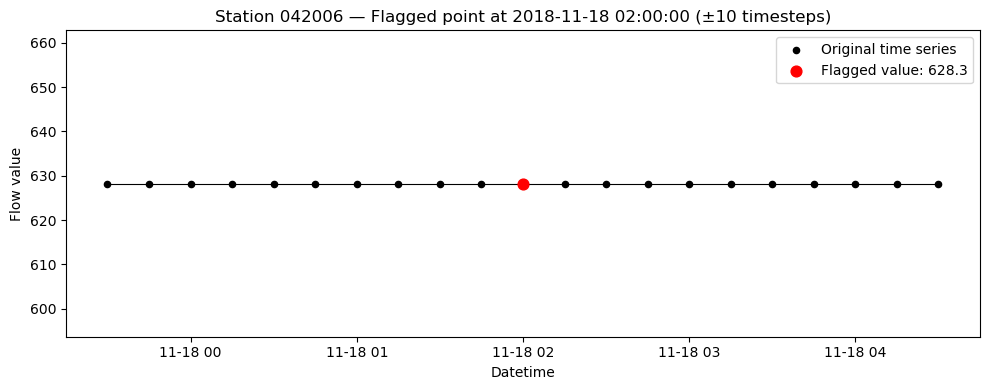

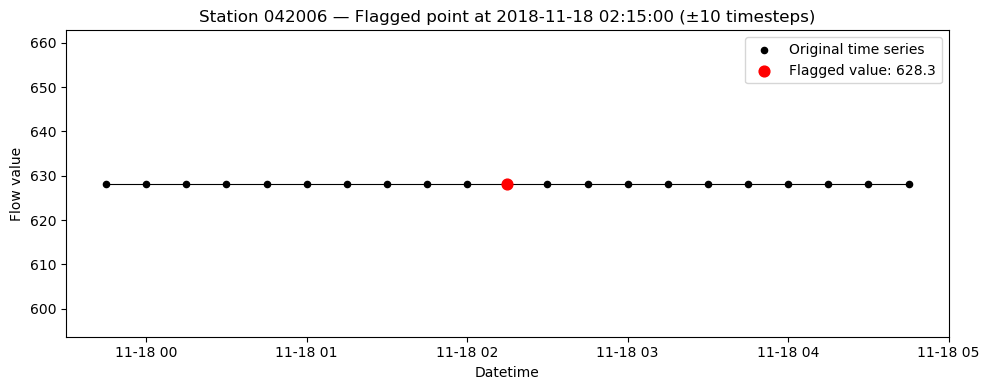

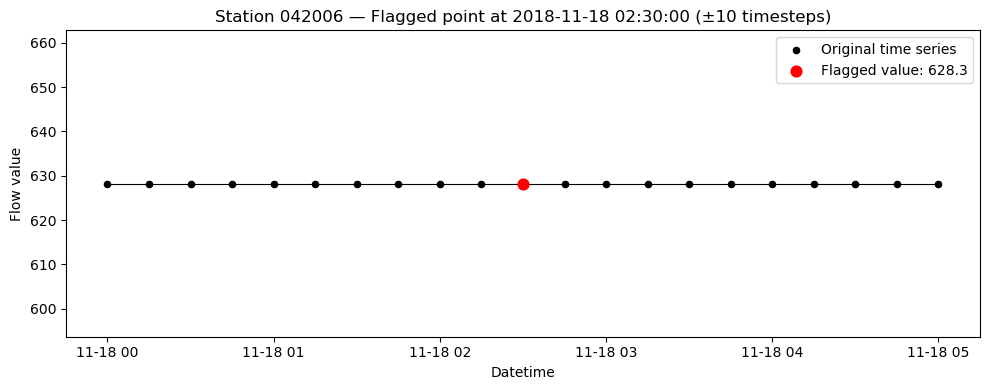

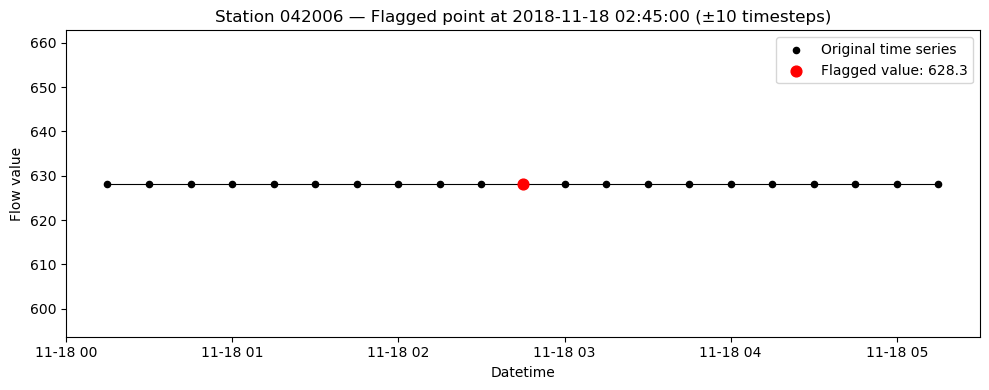

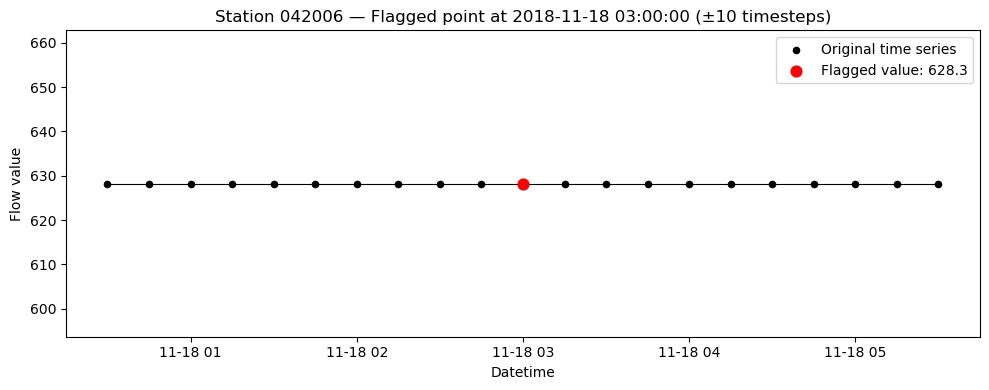

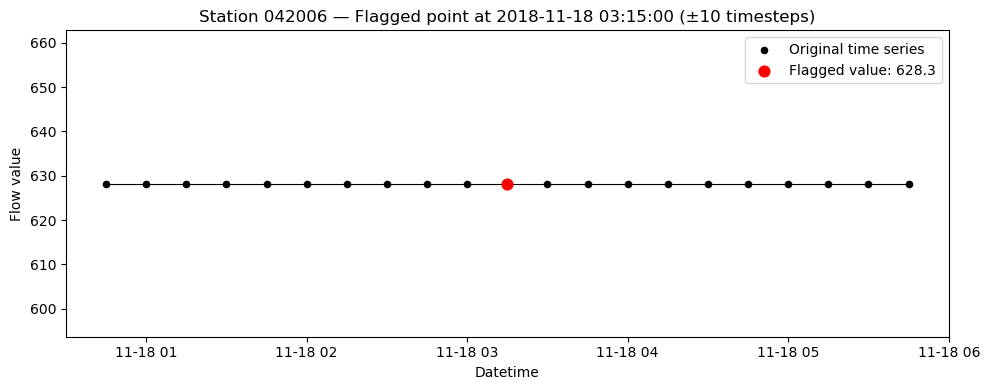

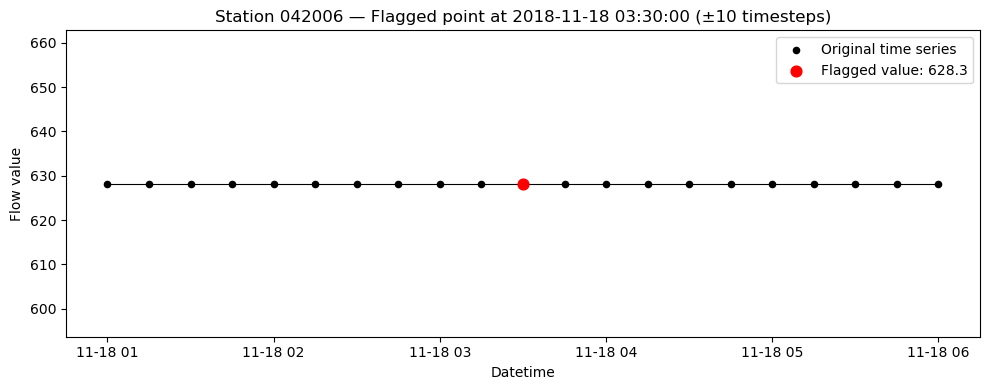

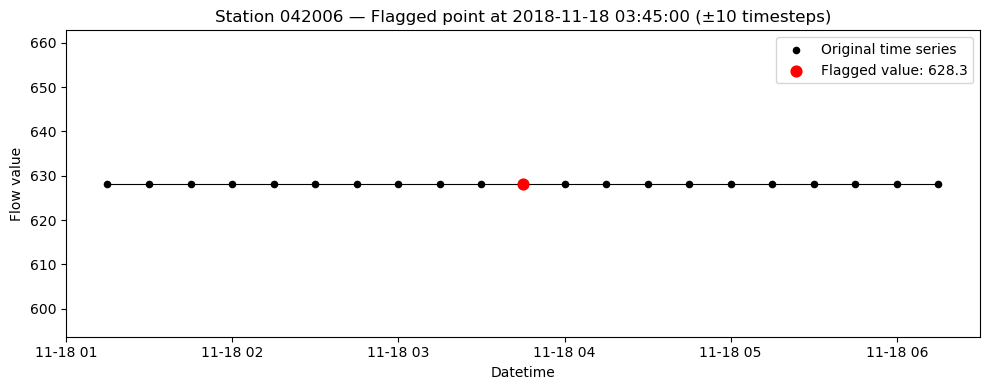

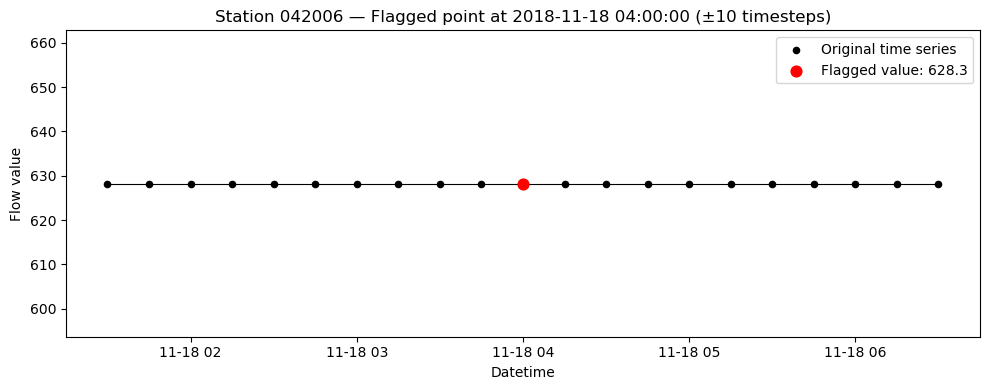

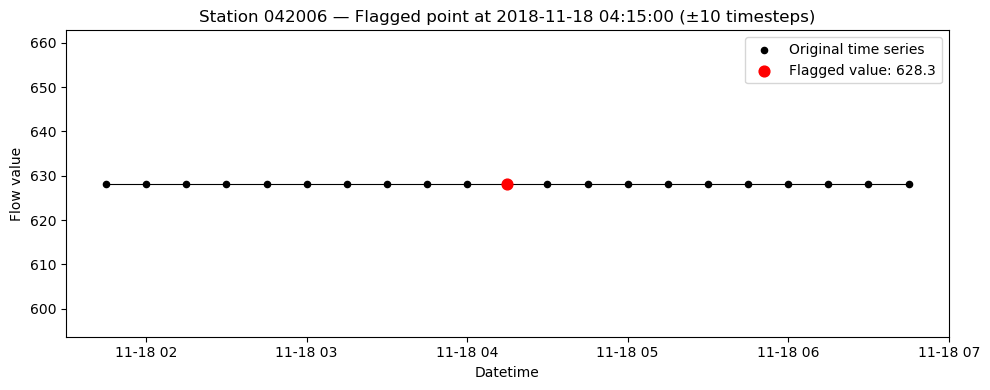

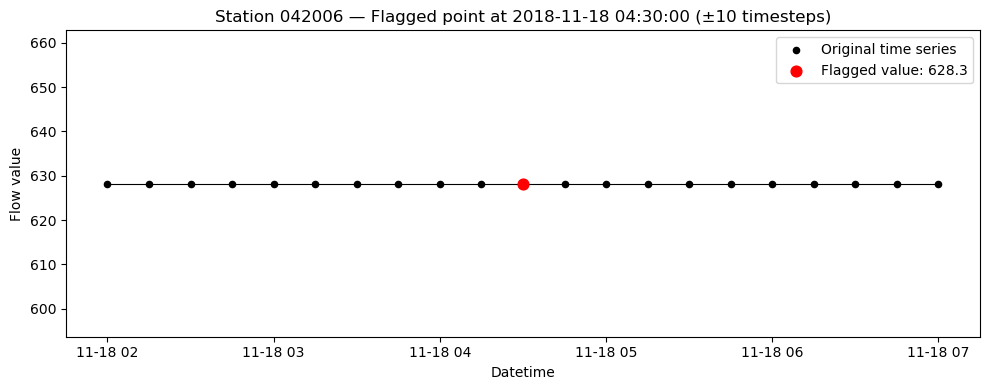

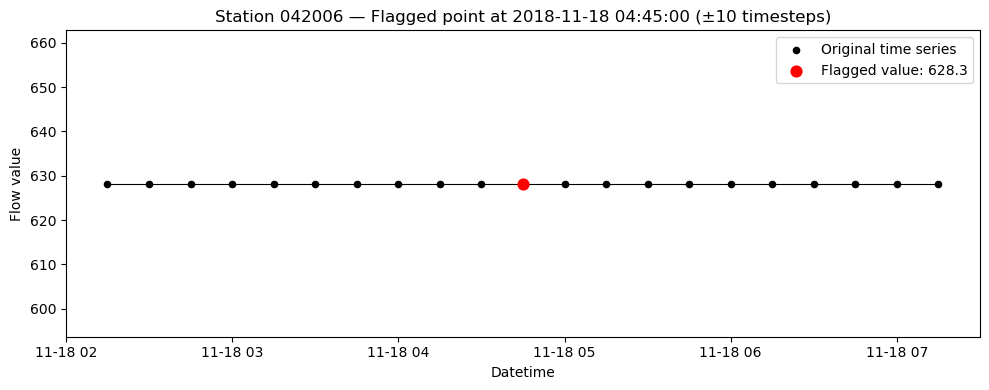

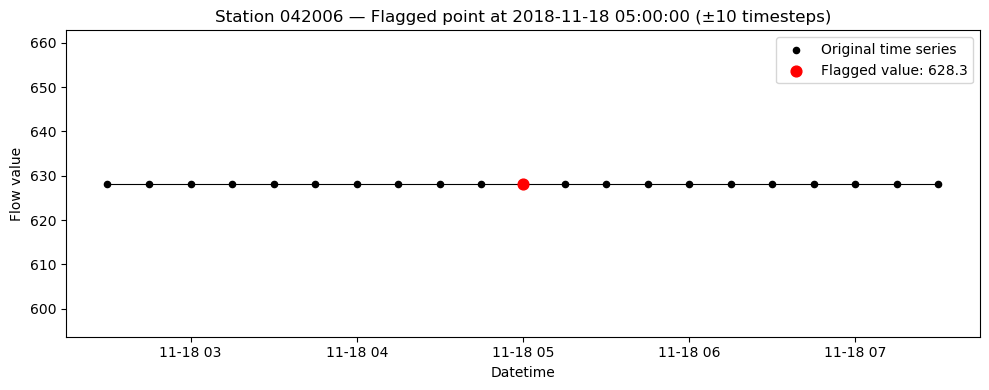

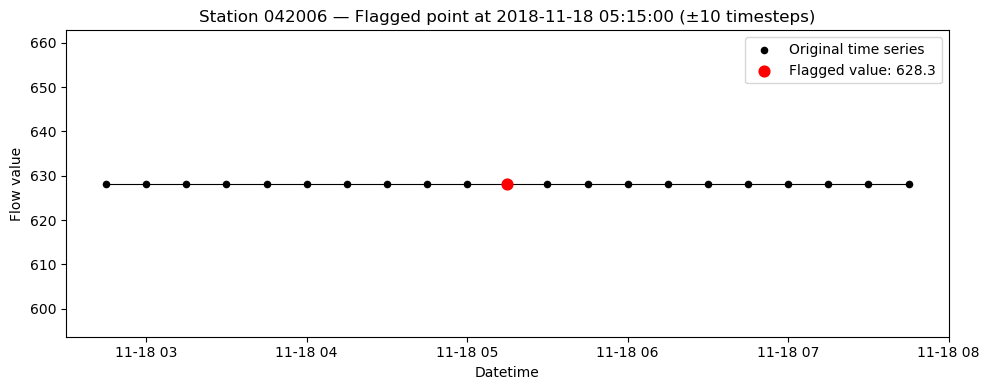

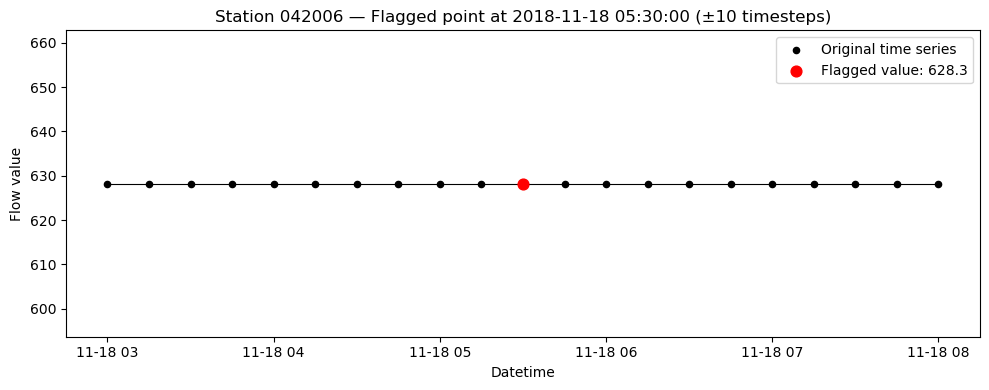

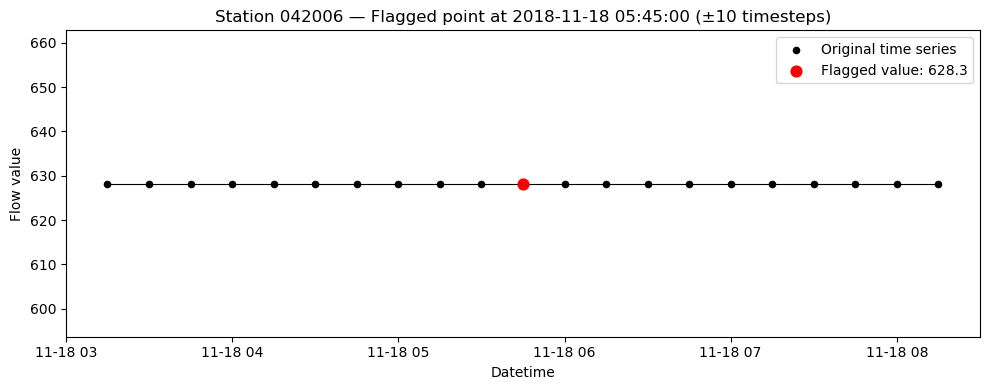

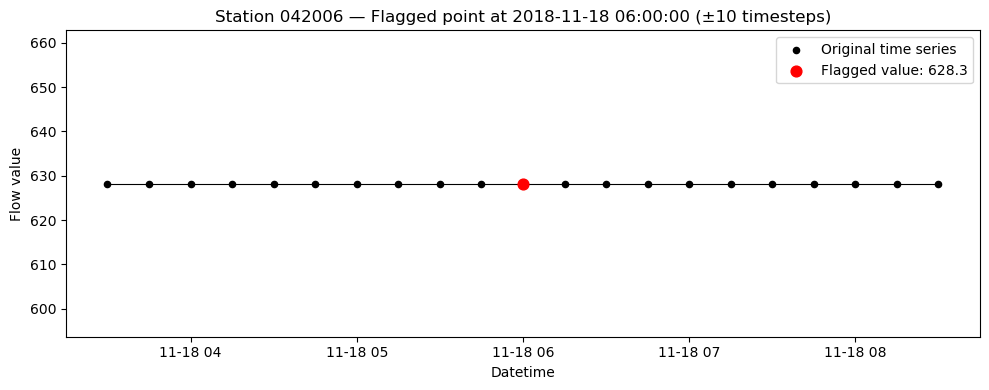

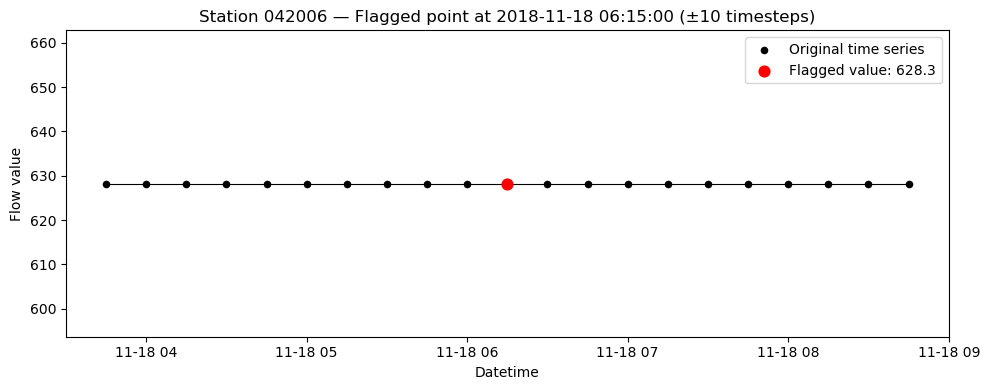

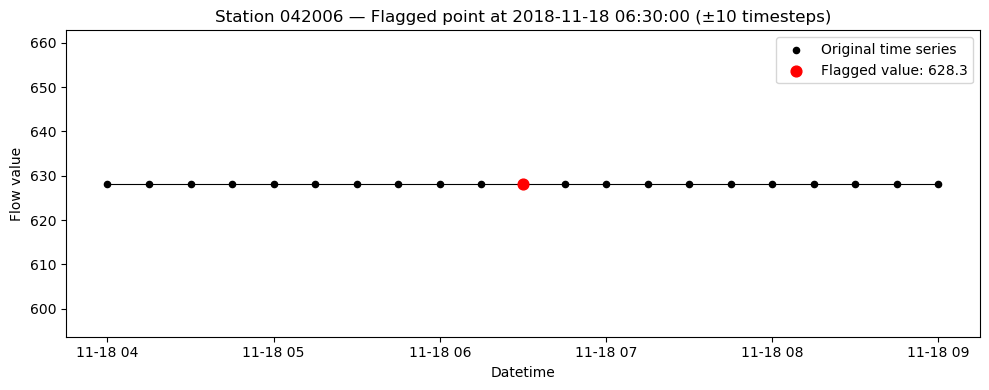

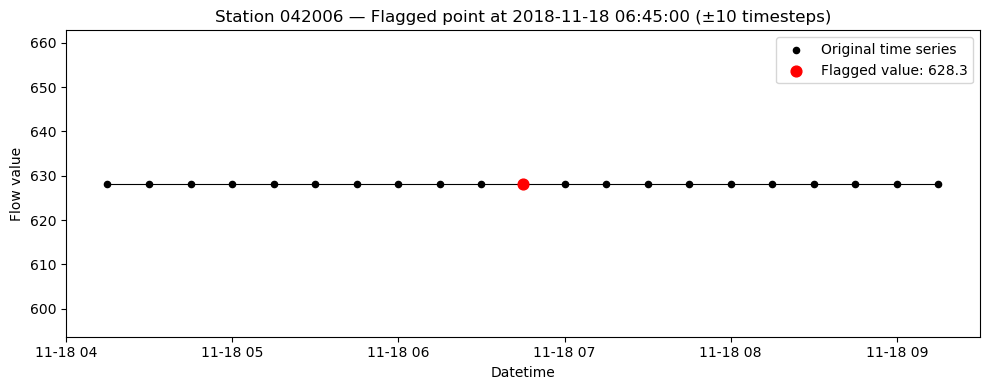

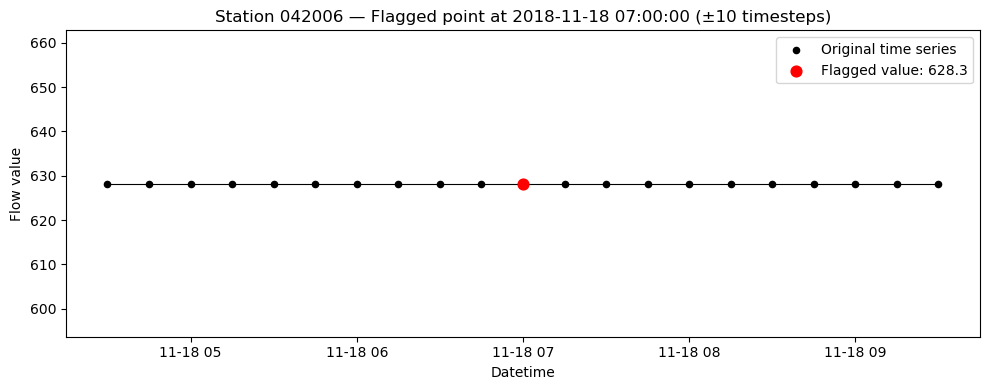

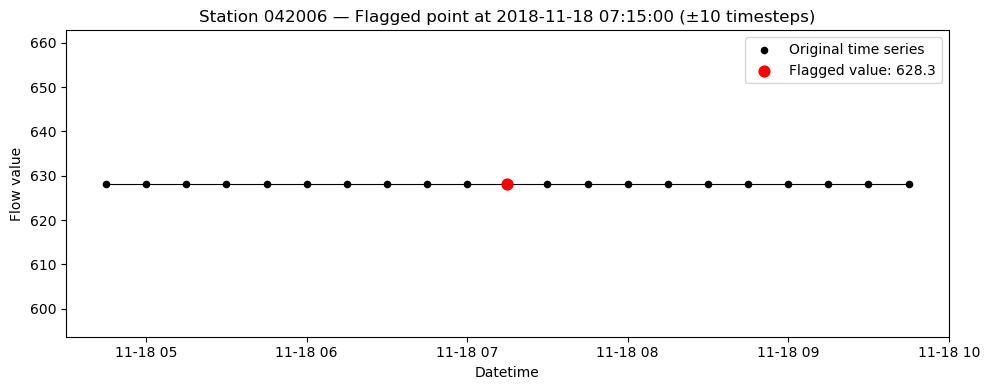

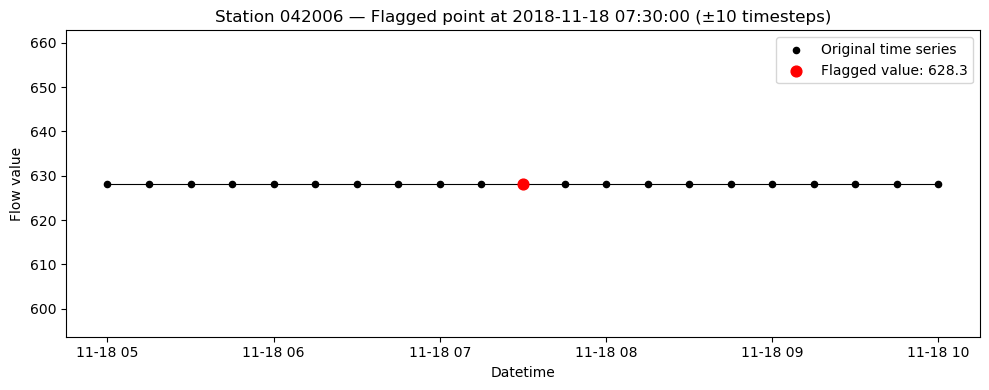

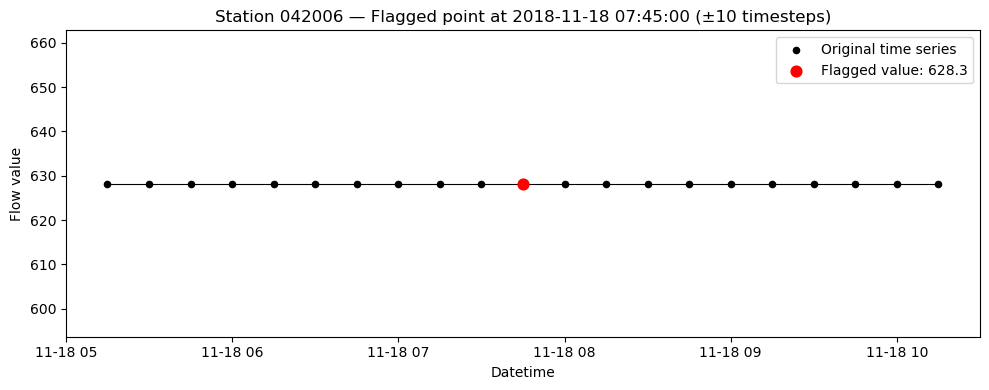

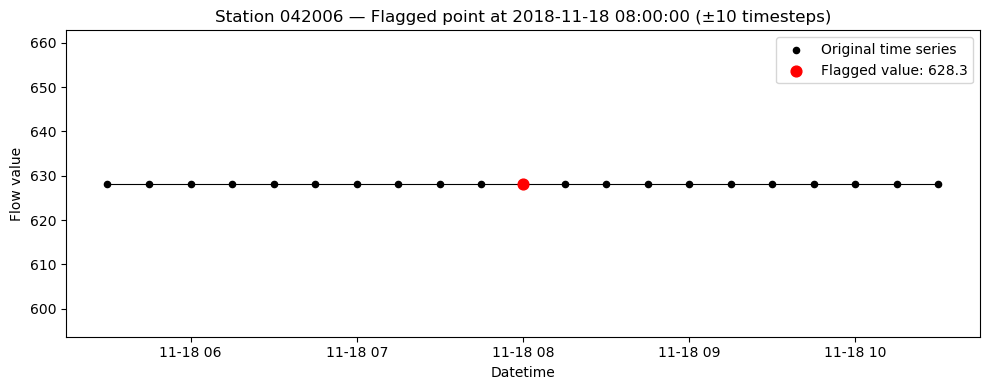

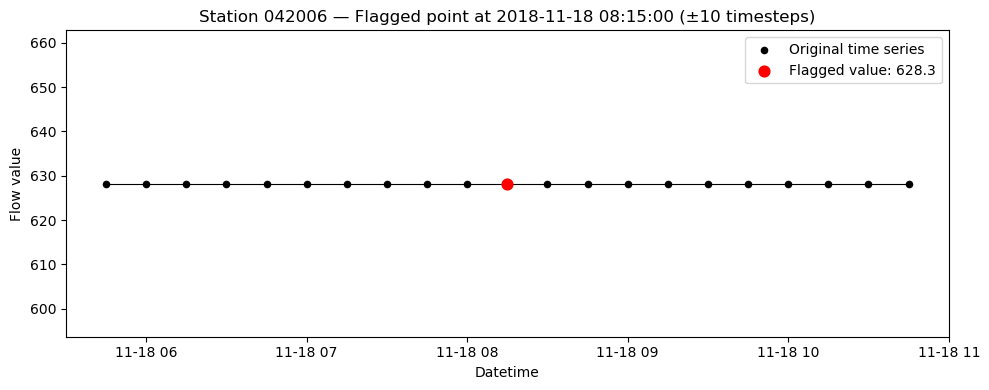

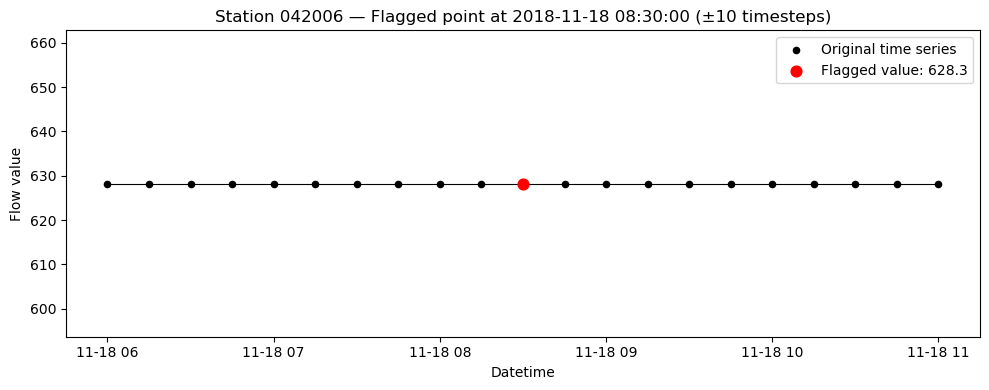

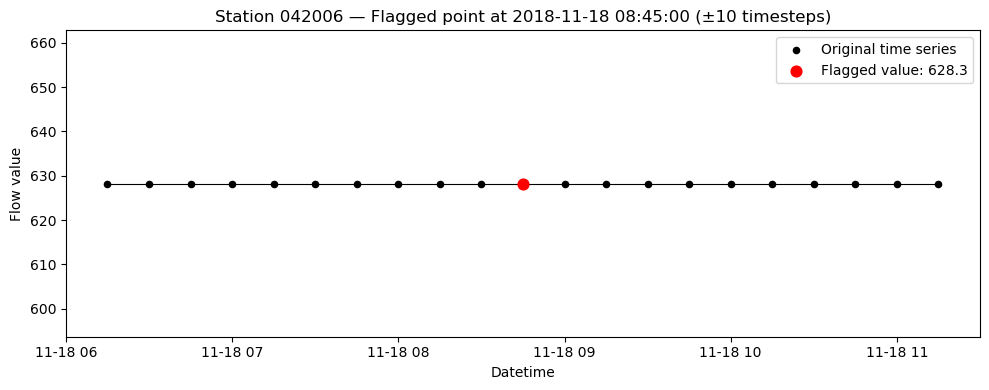

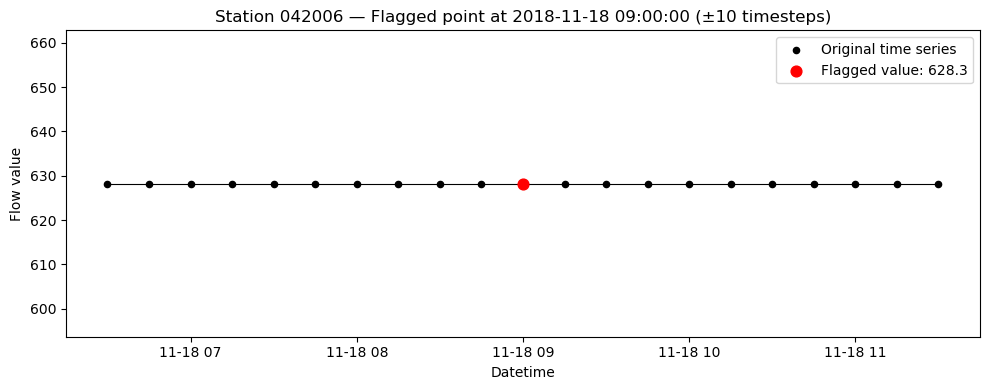

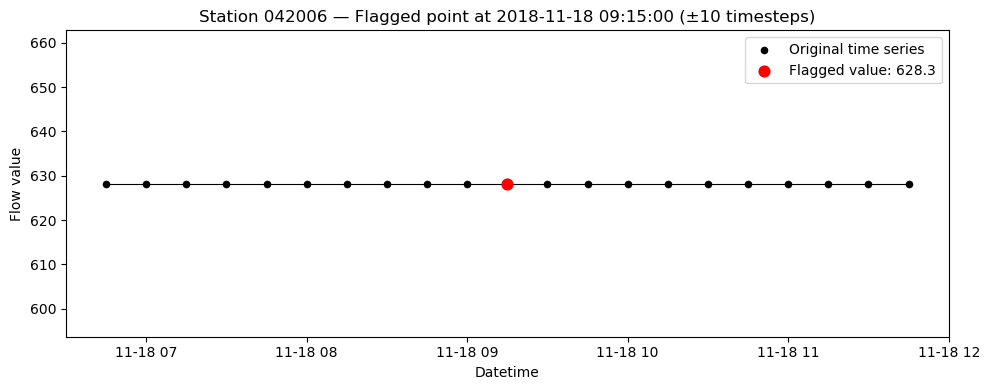

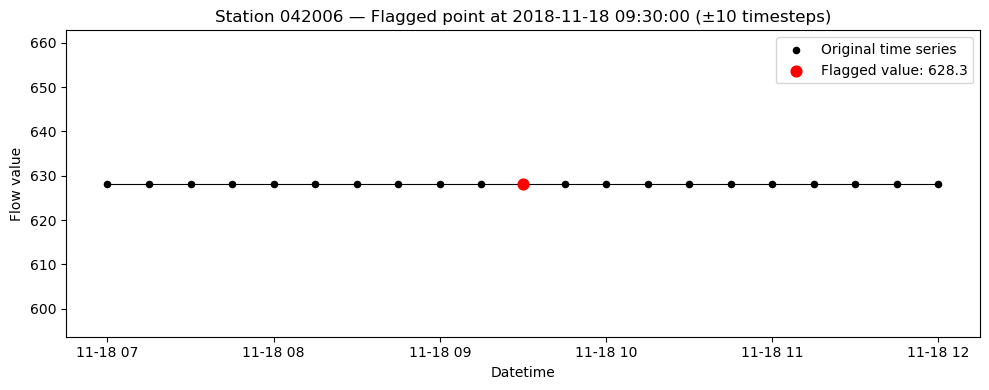

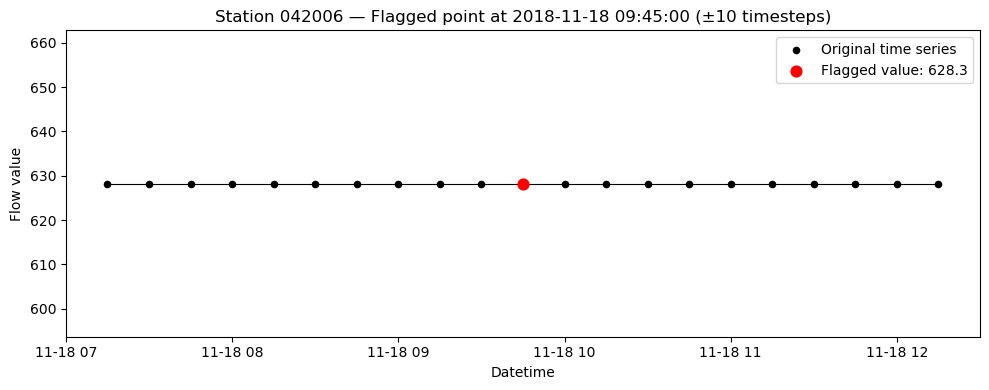

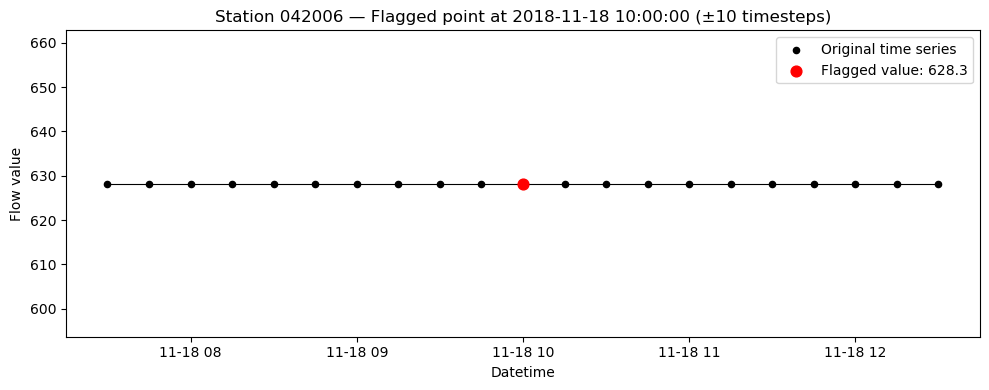

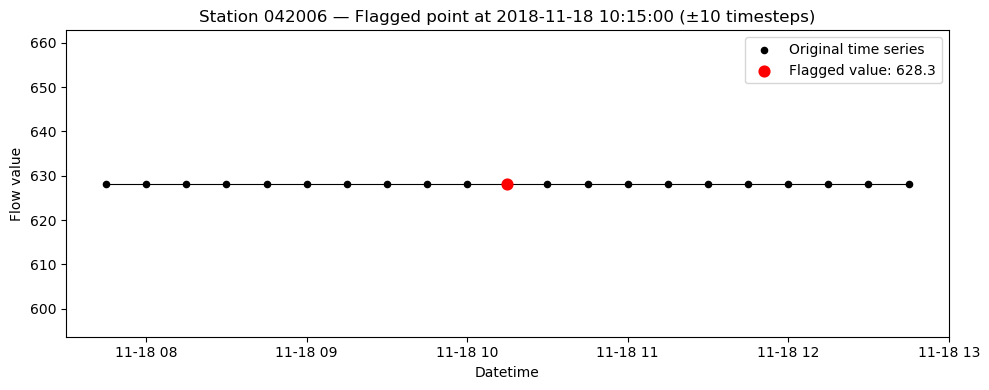

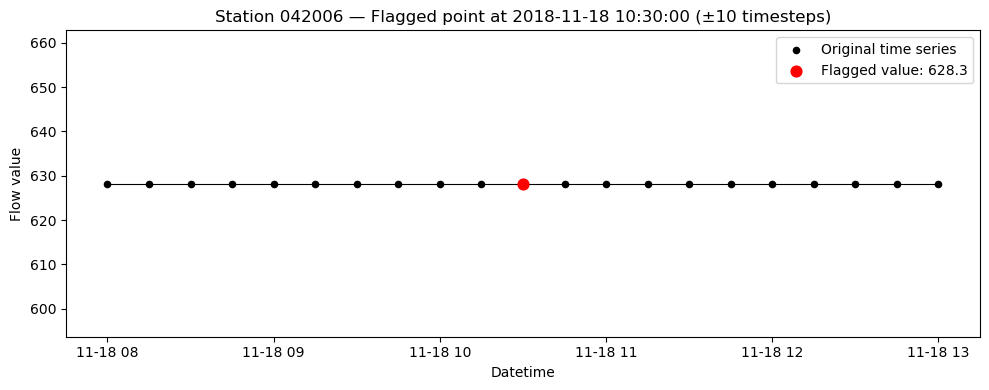

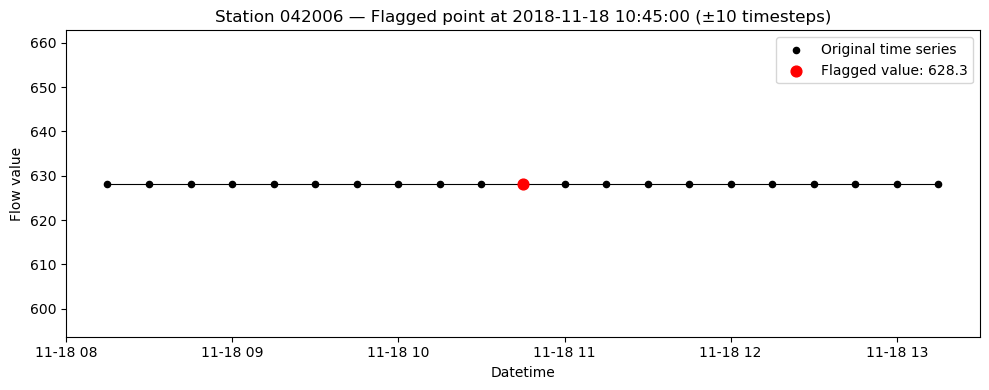

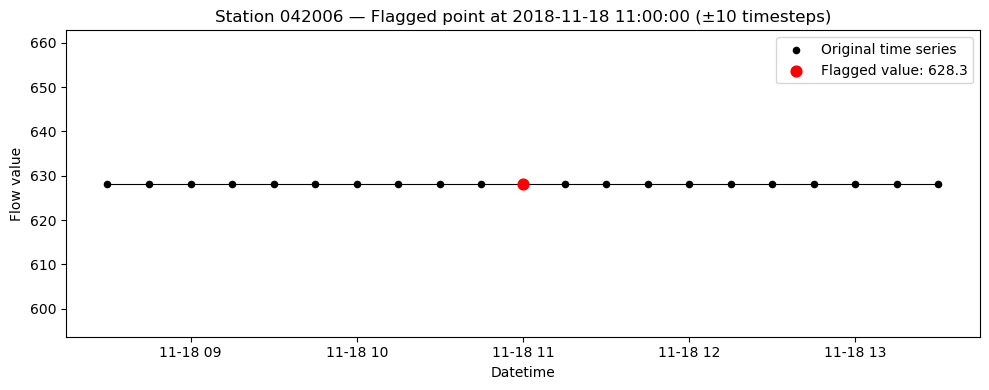

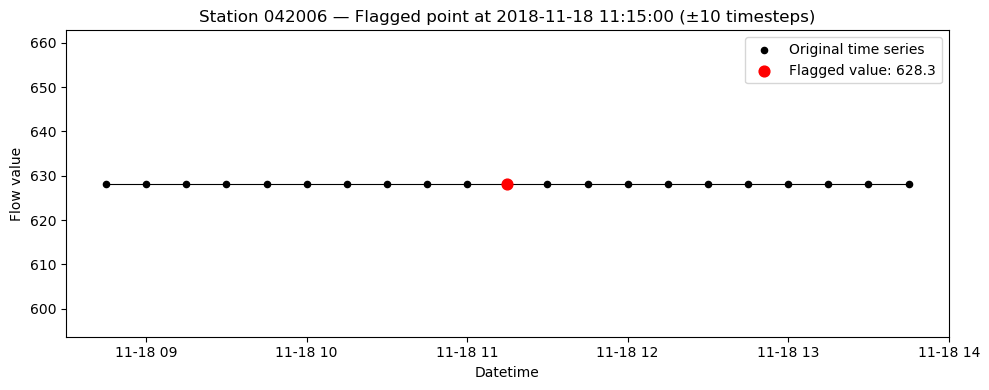

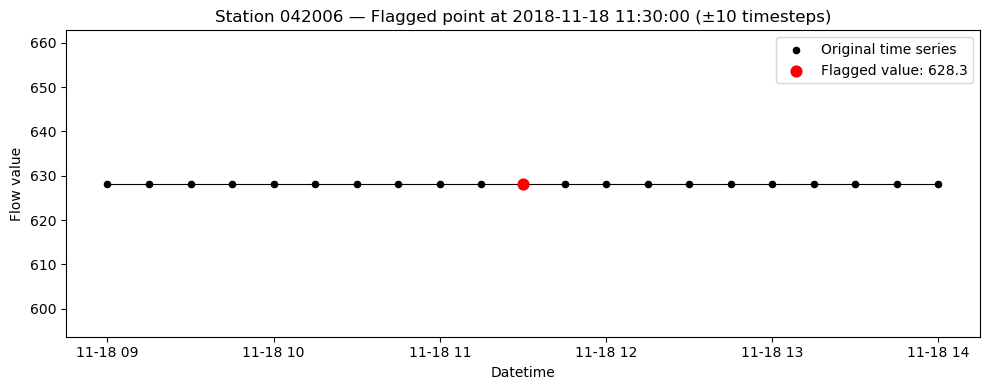

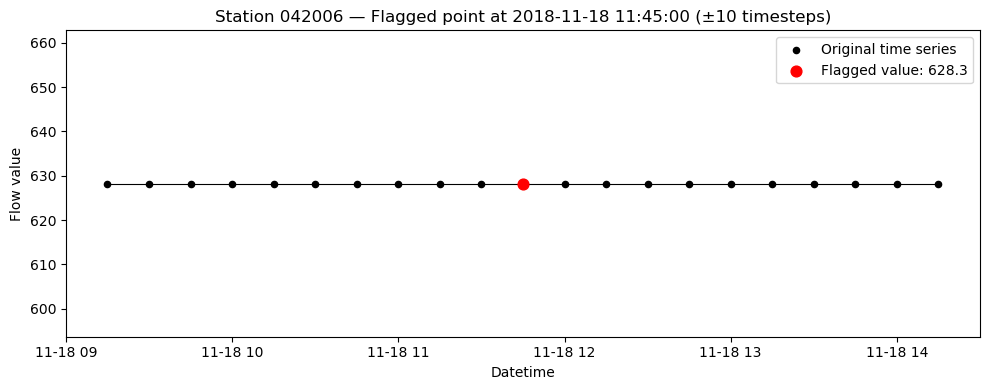

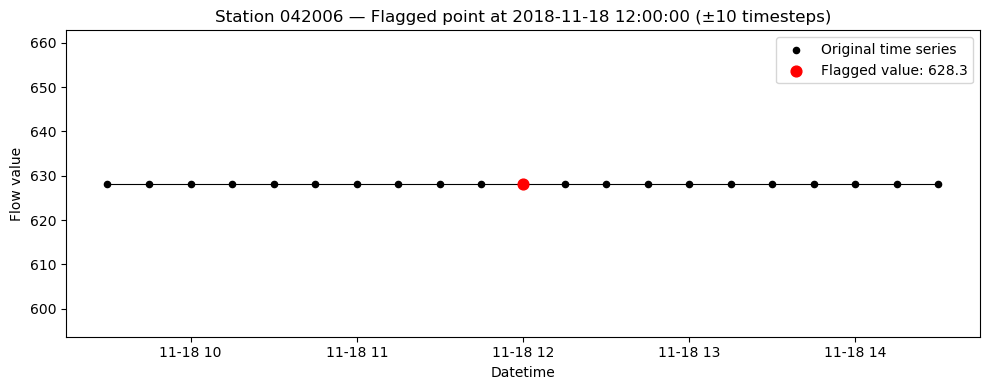

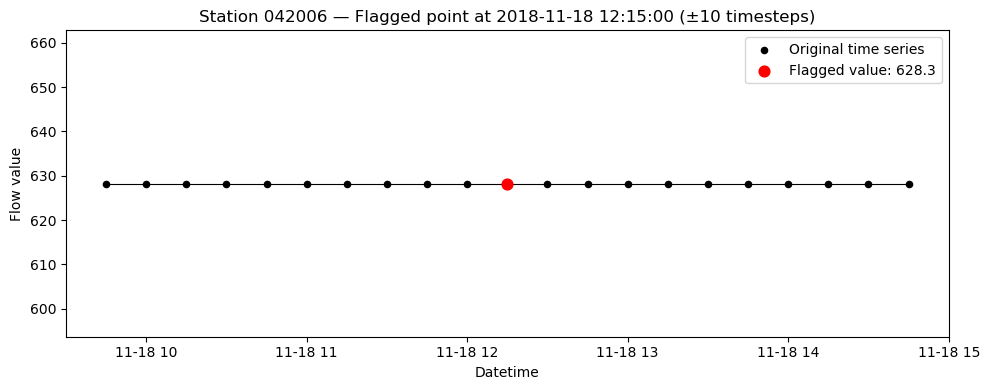

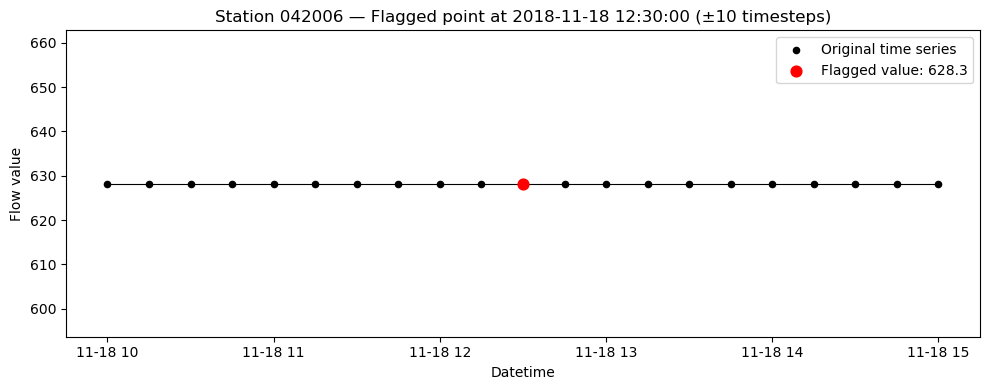

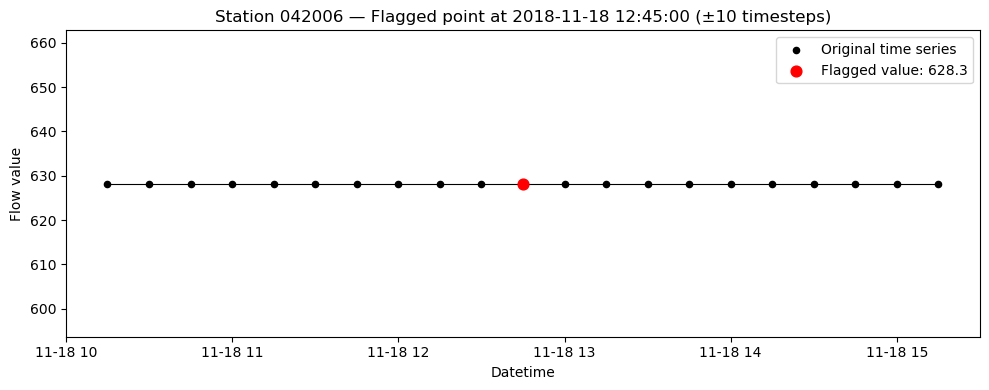

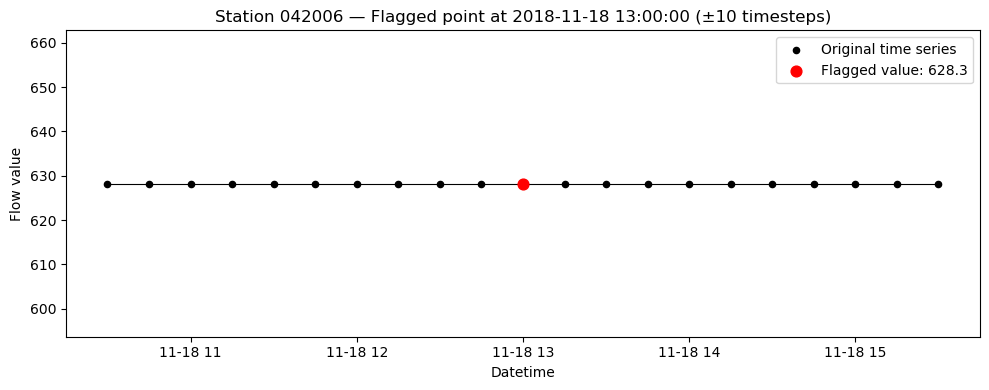

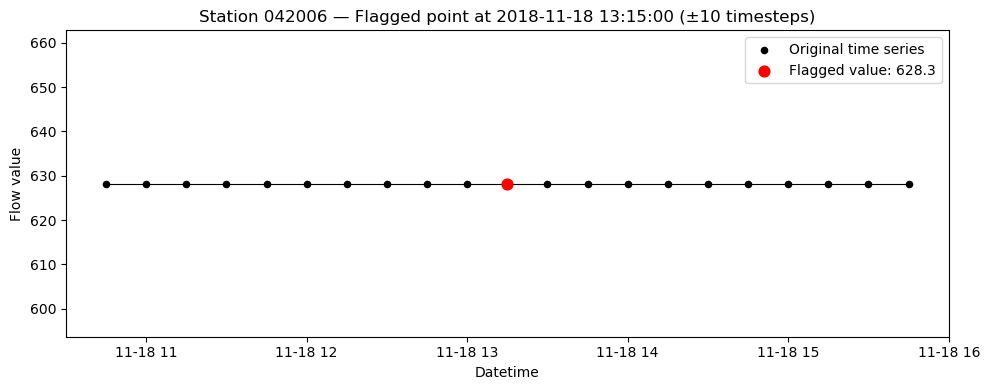

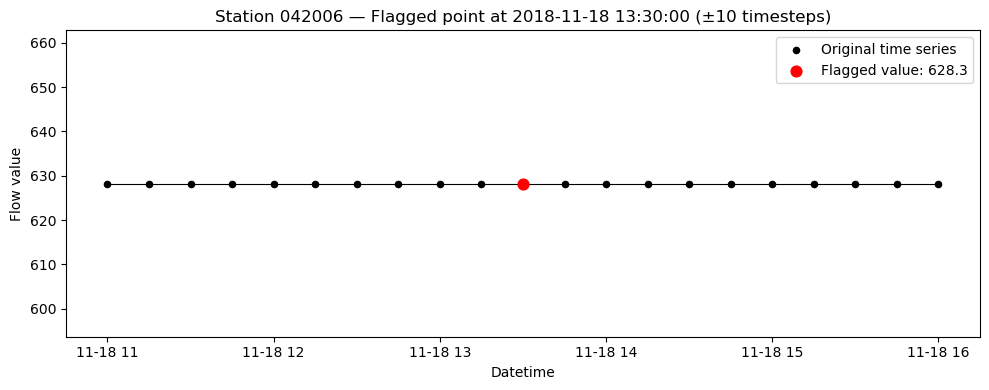

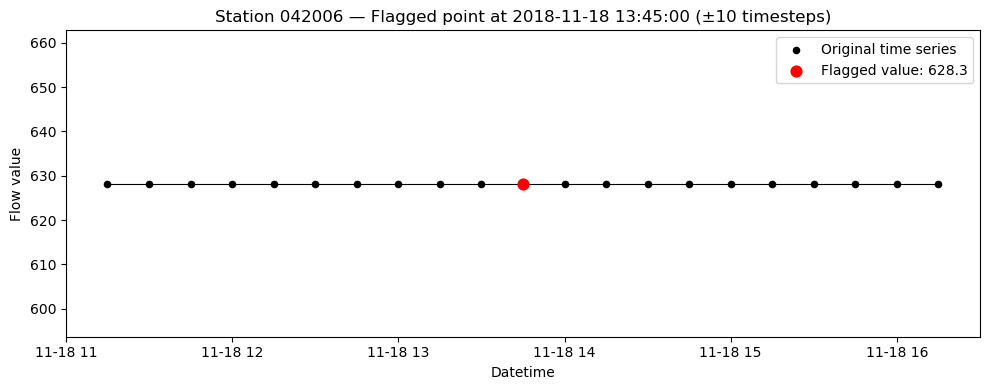

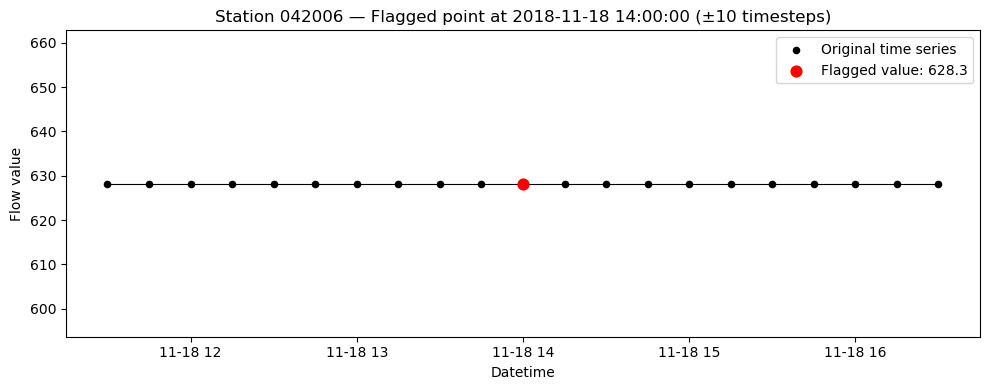

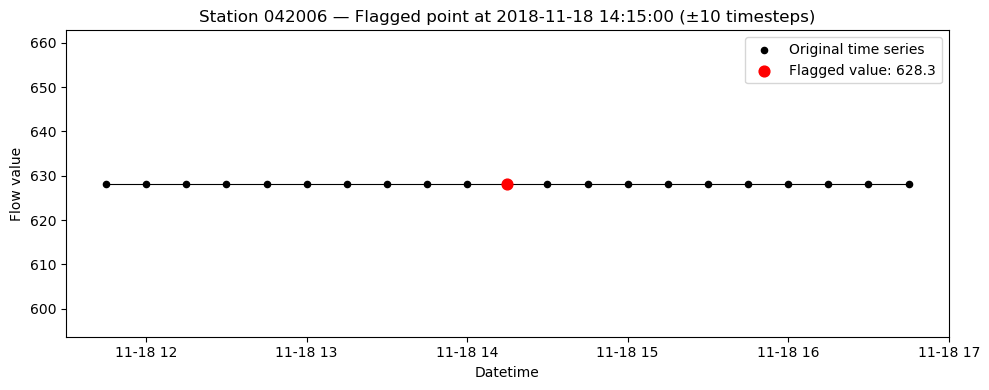

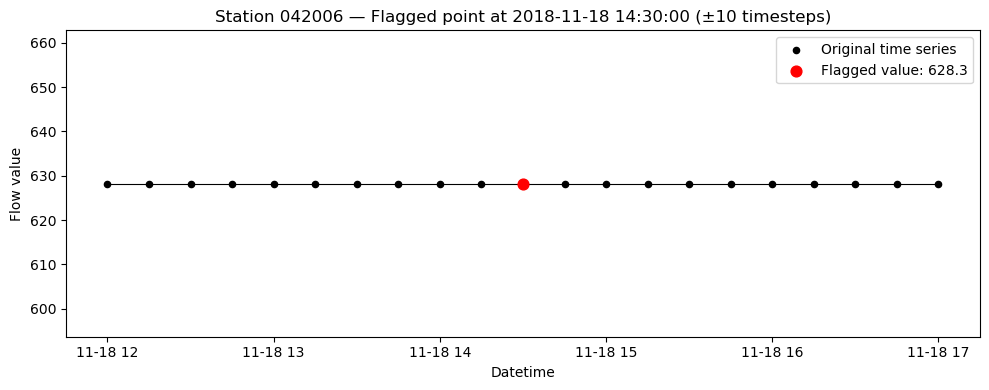

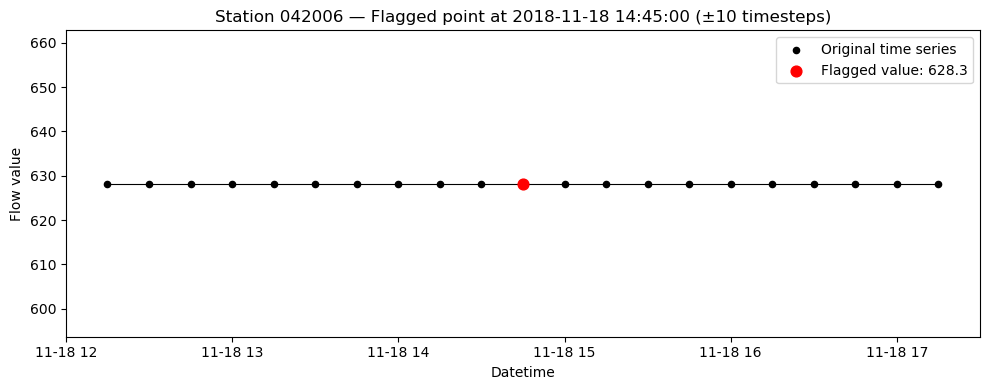

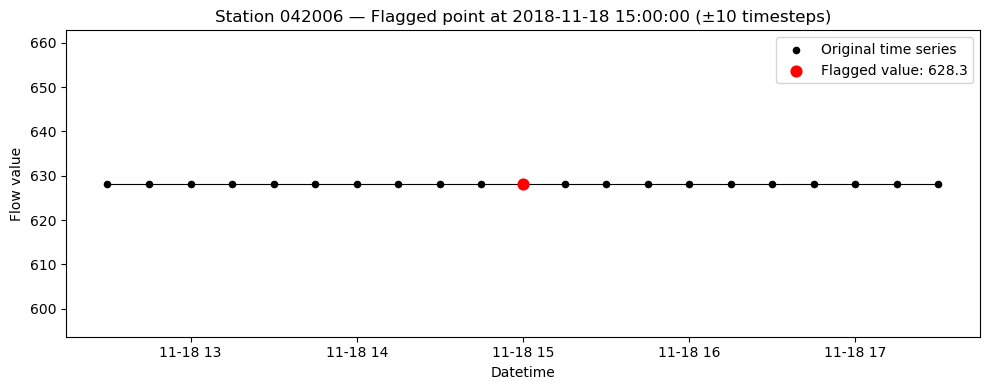

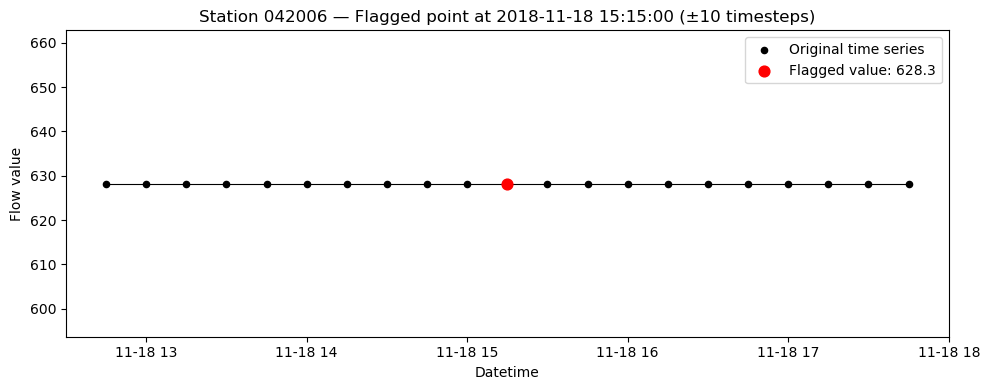

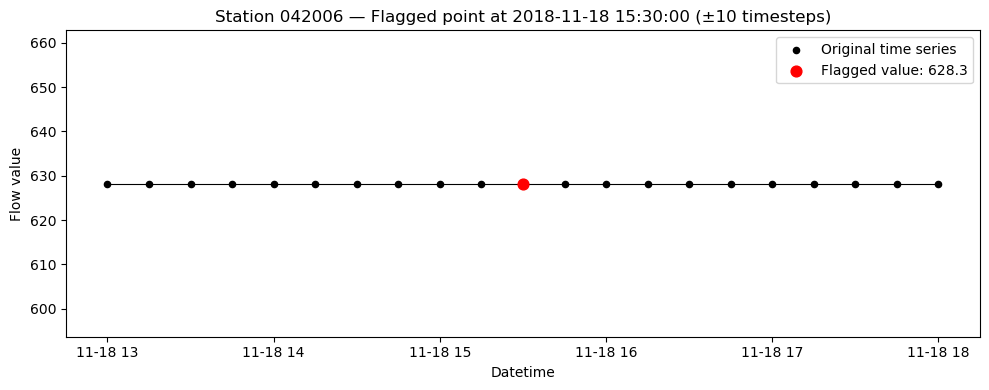

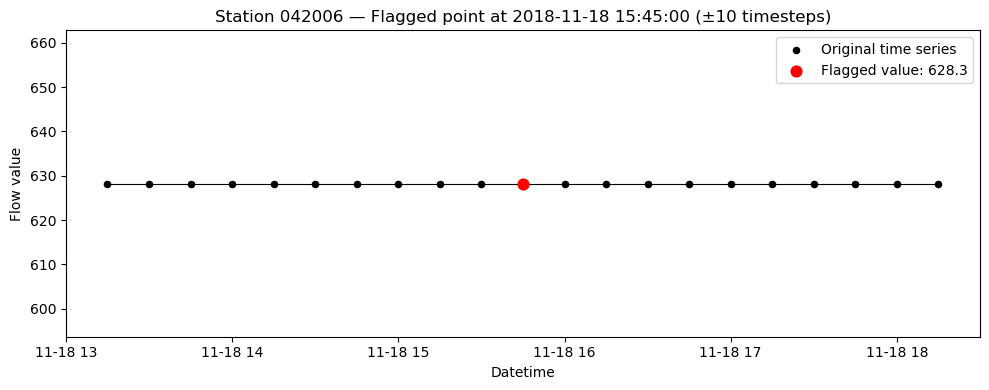

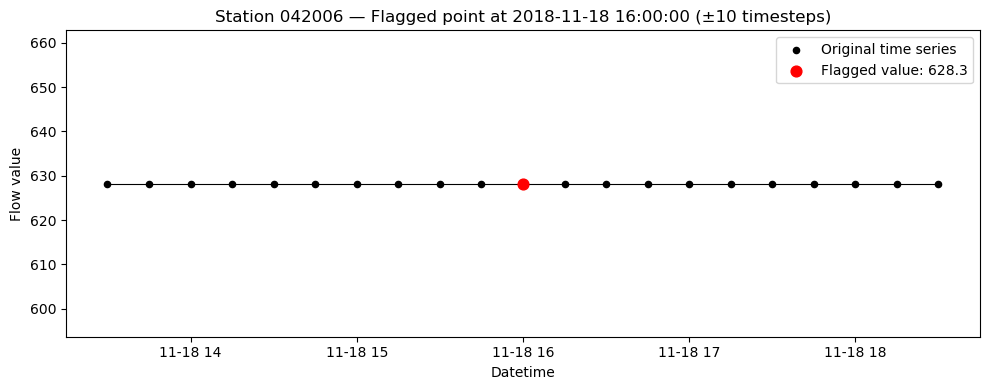

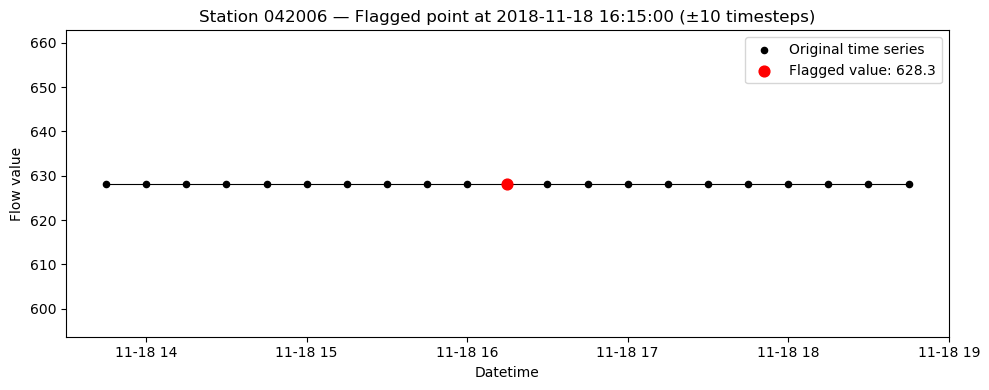

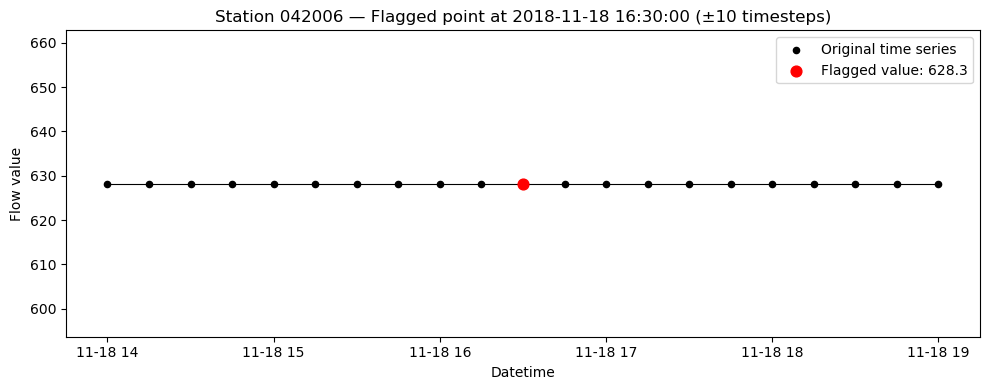

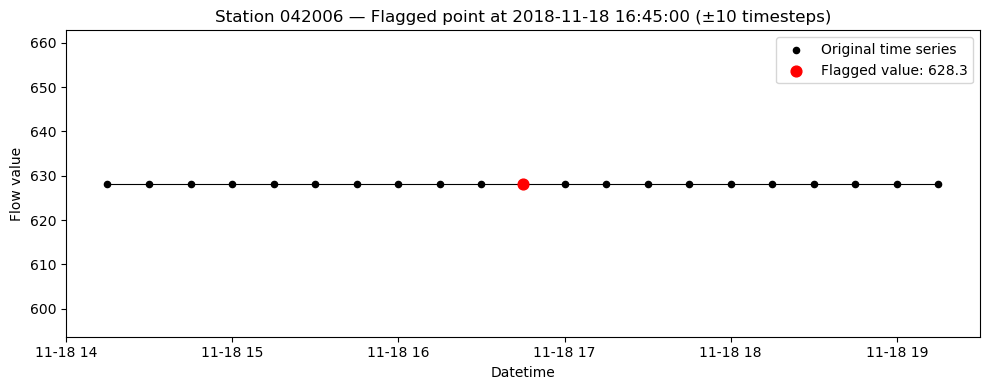

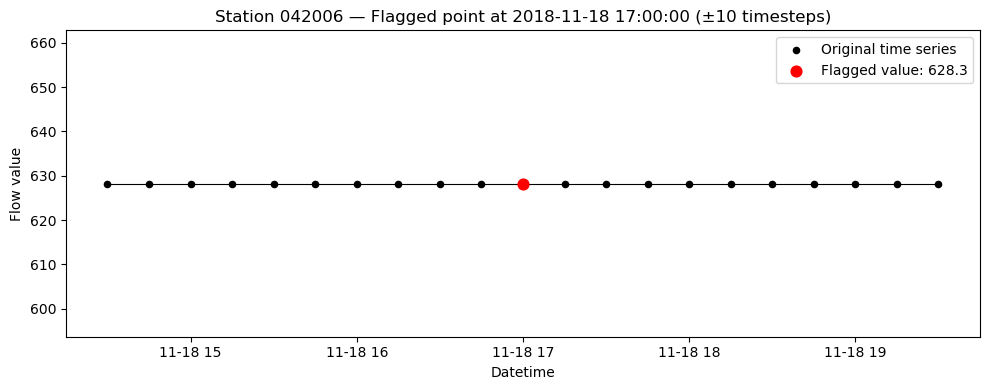

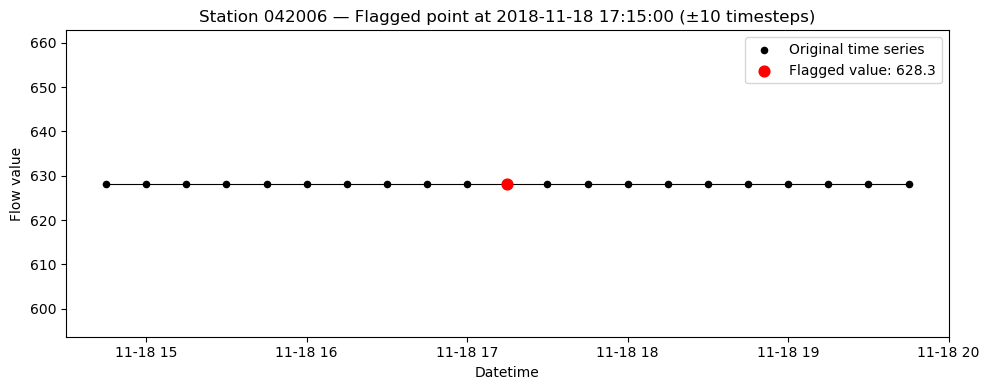

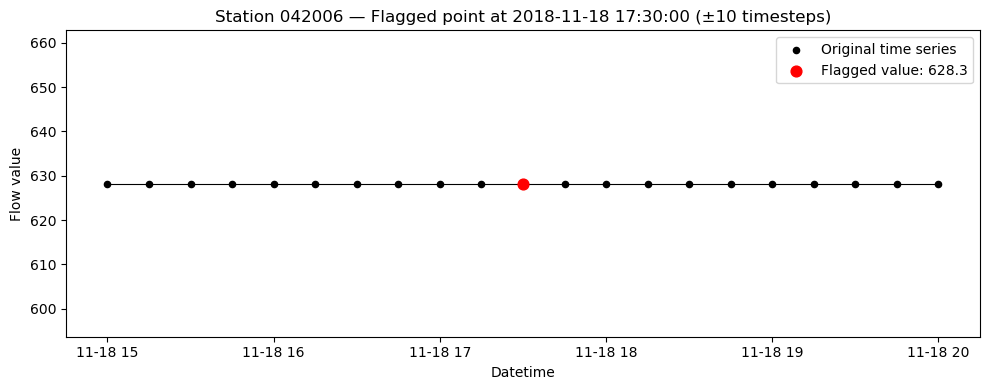

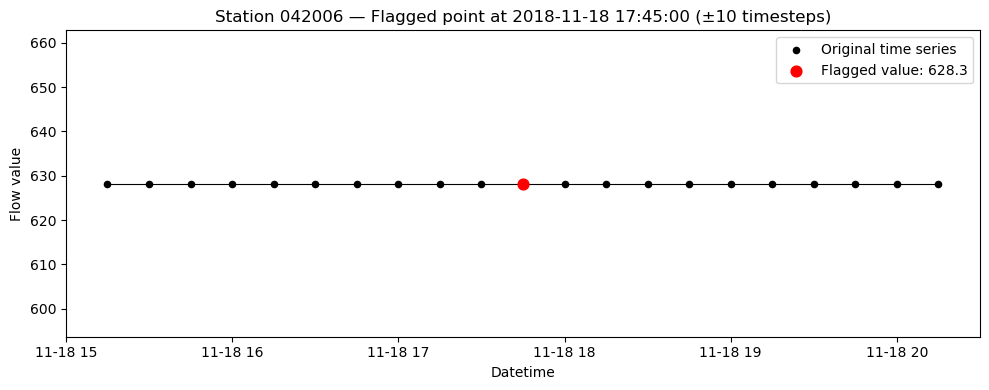

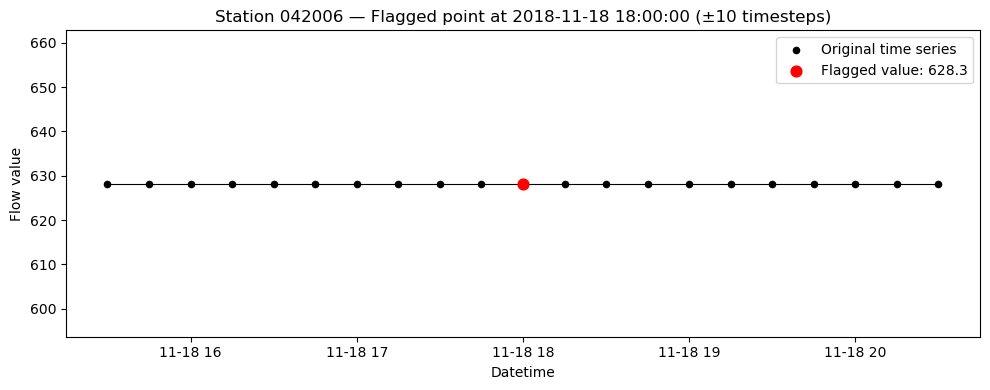

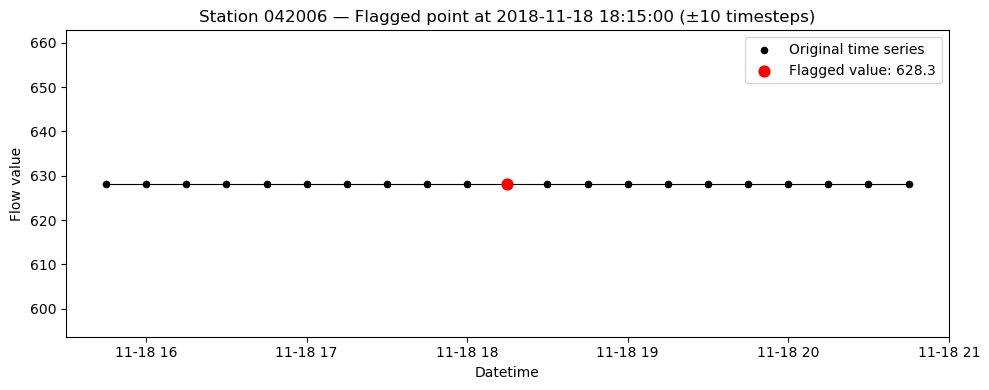

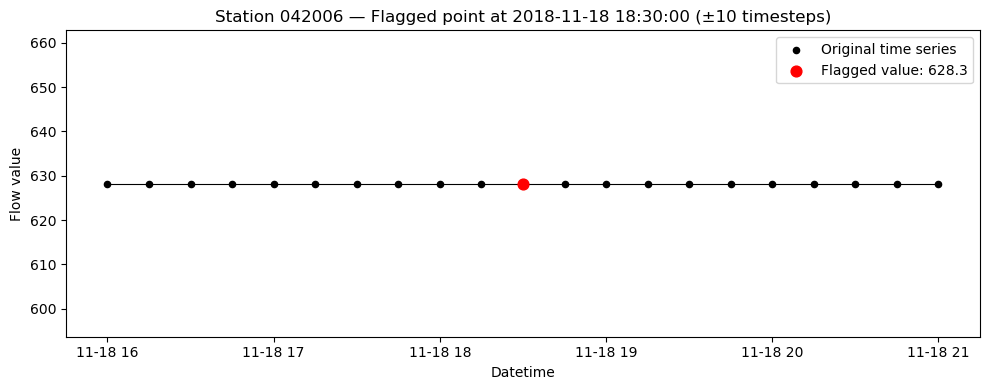

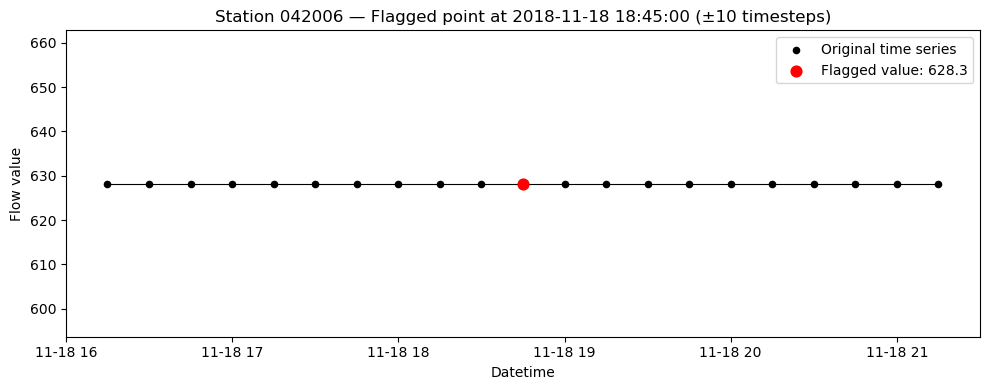

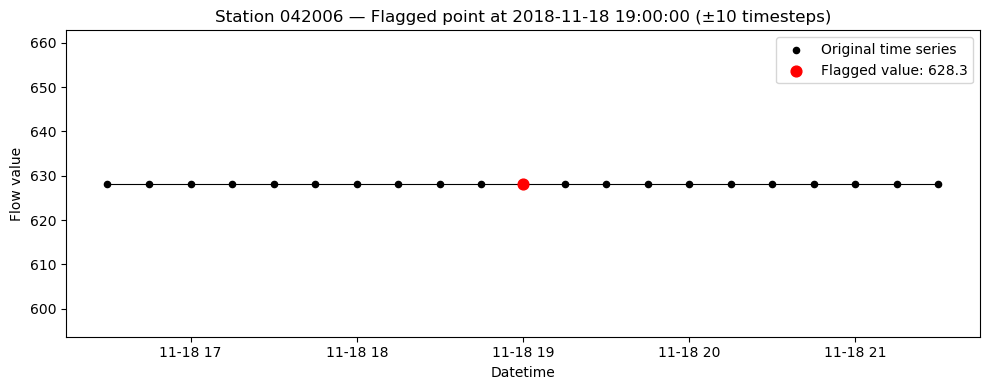

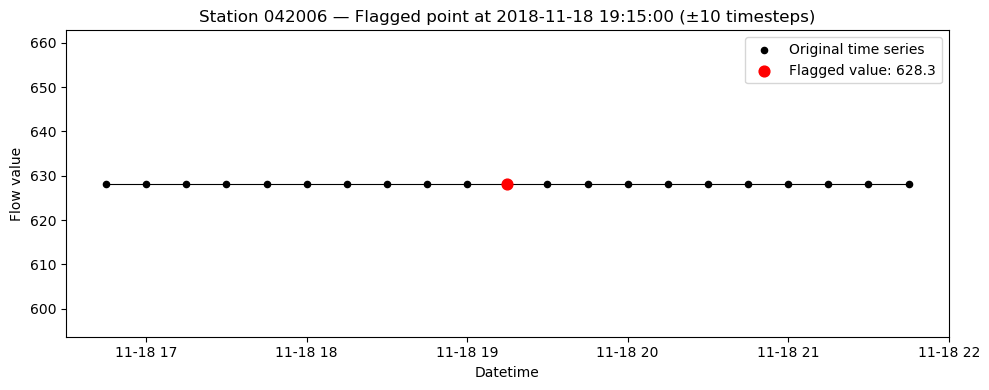

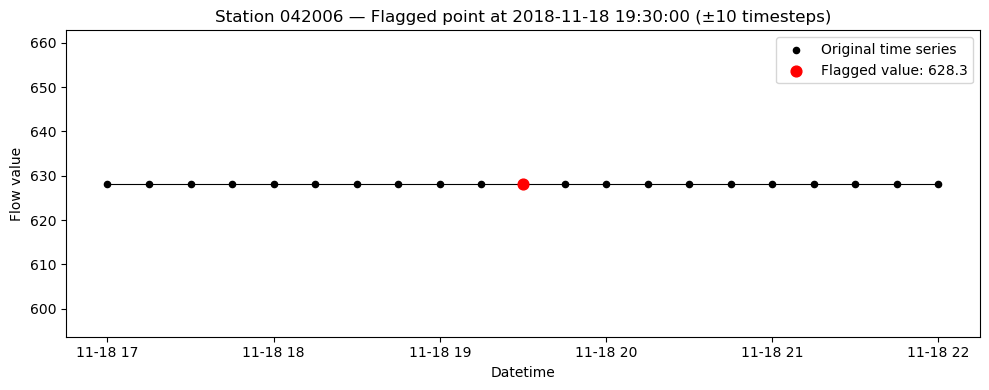

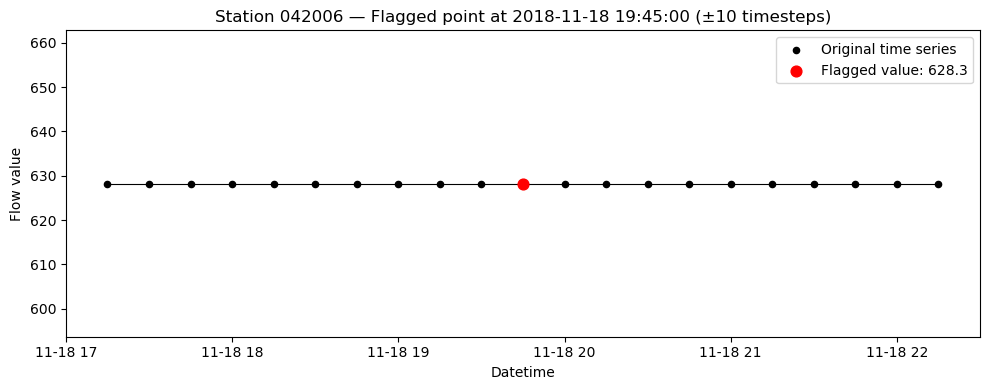

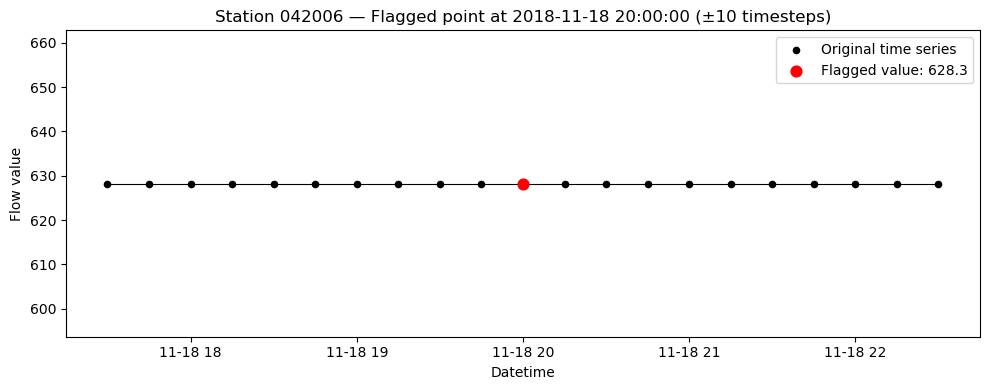

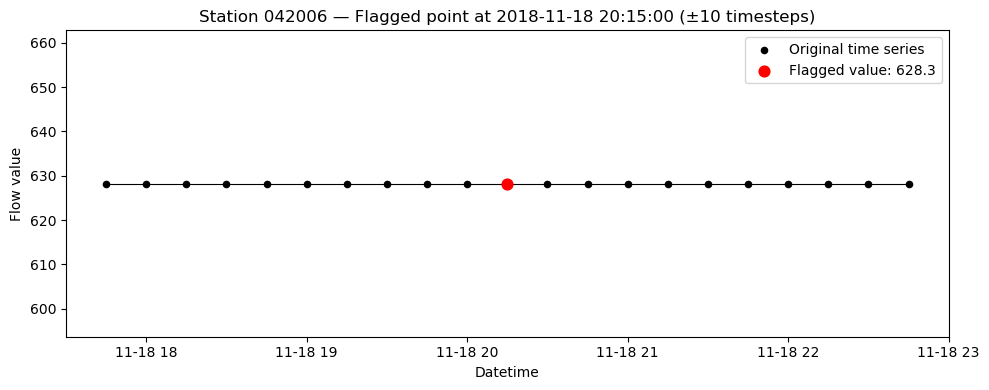

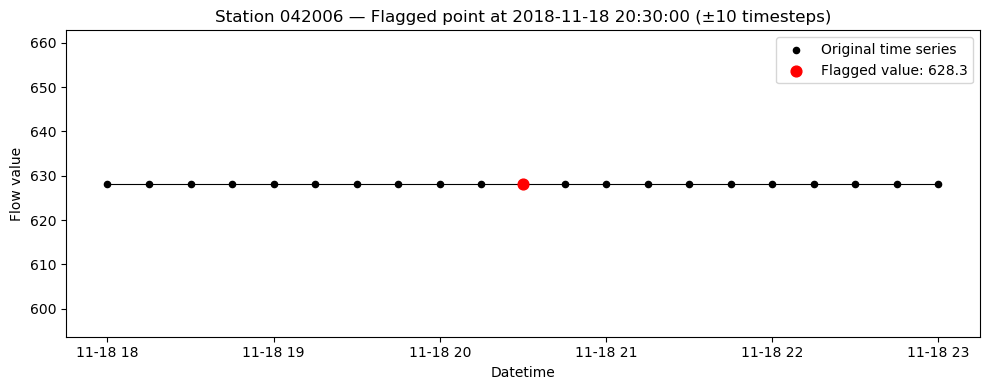

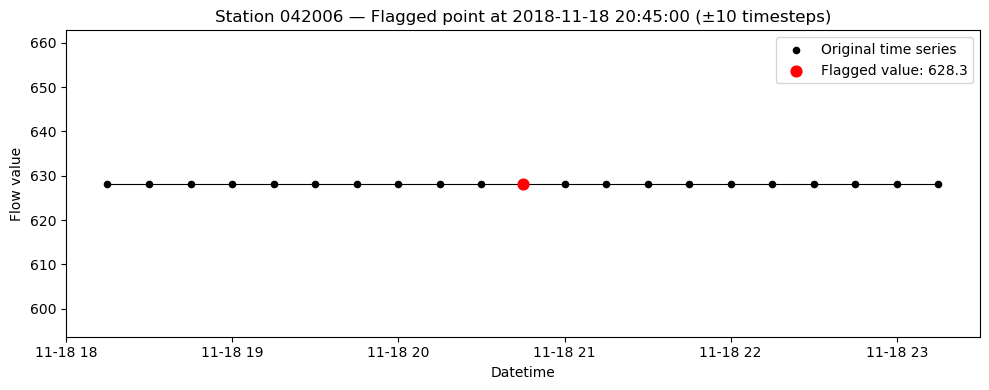

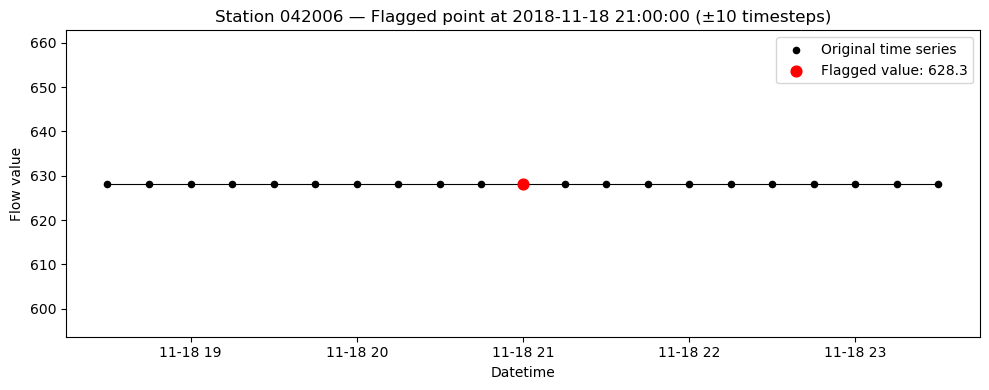

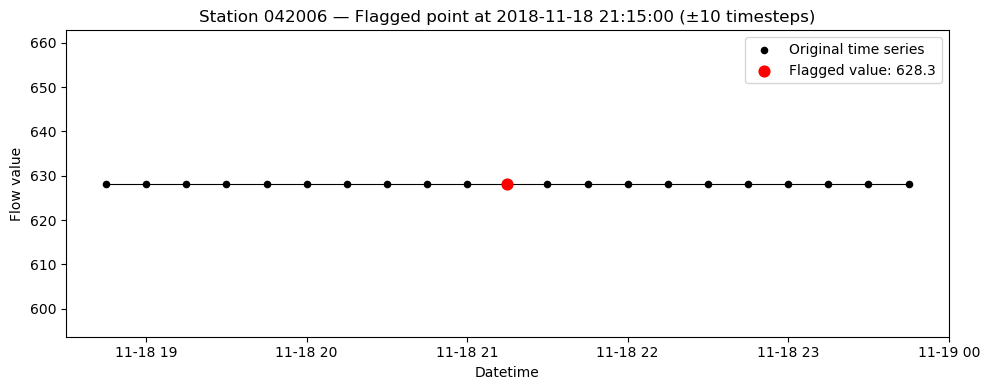

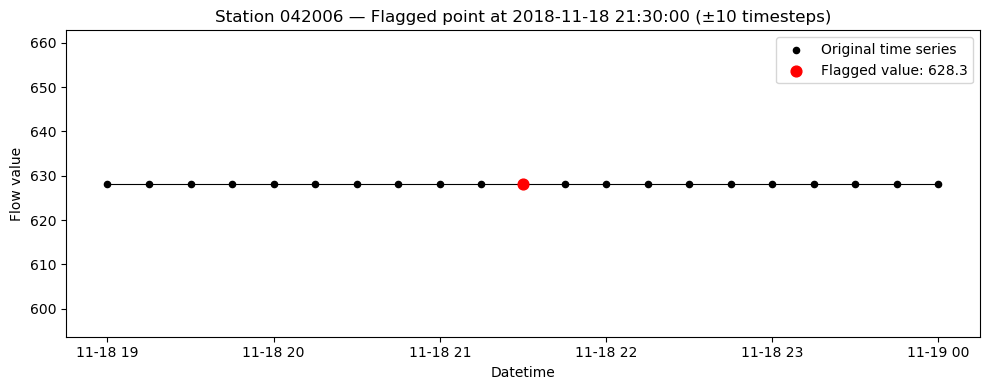

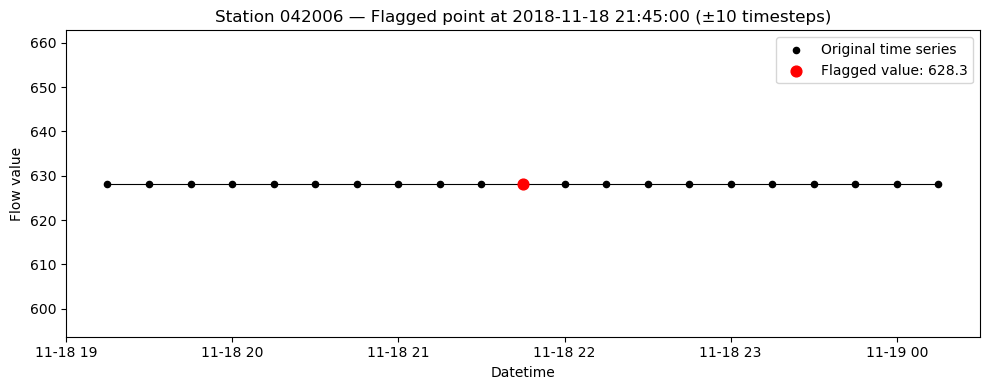

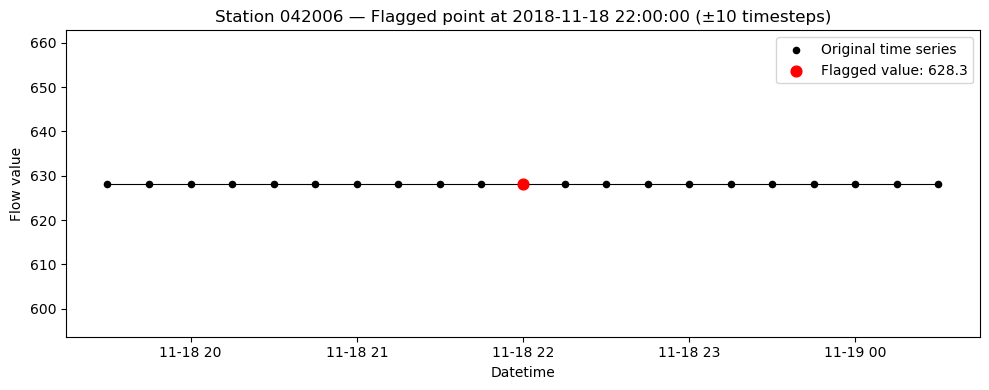

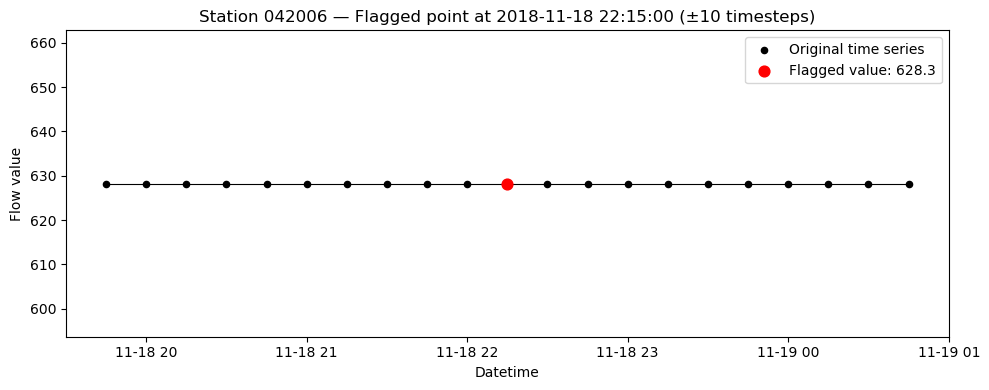

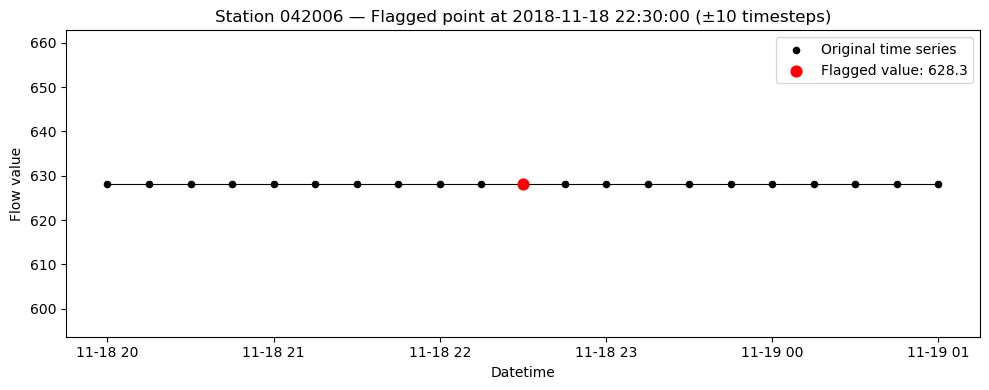

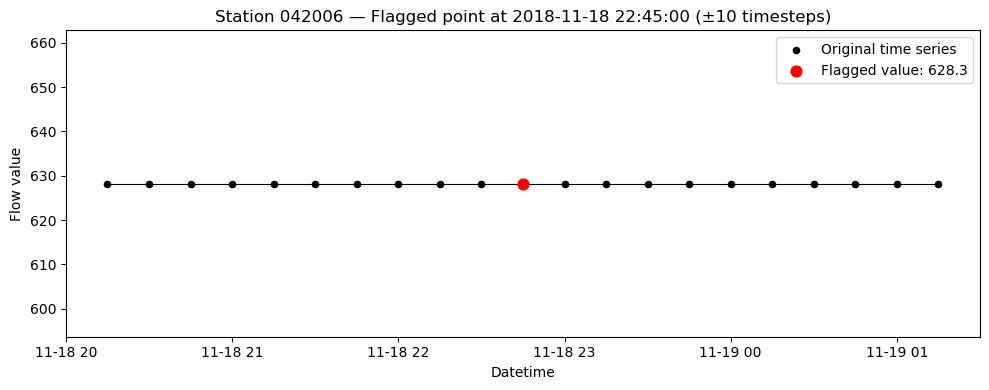

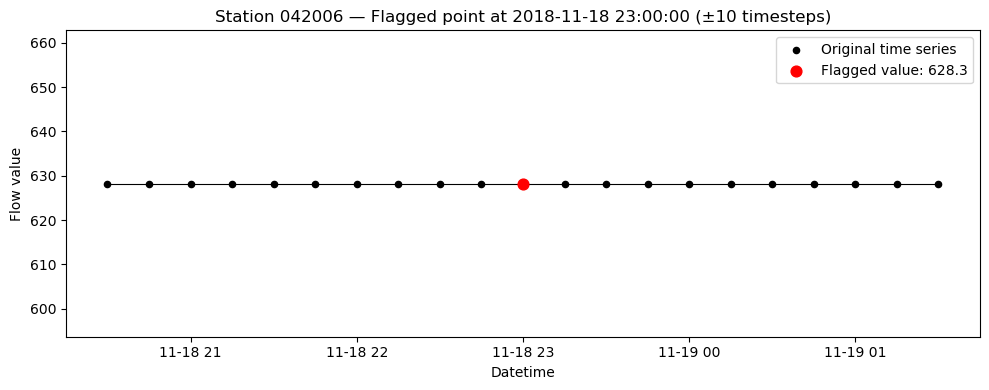

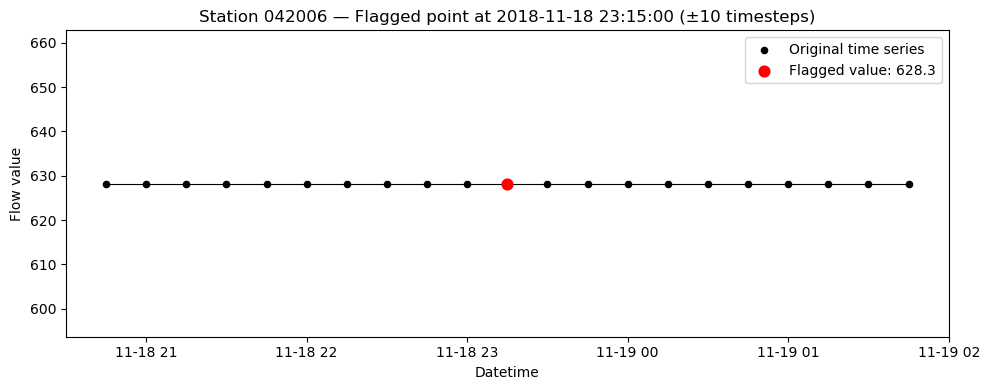

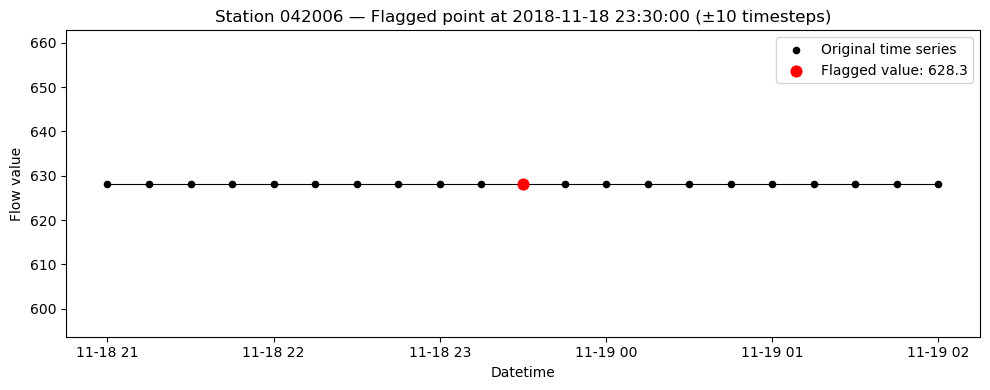

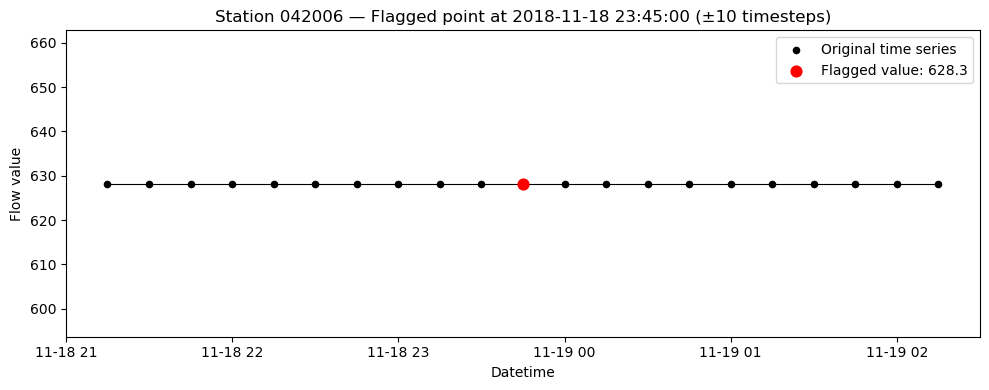

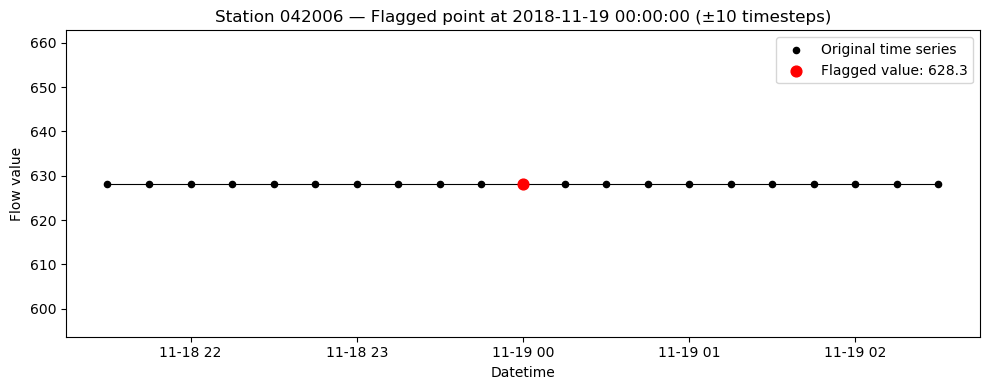

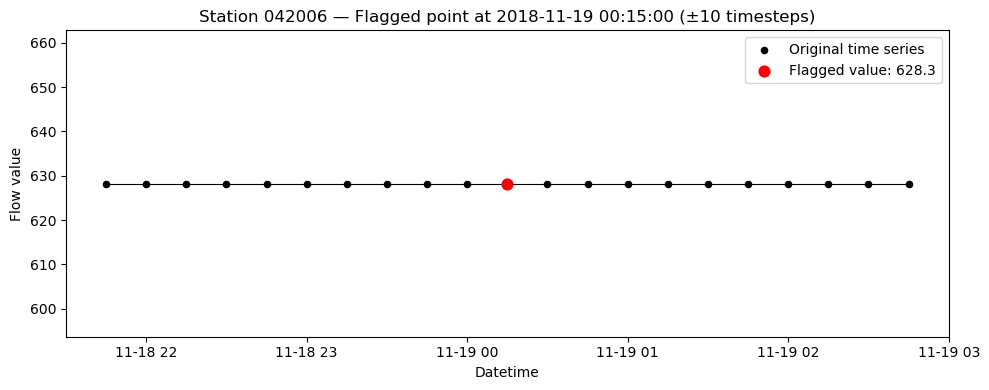

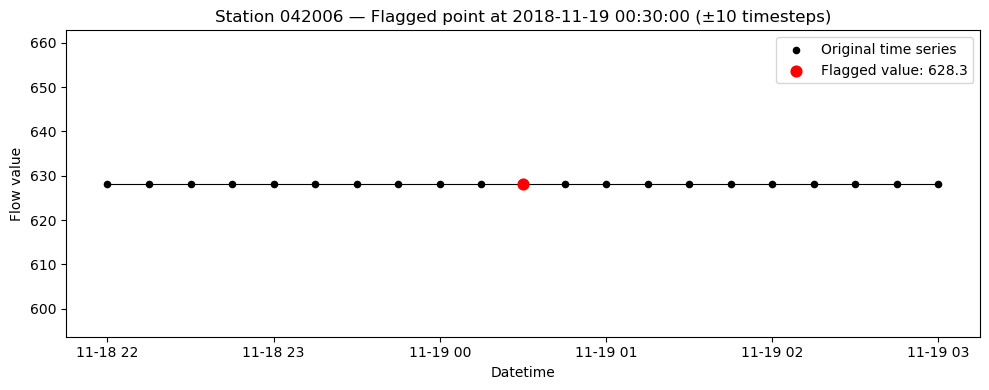

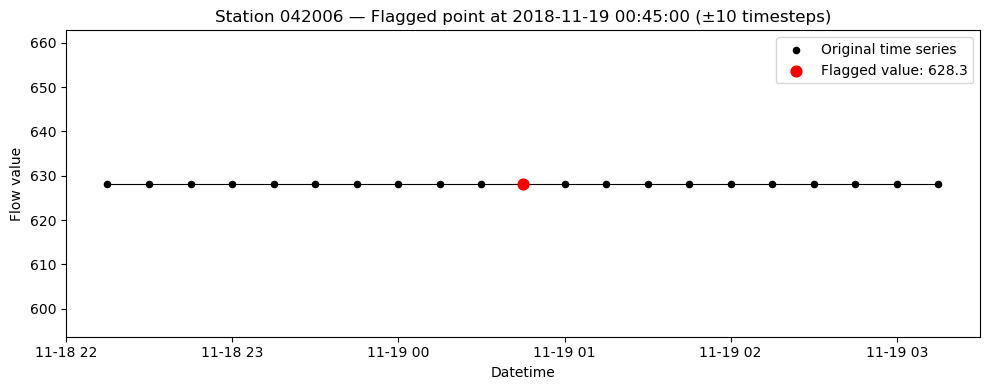

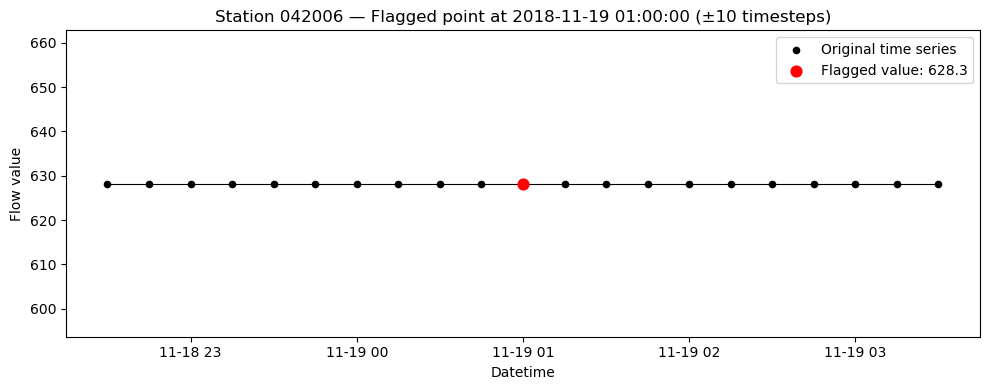

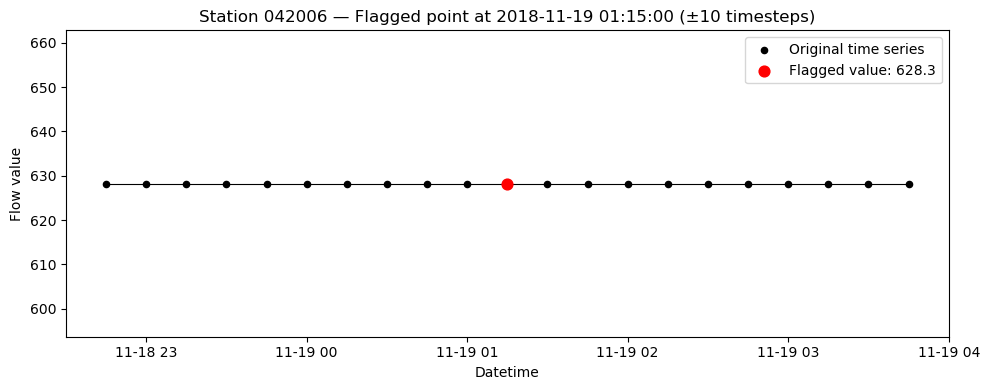

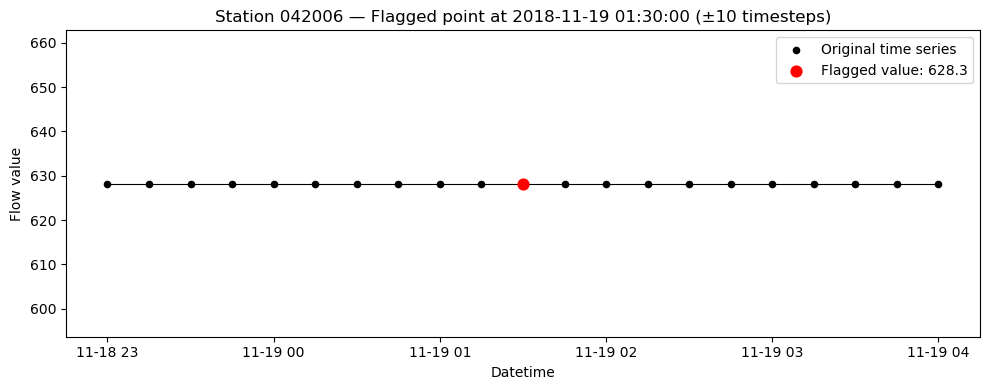

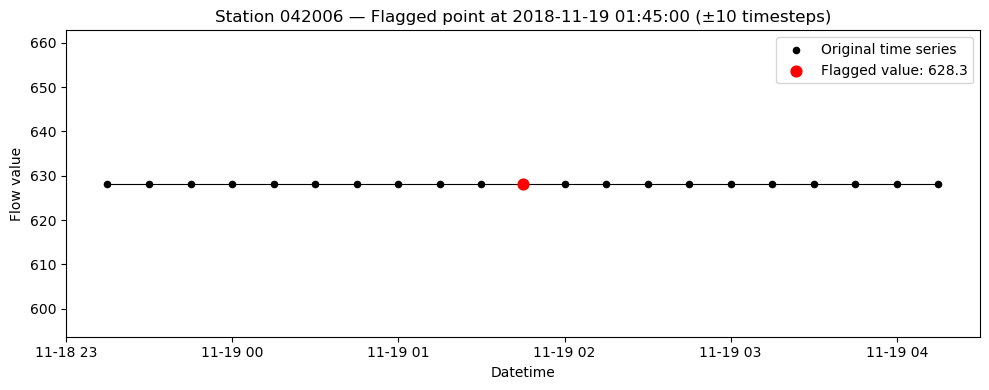

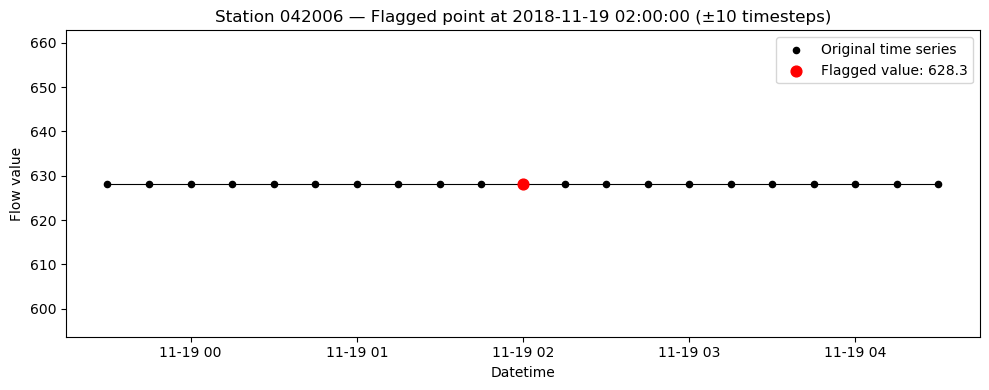

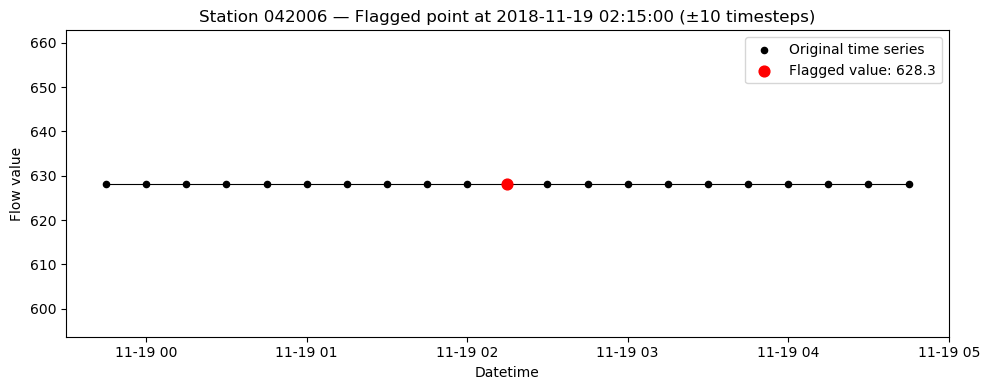

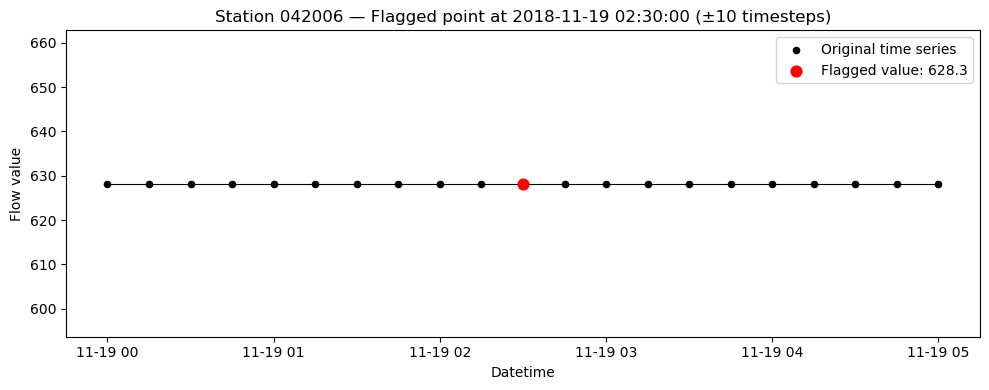

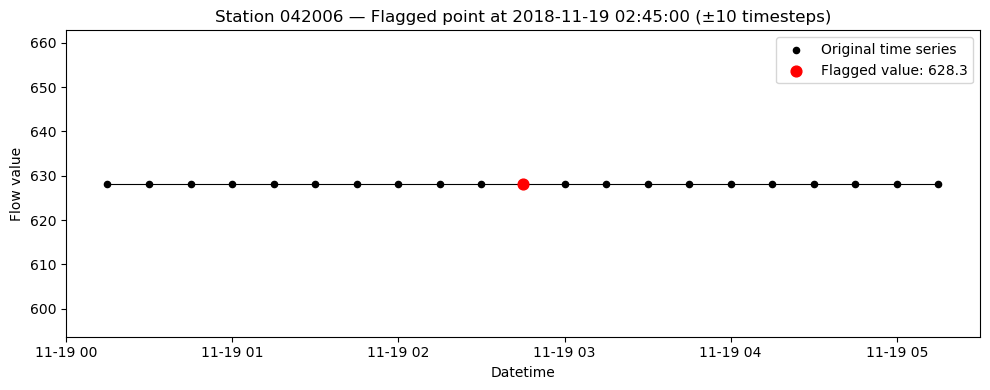

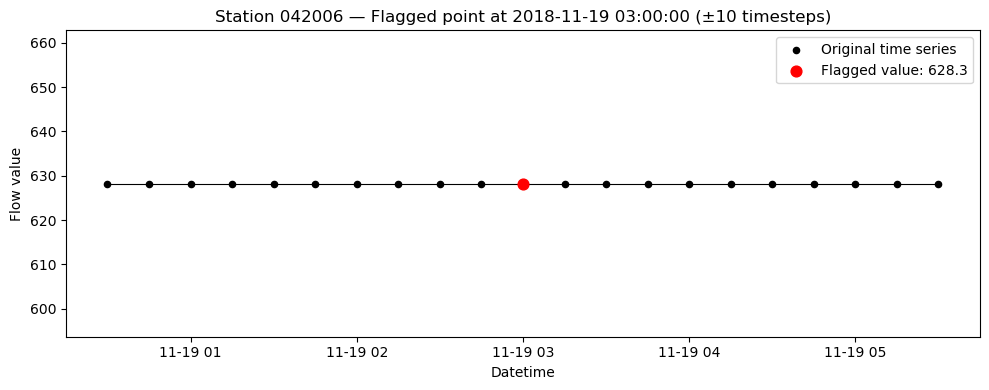

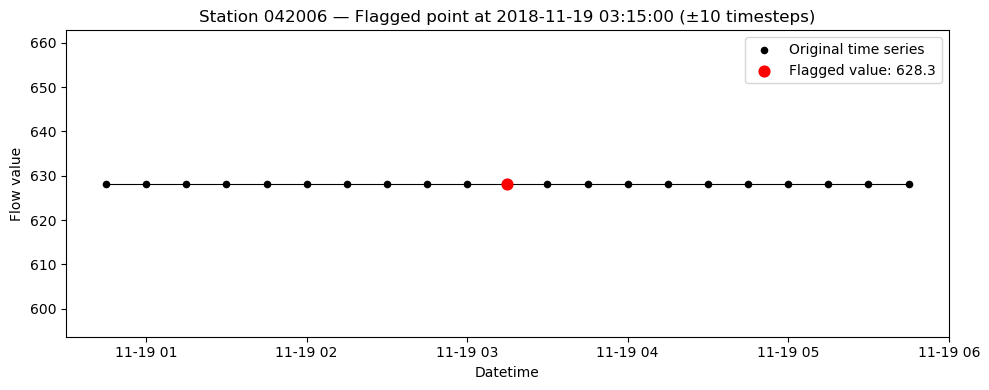

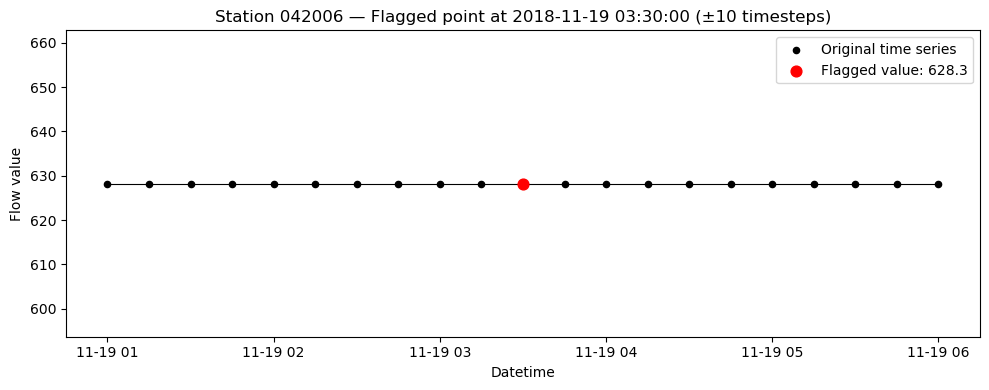

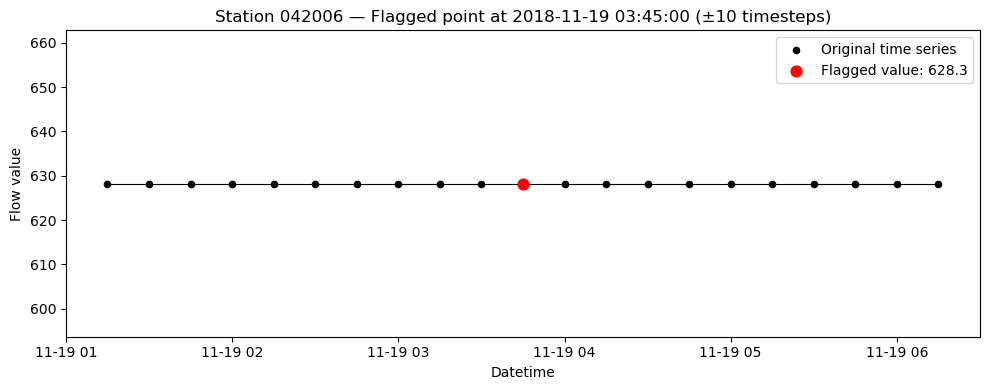

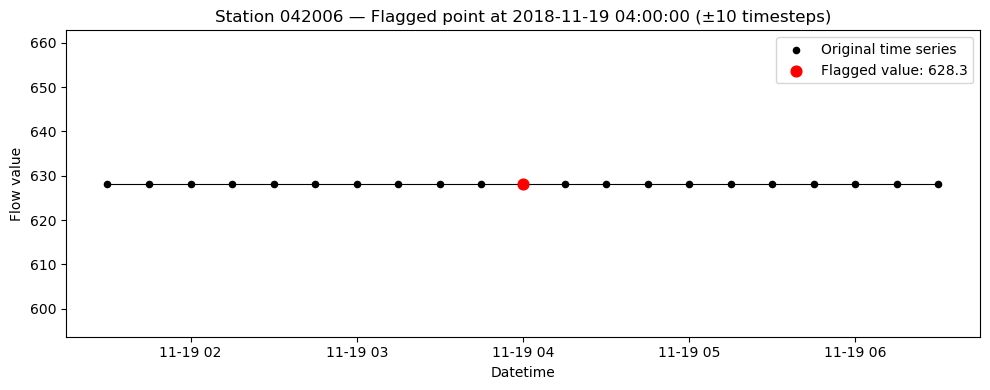

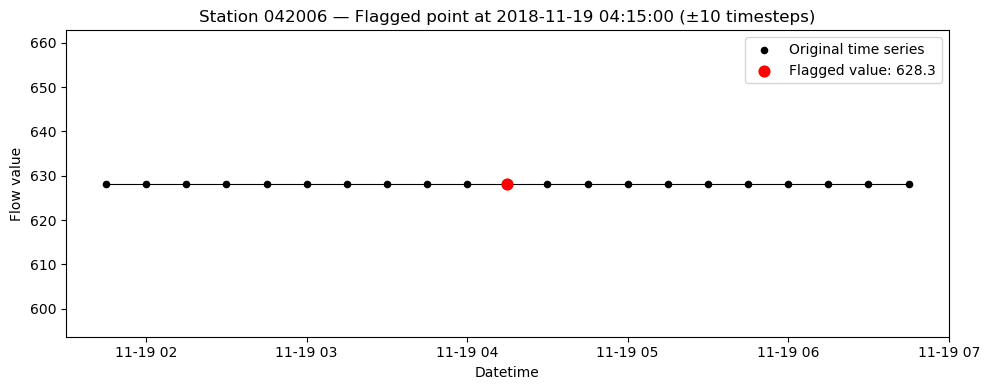

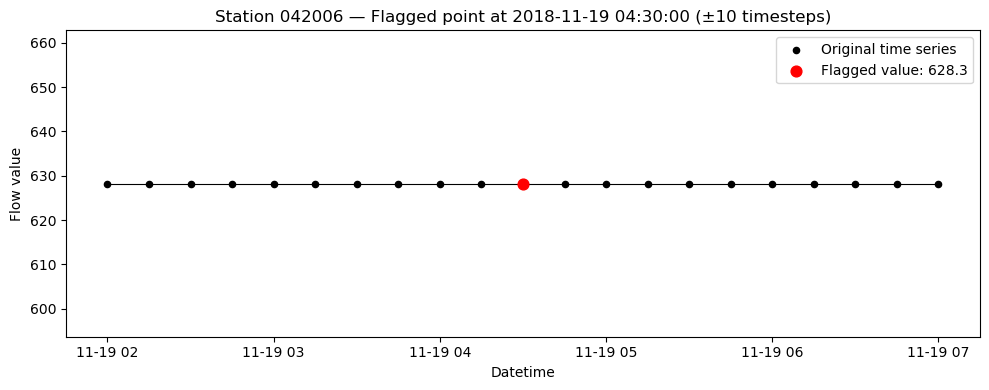

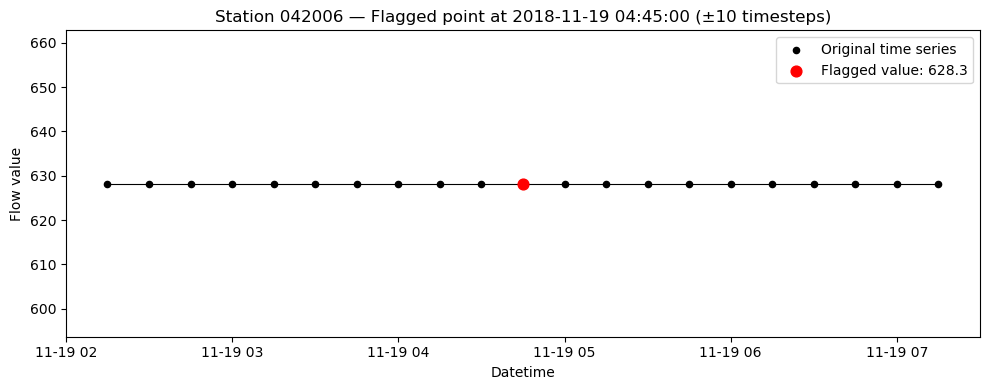

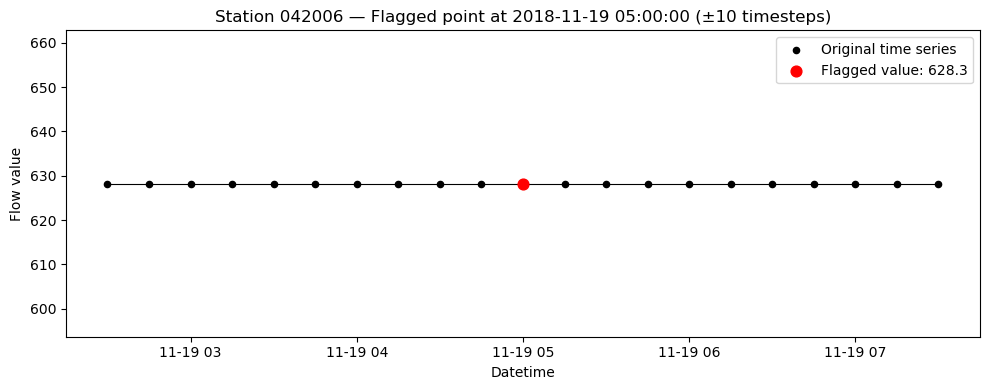

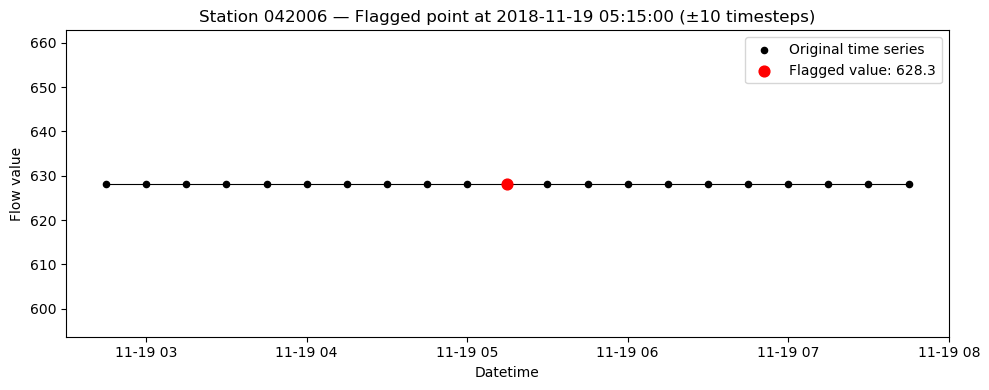

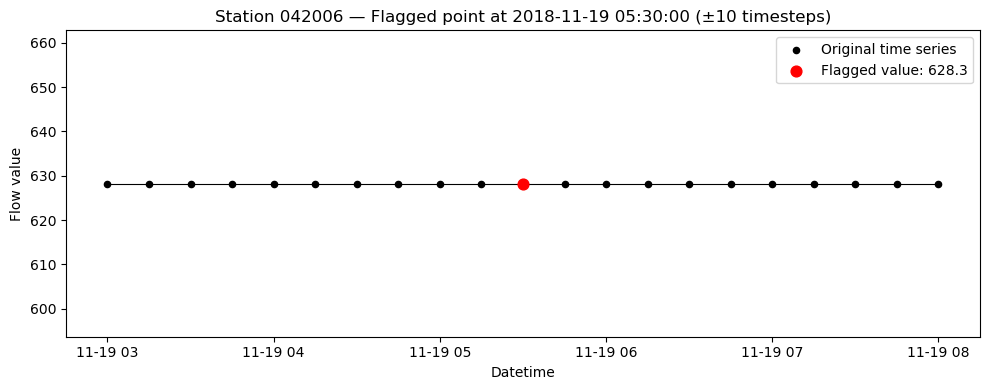

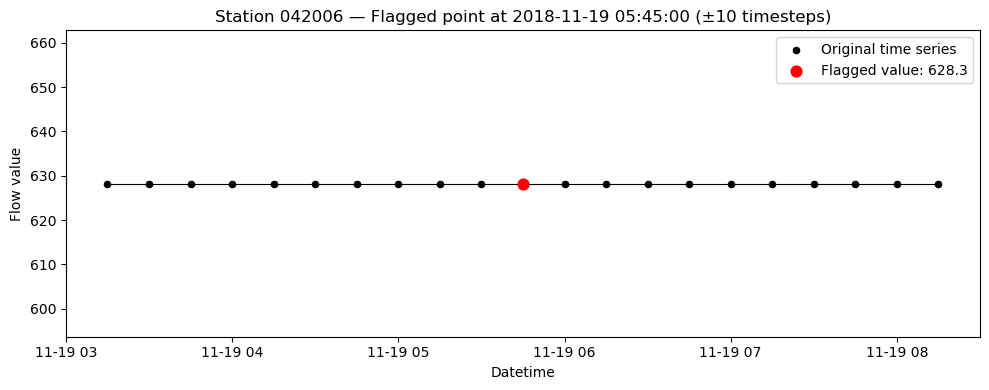

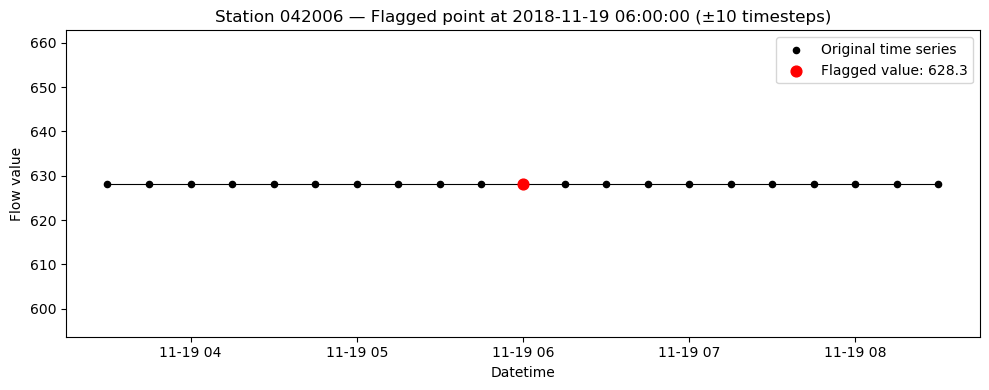

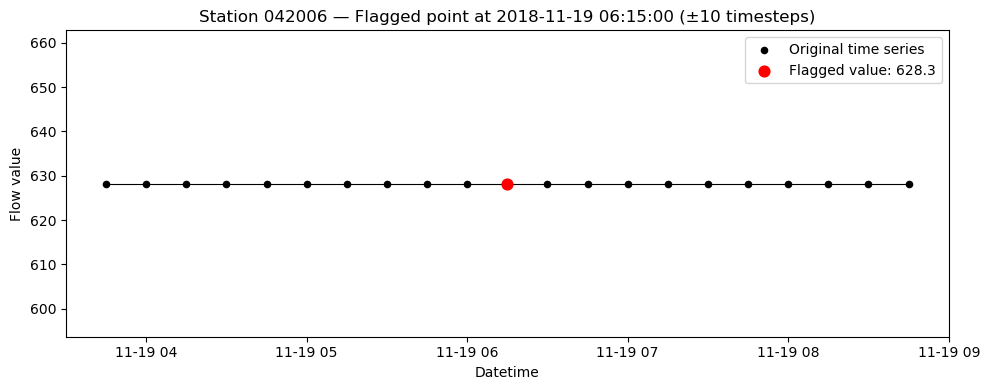

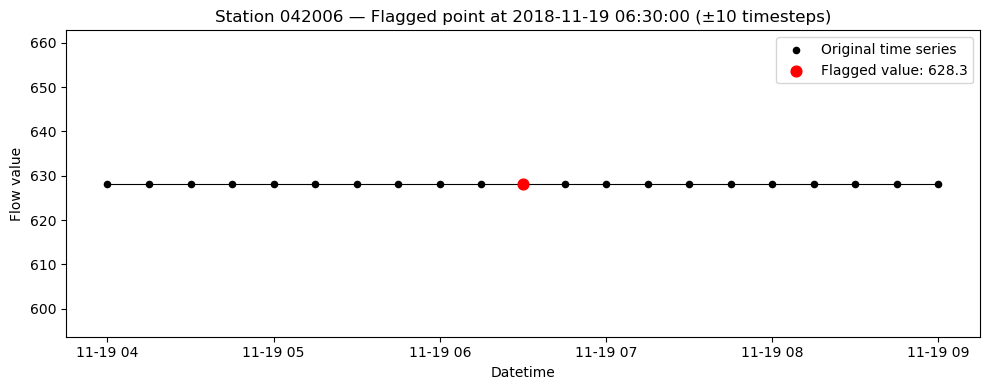

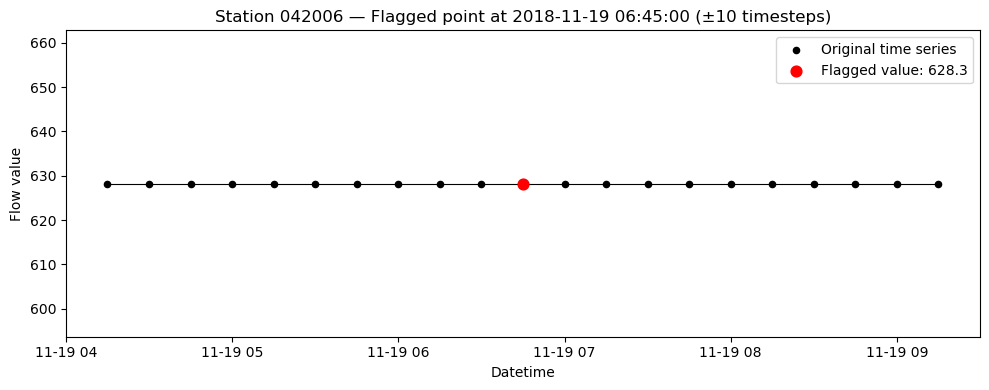

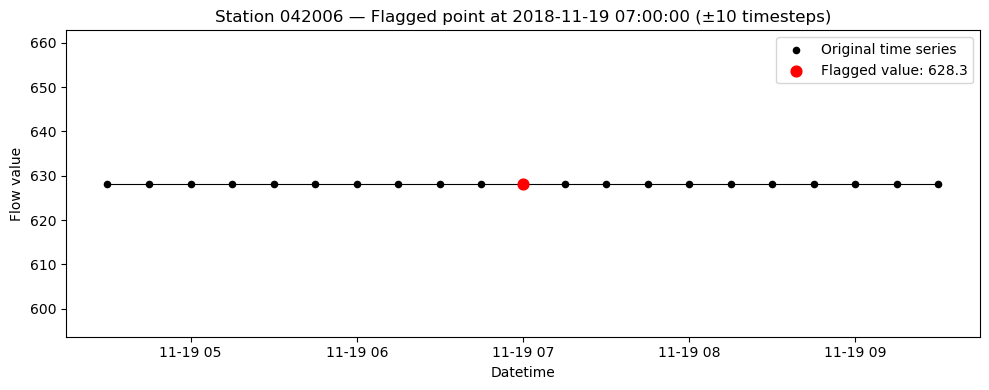

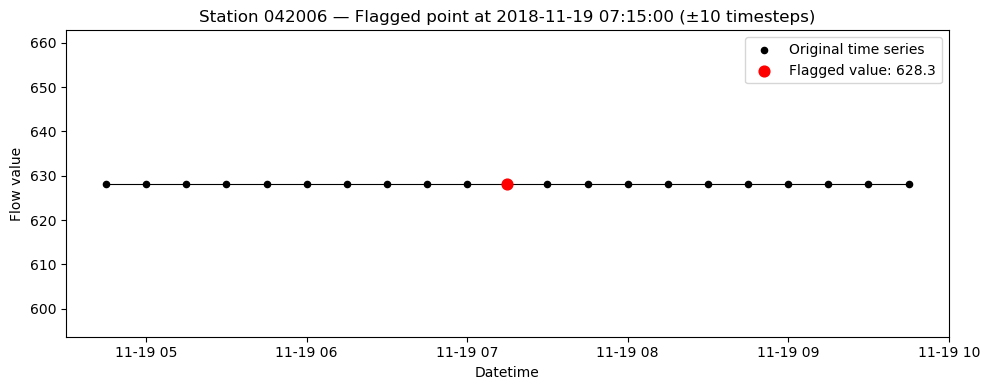

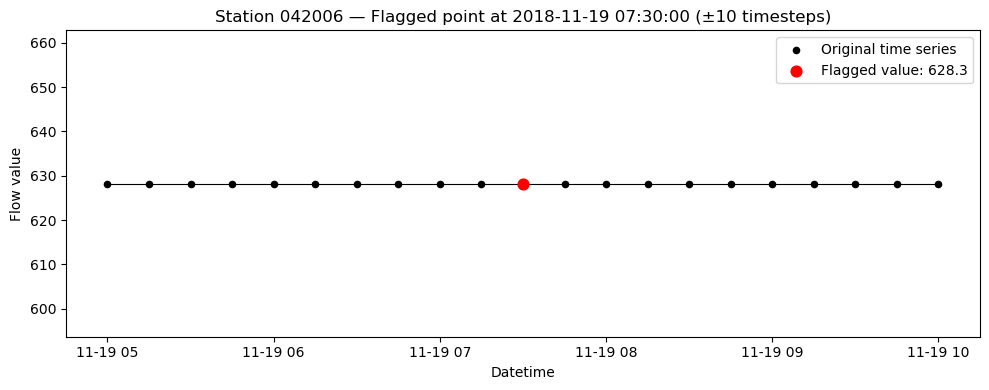

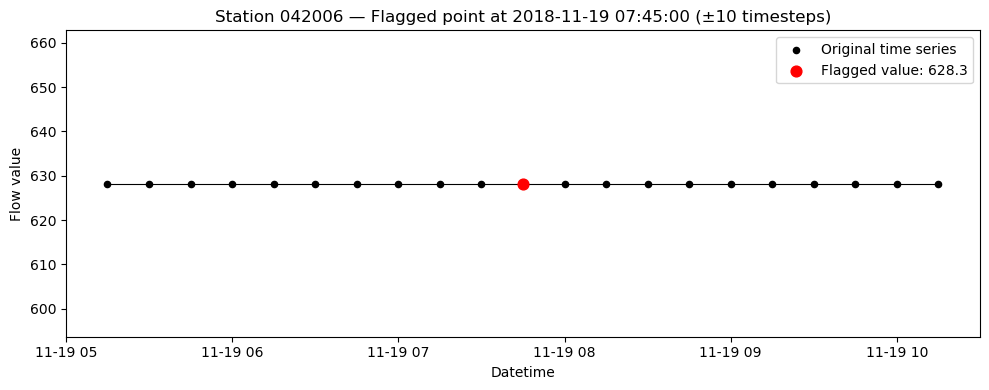

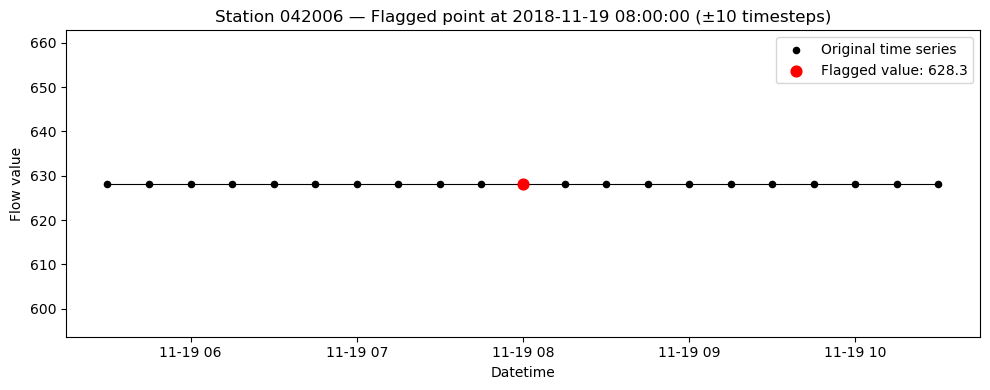

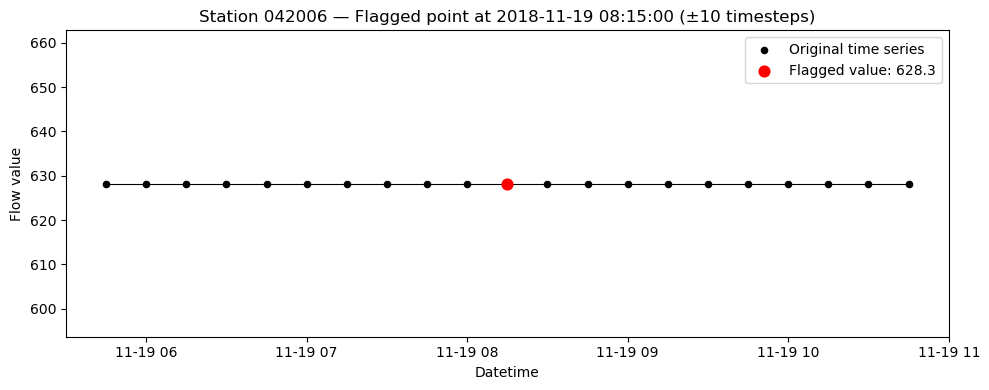

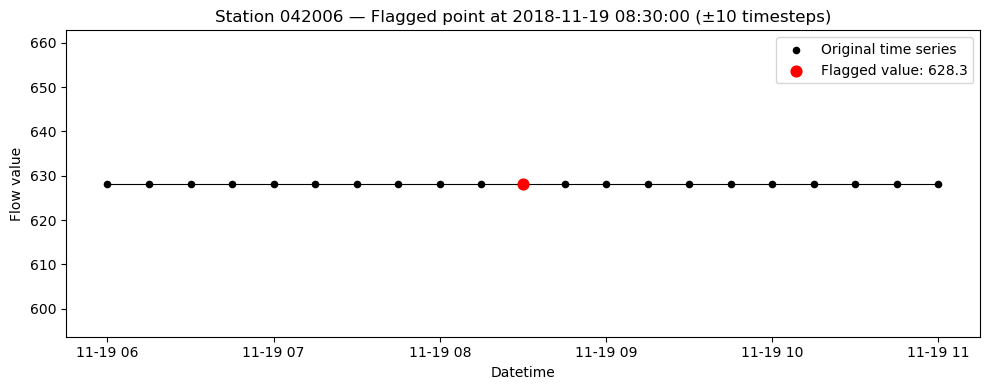

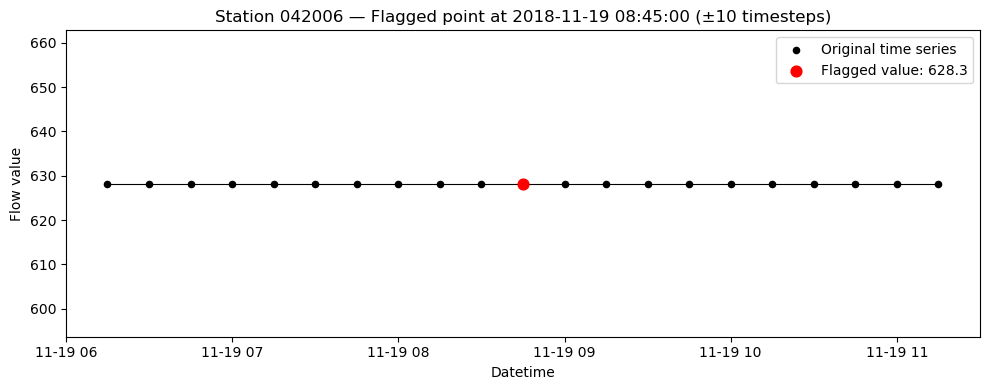

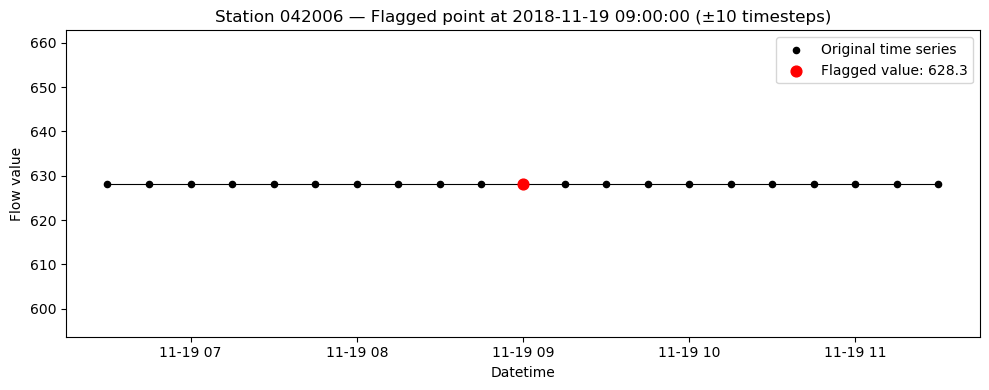

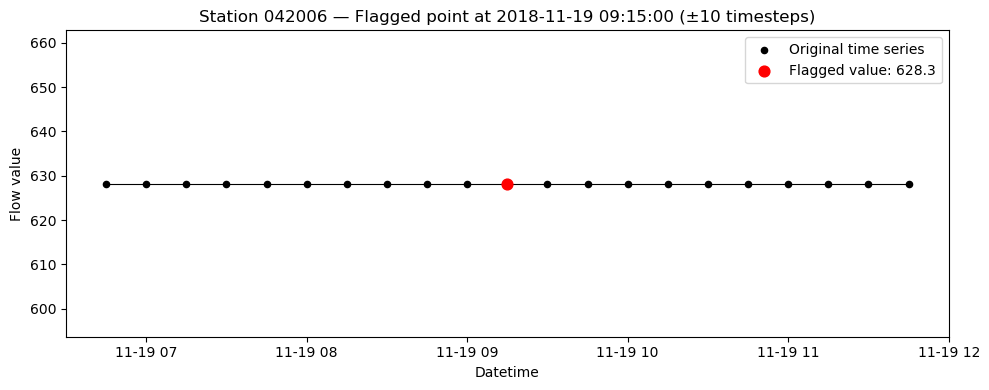

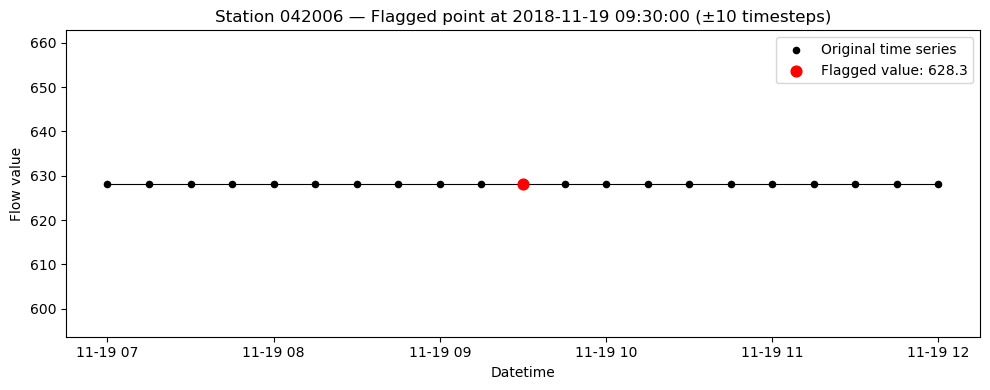

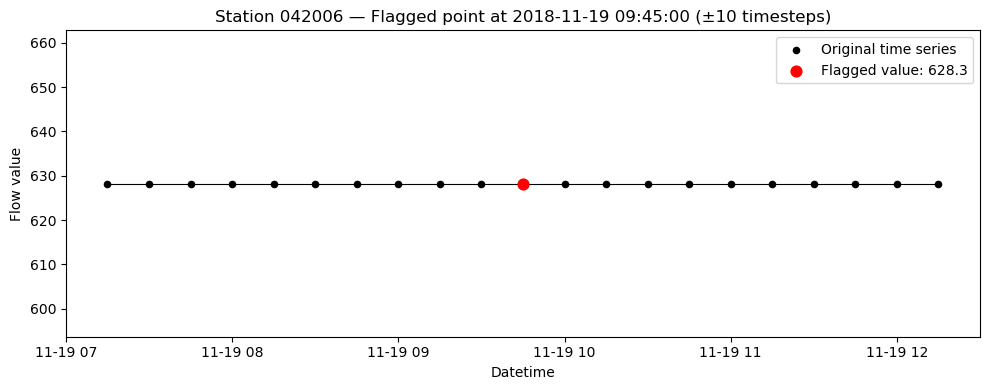

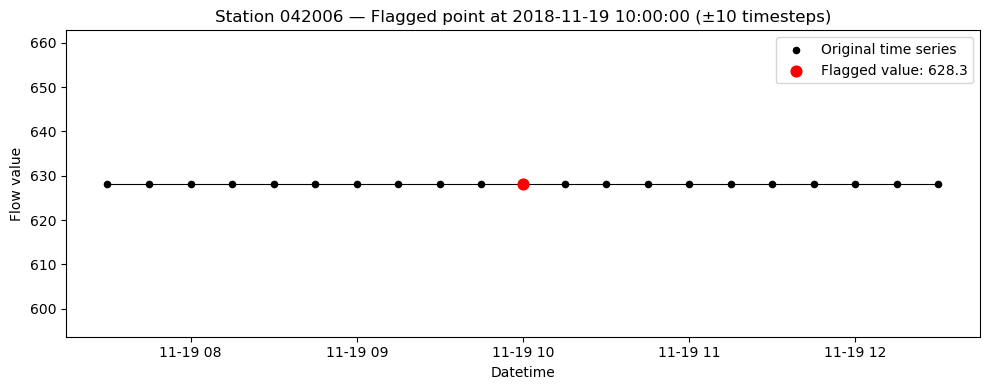

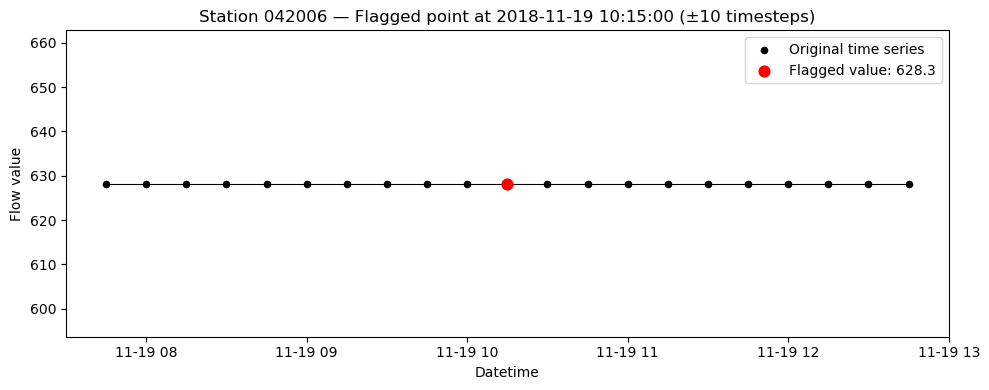

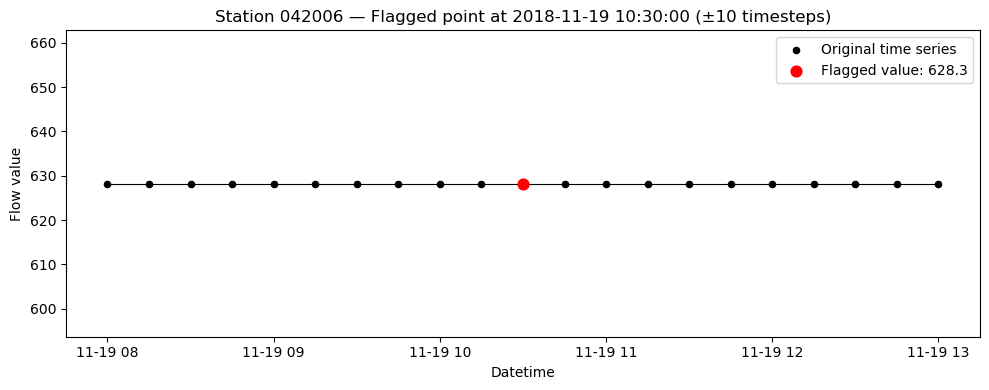

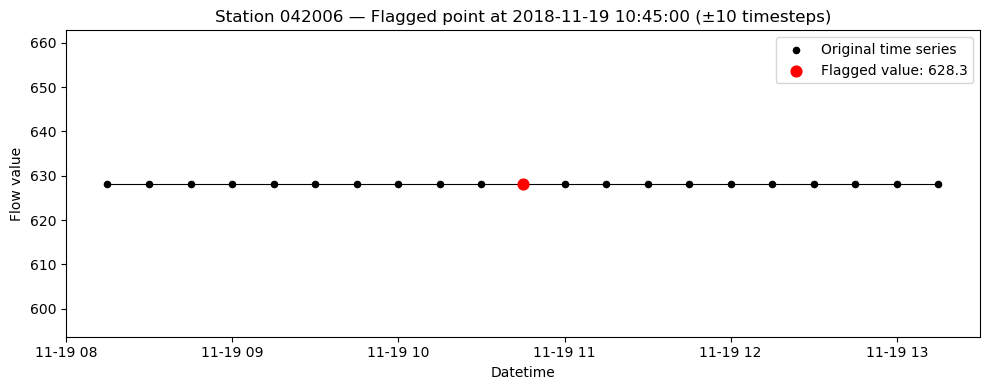

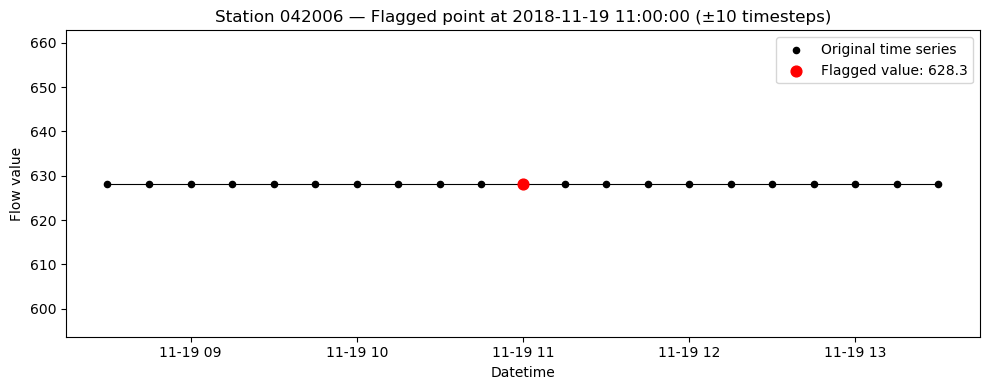

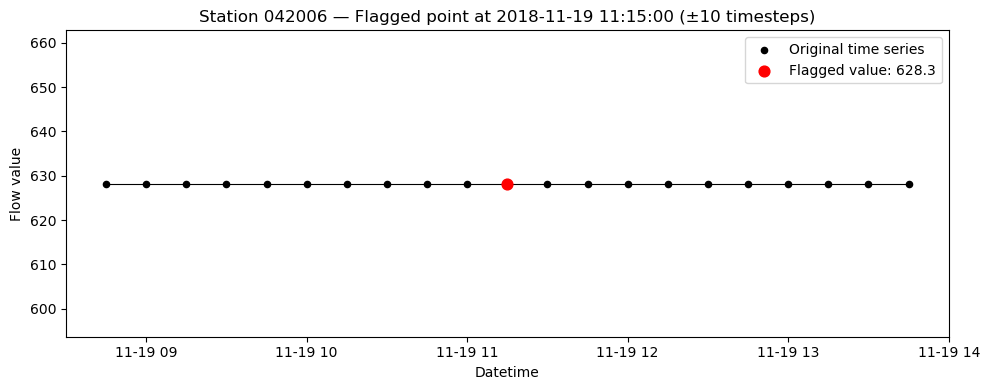

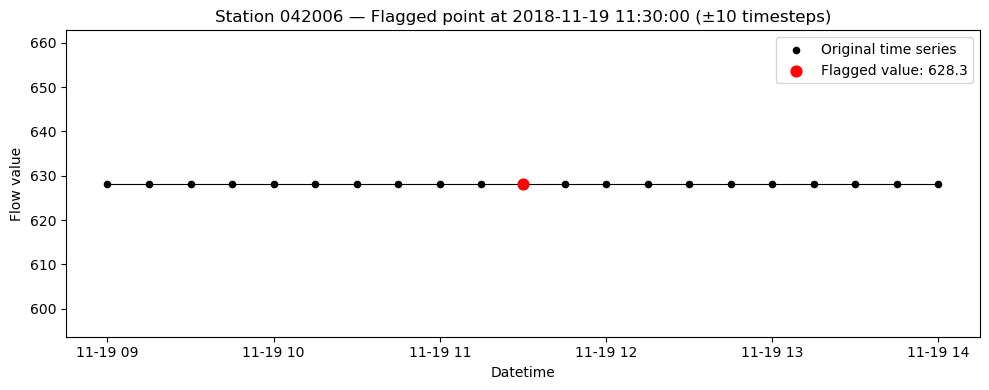

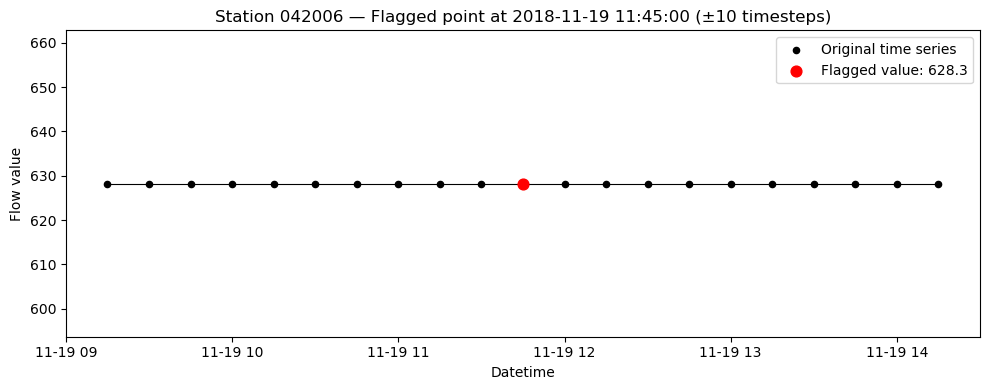

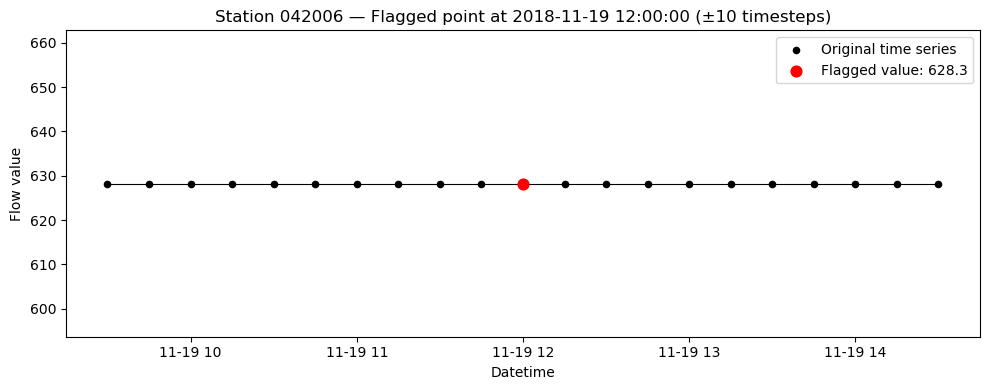

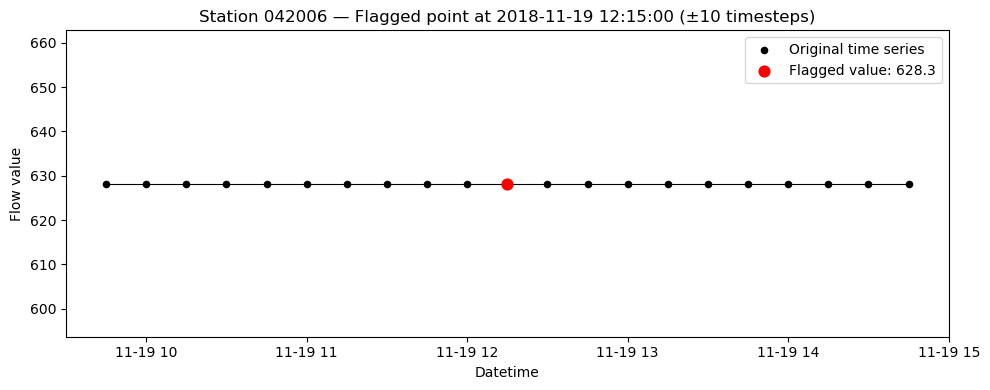

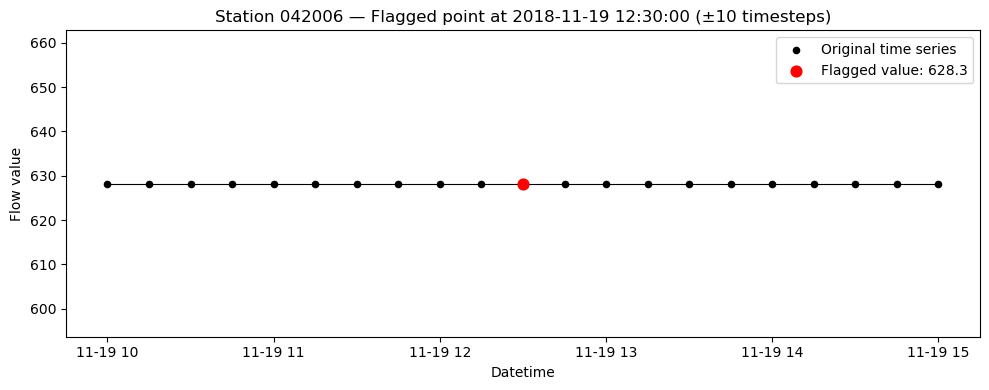

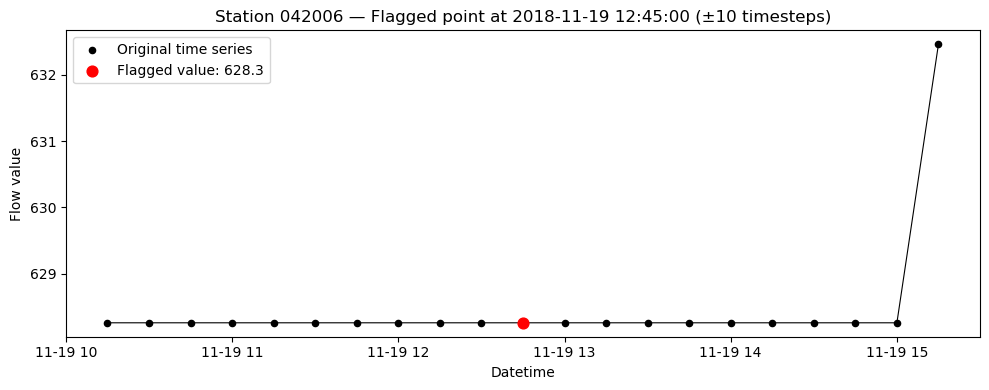

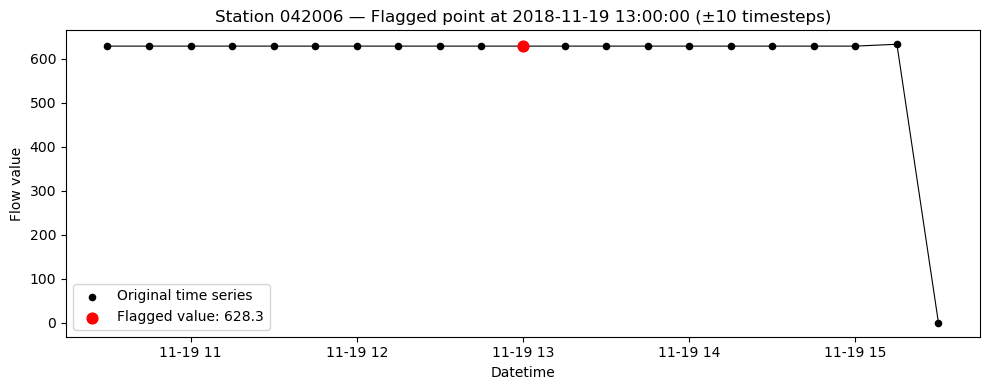

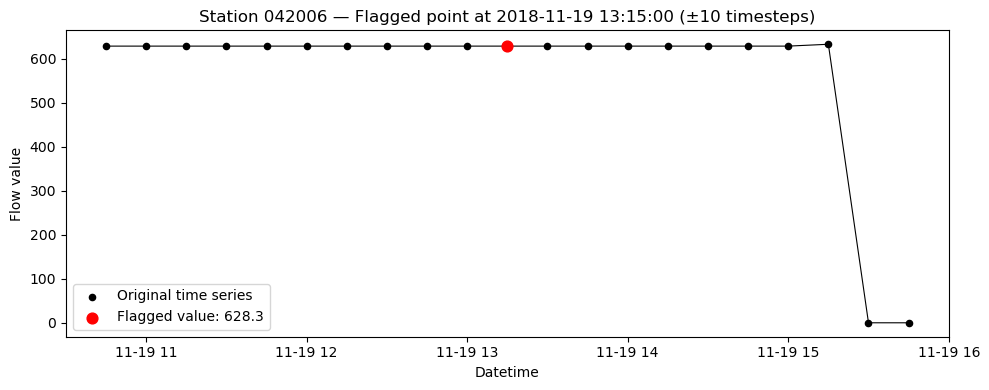

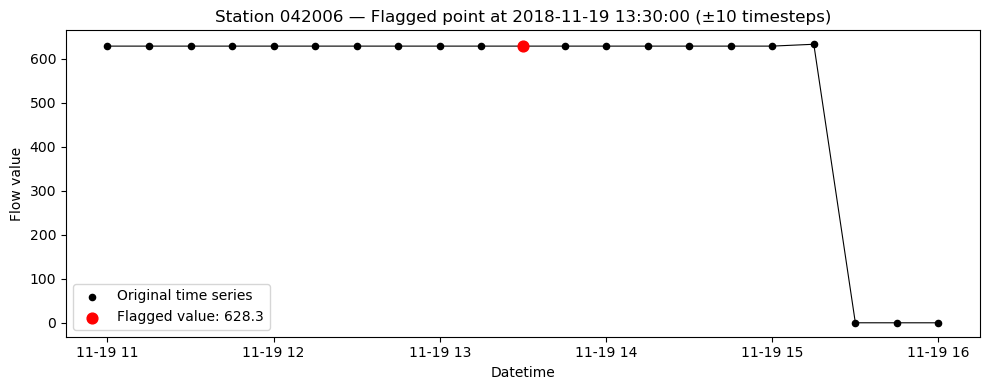

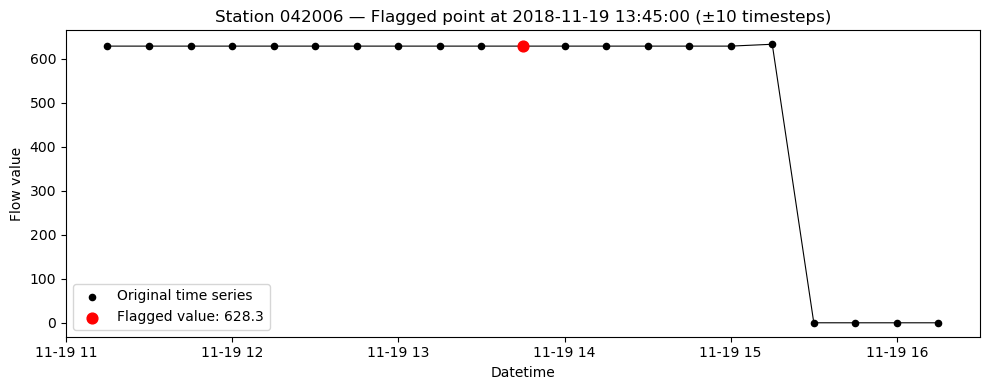

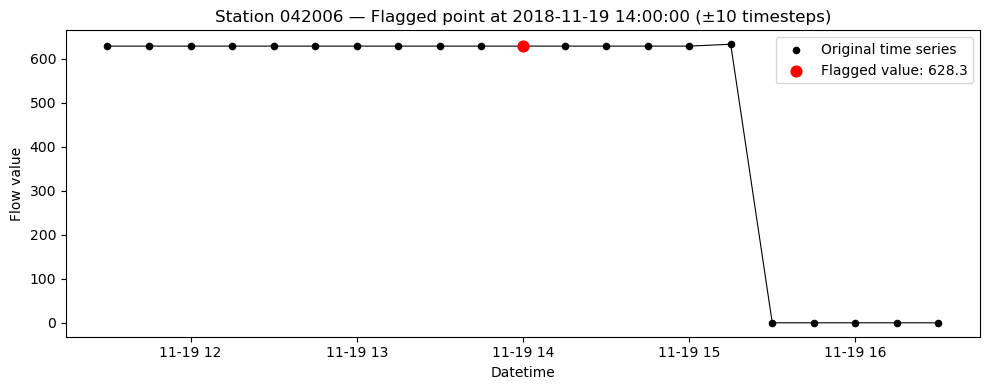

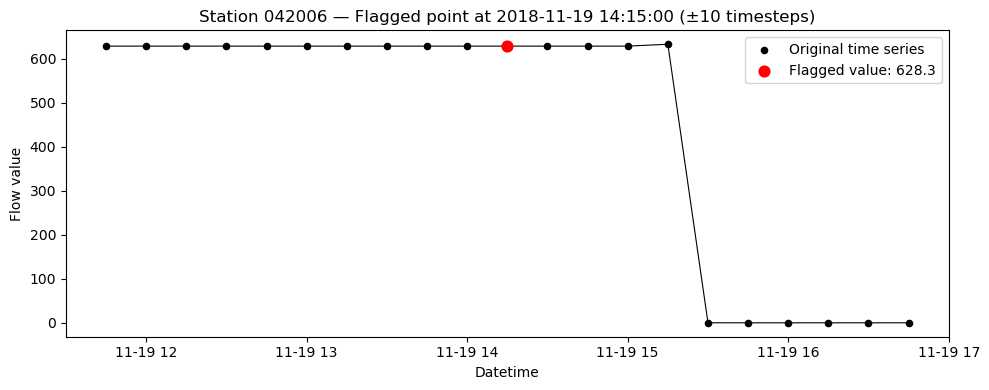

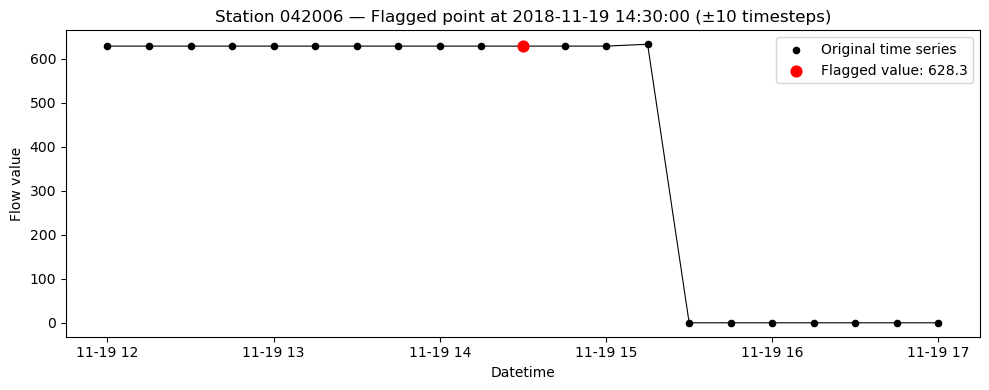

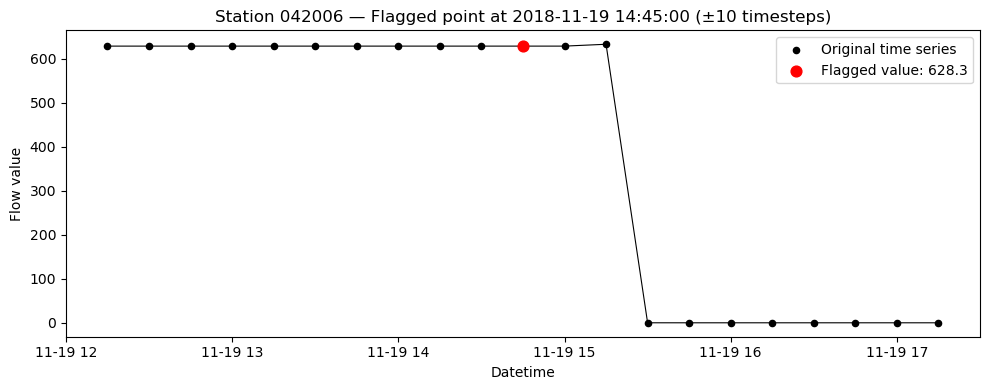

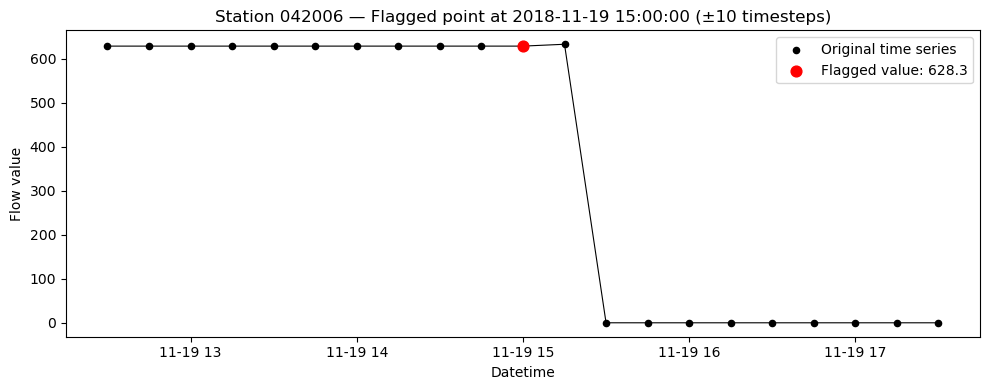

In [5]:
# =============================================================================
# VISUALISATION: ZOOMED VIEW AROUND EACH FLAGGED POINT
# =============================================================================
# For each flagged timestep, this plots a small window of 10 timesteps
# either side, showing the original time series (black), with the
# flagged value highlighted in red.

for pos in df.index.get_indexer(df.loc[flagged_rows].index):

    # Define the window as 10 timesteps either side, clamped to the dataframe bounds
    window_start = max(0, pos - 10)
    window_end = min(len(df) - 1, pos + 10)

    # Subset the data to the window
    df_window = df.iloc[window_start:window_end + 1].copy()

    # Get the datetime and value of the flagged point
    flagged_datetime = df.index[pos]
    flagged_value = df.iloc[pos]["value"]

    fig, ax = plt.subplots(figsize=(10, 4))

    # Plot the time series within the window
    ax.plot(df_window.index, df_window["value"],
            color="black", linewidth=0.8)
    ax.scatter(df_window.index, df_window["value"],
            color="black", s=20, label="Original time series")

    # Highlight the flagged point in red
    ax.scatter(flagged_datetime, flagged_value,
               color="red", zorder=5, s=60, label=f"Flagged value: {flagged_value:.1f}")

    ax.set_title(f"Station {station_id} — Flagged point at {flagged_datetime} (±10 timesteps)")
    ax.set_xlabel("Datetime")
    ax.set_ylabel("Flow value")
    ax.legend()
    fig.tight_layout()
    plt.show()

In [7]:
# =============================================================================
# STEP 3: RECORD THE ORIGINAL VALUES BEFORE INTERPOLATION
# =============================================================================
# Before we overwrite any values, we save the original values of the flagged
# rows. This gives us a log of what changed, which is useful for auditing
# and quality checking the interpolation afterwards.

old_values = ( df.loc[flagged_rows, ["value"]]   # extract only the flagged rows
    .rename(columns={"value": "old_value"})  # rename so it is clear these are the originals
    .reset_index())                # move datetime from index to a regular column

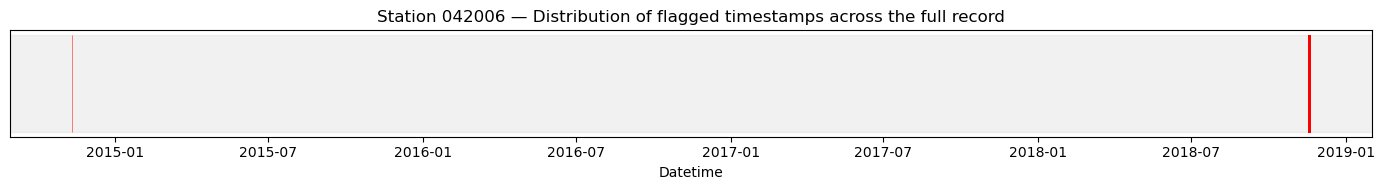

In [8]:
# =============================================================================
# VISUALISATION 3: FLAGGED TIMESTAMPS ALONG THE TIME AXIS
# =============================================================================
# This plot shows when flagged points occur across the full record.
# Each flagged timestamp is marked as a vertical line, making it easy to
# see whether bad data is clustered in time (e.g. during a particular season
# or instrument failure period) or scattered randomly throughout the record.
# This is useful context for judging how reliable the interpolation is likely
# to be — clustered gaps are harder to interpolate accurately than isolated points.

fig, ax = plt.subplots(figsize=(14, 2))

ax.vlines( pd.to_datetime(old_values["datetime"]), ymin=0, ymax=1,color="red", linewidth=0.5, alpha=0.7)

# Add a shaded background to represent the full record extent
ax.axhspan(0, 1, color="lightgrey", alpha=0.3)

ax.set_title(f"Station {station_id} — Distribution of flagged timestamps across the full record")
ax.set_xlabel("Datetime")
ax.set_yticks([])  # y axis is not meaningful here
plt.tight_layout()
plt.show()

In [9]:
# =============================================================================
# STEP 4: PREPARE THE DATA FOR INTERPOLATION
# =============================================================================
# Time-based interpolation requires the data to be sorted chronologically
# and for each timestamp to appear only once. If duplicate timestamps exist,
# we collapse them by taking the mean, since interpolation cannot handle
# multiple values at the same point in time.

df = df.sort_index()

if not df.index.is_unique:
    print("\nDuplicate timestamps found — collapsing by taking the mean value at each timestamp.")
    df = df.groupby(level=0).mean(numeric_only=True)

# =============================================================================
# STEP 5: REPLACE FLAGGED VALUES WITH INTERPOLATED ESTIMATES
# =============================================================================
# We set the flagged values to NaN (null), then use time-based linear
# interpolation to estimate replacement values. Unlike simple positional
# interpolation, time-based interpolation accounts for uneven gaps between
# timestamps — so a 6-hour gap is treated differently to a 1-hour gap.

df.loc[flagged_rows, "value"] = pd.NA

df["value"] = df["value"].interpolate(method="time")

# Optionally round the interpolated values to a specified number of decimal places
if (round_decimals is not None) and (round_decimals >= 0):
    df["value"] = df["value"].round(round_decimals)

# =============================================================================
# STEP 6: BUILD THE INTERPOLATION LOG
# =============================================================================
# Finally, we combine the original values (saved in Step 3) with the new
# interpolated values to produce a log of every change made. This log can
# be saved to a CSV for auditing purposes.

old_values["new_value"] = old_values["datetime"].map(df["value"])
old_values["station"] = station_id

interp_log = old_values[["station", "datetime", "old_value", "new_value"]]

print("\nInterpolation log (old vs new values):")
print(interp_log.head(10))


Interpolation log (old vs new values):
  station            datetime  old_value  new_value
0  042006 2014-11-10 09:30:00     69.177        0.8
1  042006 2018-11-17 16:45:00    628.257        3.4
2  042006 2018-11-17 17:00:00    628.257        6.8
3  042006 2018-11-17 17:15:00    628.257       10.1
4  042006 2018-11-17 17:30:00    628.257       13.5
5  042006 2018-11-17 17:45:00    628.257       16.9
6  042006 2018-11-17 18:00:00    628.257       20.3
7  042006 2018-11-17 18:15:00    628.257       23.7
8  042006 2018-11-17 18:30:00    628.257       27.1
9  042006 2018-11-17 18:45:00    628.257       30.4


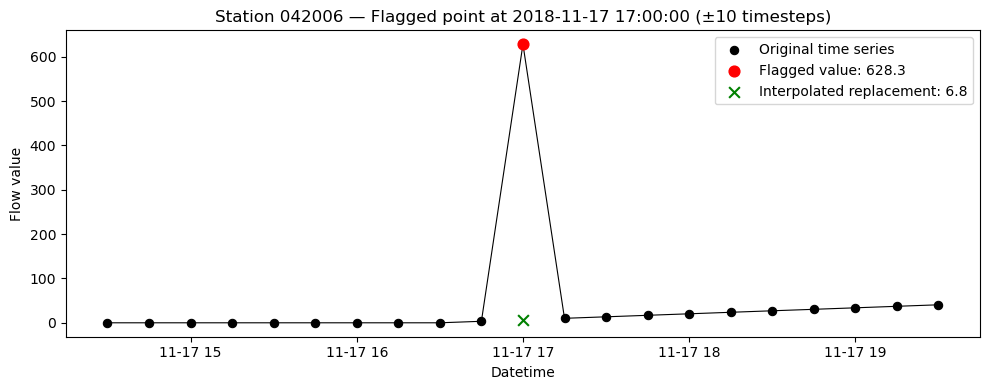

In [12]:
# =============================================================================
# VISUALISATION 2: ZOOMED VIEW AROUND EACH FLAGGED POINT
# =============================================================================
# For each flagged timestep, this plots a small window of 10 timesteps
# either side, showing the original uncleaned time series (blue), with the
# flagged value highlighted in red. The interpolated replacement is shown
# as a green cross for reference.

timestep_idx = 2
row = old_values.iloc[timestep_idx]

# Find the integer position of this flagged timestep in the dataframe
pos = df.index.get_loc(row["datetime"])

# Define the window as 10 timesteps either side, clamped to the dataframe bounds
window_start = max(0, pos - 10)
window_end = min(len(df) - 1, pos + 10)

# Subset the ORIGINAL data to the window (before interpolation)
# We reconstruct the original by replacing the interpolated value
# with the old value at the flagged timestep
df_window = df.iloc[window_start:window_end + 1].copy()
df_window.loc[row["datetime"], "value"] = row["old_value"]

fig, ax = plt.subplots(figsize=(10, 4))

# Plot the original time series (with the flagged value still in place)
ax.plot(df_window.index, df_window["value"],
        color="black", linewidth=0.8)
ax.scatter(df_window.index, df_window["value"],
        color="black", linewidth=0.8, label="Original time series")

# Highlight the flagged point in red
ax.scatter(row["datetime"], row["old_value"],
           color="red", zorder=5, s=60, label=f"Flagged value: {row['old_value']:.1f}")

# Show the interpolated replacement as a reference
ax.scatter(row["datetime"], row["new_value"],
           color="green", zorder=5, s=60, marker="x", label=f"Interpolated replacement: {row['new_value']:.1f}")

ax.set_title(f"Station {station_id} — Flagged point at {row['datetime']} (±10 timesteps)")
ax.set_xlabel("Datetime")
ax.set_ylabel("Flow value")
ax.legend()

fig.tight_layout()


In [5]:
# --- Save cleaned data ---
# os.makedirs(out_dir_data, exist_ok=True)
# path_out = os.path.join(out_dir_data, f"{station_id}.csv")
# df.to_csv(path_out)

# # --- Append interpolation log if requested ---
# if out_log_csv and not interp_log.empty:
#     os.makedirs(os.path.dirname(out_log_csv) or ".", exist_ok=True)
#     if os.path.exists(out_log_csv) and os.path.getsize(out_log_csv) > 0:
#         interp_log.to_csv(out_log_csv, mode="a", header=False, index=False)
#     else:
#         interp_log.to_csv(out_log_csv, index=False)

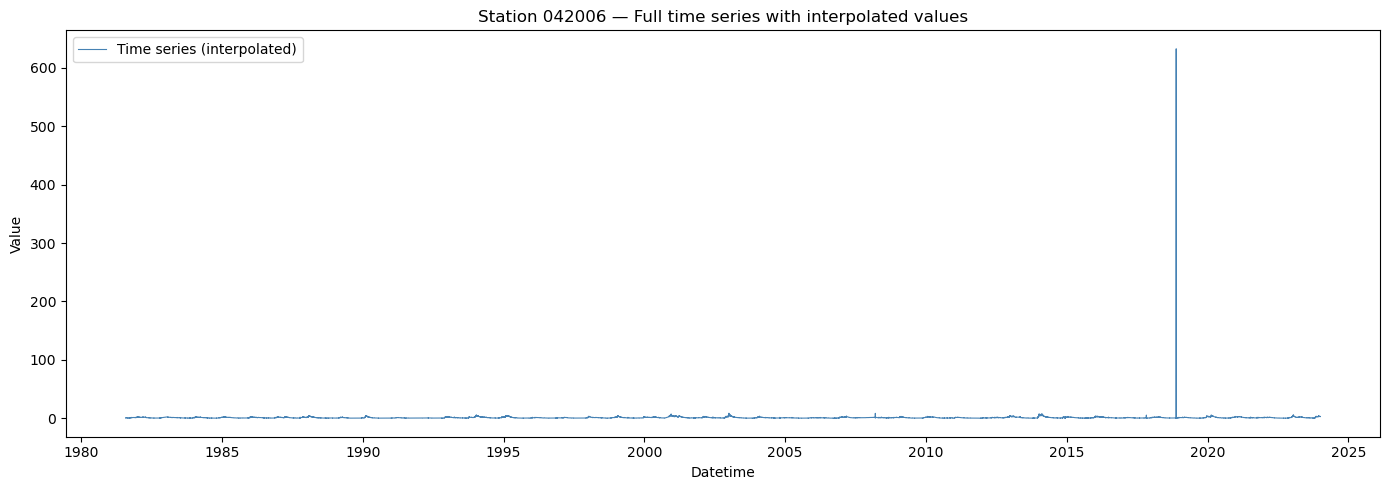

In [14]:
# =============================================================================
# VISUALISATION 1: FULL TIME SERIES — BEFORE AND AFTER INTERPOLATION
# =============================================================================
# This plot shows the complete time series, with flagged points highlighted
# in red (their original values) and the interpolated replacements in green.
# This gives an overview of how much data was flagged and where it sits
# within the record.

fig, ax = plt.subplots(figsize=(14, 5))

# Plot the full time series after interpolation
ax.plot(df.index, df["value"], color="steelblue", linewidth=0.8, label="Time series (interpolated)")

# Overlay the original flagged values in red
ax.scatter(
    old_values["datetime"],
    old_values["old_value"],
    color="red", zorder=5, s=20, label="Original flagged values")

# Overlay the interpolated replacements in green
ax.scatter(
    old_values["datetime"],
    old_values["new_value"],
    color="green", zorder=5, s=20, marker="x", label="Interpolated replacements")

ax.set_title(f"Station {station_id} — Full time series with interpolated values")
ax.set_xlabel("Datetime")
ax.set_ylabel("Value")
ax.legend()
plt.tight_layout()
plt.show()

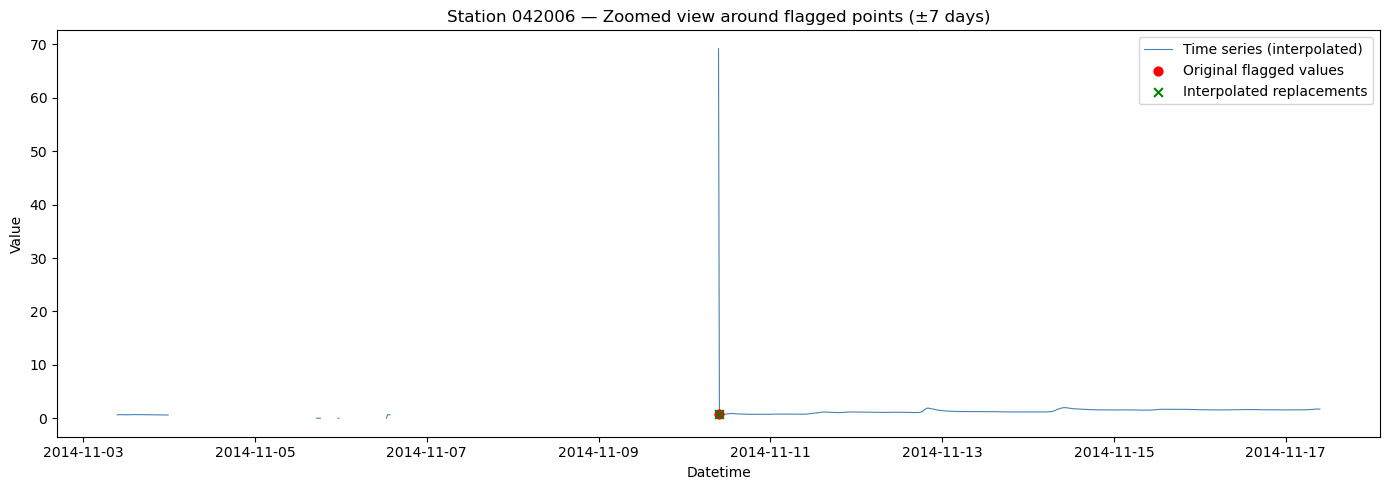

In [153]:
# =============================================================================
# VISUALISATION 2: ZOOMED VIEW AROUND FLAGGED POINTS
# =============================================================================
# The full time series can make individual interpolated points hard to see.
# This plot zooms in around the flagged timestamps, adding a small buffer
# on either side so the surrounding context is visible. If flagged points
# are scattered throughout the record, this shows the largest cluster.

# Find the extent of the flagged timestamps and add a buffer either side
flagged_times = pd.to_datetime(old_values["datetime"])
time_buffer = pd.Timedelta(days=7)
zoom_start = flagged_times.min() - time_buffer
zoom_end = flagged_times.max() + time_buffer

# Subset the data to the zoomed window
df_zoom = df.loc[zoom_start:zoom_end]
old_values_zoom = old_values[
    (flagged_times >= zoom_start) & (flagged_times <= zoom_end)
]

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_zoom.index, df_zoom["value"], color="steelblue", linewidth=0.8, label="Time series (interpolated)")

ax.scatter(
    old_values_zoom["datetime"],
    old_values_zoom["old_value"],
    color="red", zorder=5, s=40, label="Original flagged values")

ax.scatter(
    old_values_zoom["datetime"],
    old_values_zoom["new_value"],
    color="green", zorder=5, s=40, marker="x", label="Interpolated replacements")

ax.set_title(f"Station {station_id} — Zoomed view around flagged points (±{time_buffer.days} days)")
ax.set_xlabel("Datetime")
ax.set_ylabel("Value")
ax.legend()
plt.tight_layout()
plt.show()

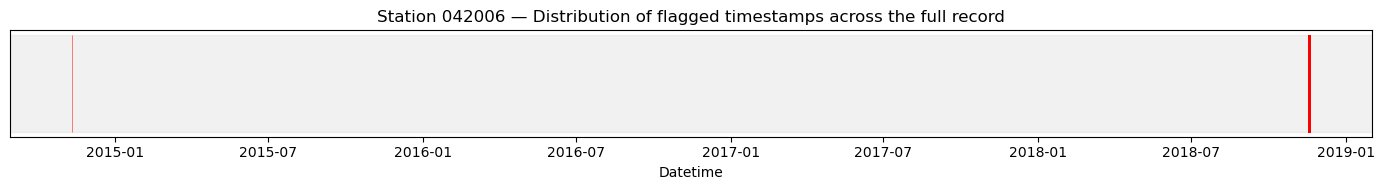

In [16]:
# =============================================================================
# VISUALISATION 3: FLAGGED TIMESTAMPS ALONG THE TIME AXIS
# =============================================================================
# This plot shows when flagged points occur across the full record.
# Each flagged timestamp is marked as a vertical line, making it easy to
# see whether bad data is clustered in time (e.g. during a particular season
# or instrument failure period) or scattered randomly throughout the record.
# This is useful context for judging how reliable the interpolation is likely
# to be — clustered gaps are harder to interpolate accurately than isolated points.

fig, ax = plt.subplots(figsize=(14, 2))

ax.vlines(
    pd.to_datetime(old_values["datetime"]),
    ymin=0, ymax=1,
    color="red", linewidth=0.5, alpha=0.7
)

# Add a shaded background to represent the full record extent
ax.axhspan(0, 1, color="lightgrey", alpha=0.3)

ax.set_title(f"Station {station_id} — Distribution of flagged timestamps across the full record")
ax.set_xlabel("Datetime")
ax.set_yticks([])  # y axis is not meaningful here
plt.tight_layout()
plt.show()

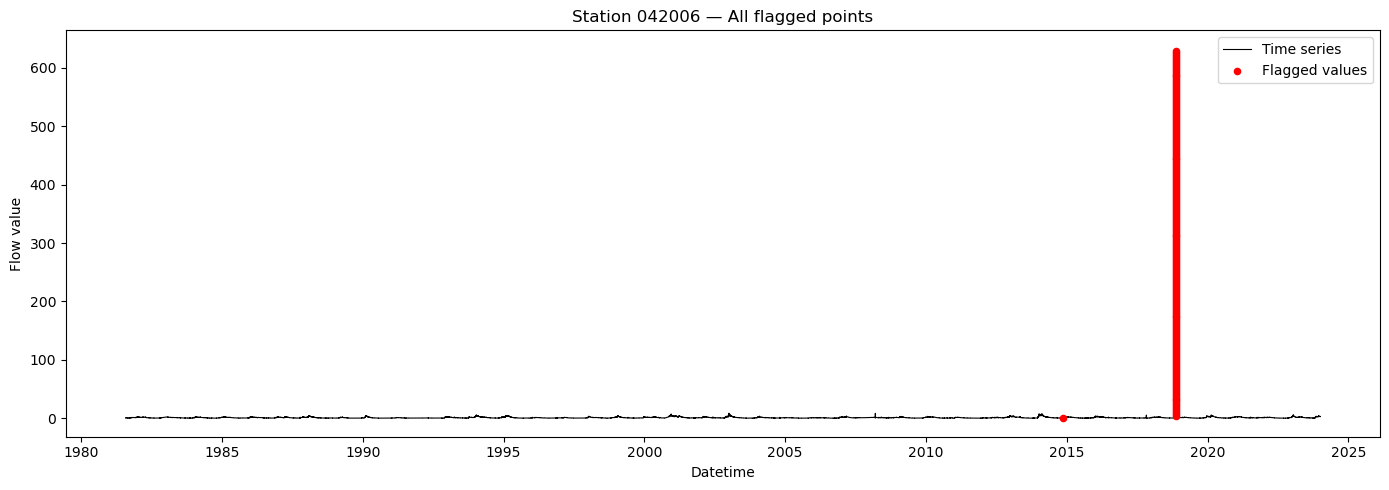

In [15]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df.index, df["value"], color="black", linewidth=0.8, label="Time series")
ax.scatter(df.loc[flagged_rows].index, df.loc[flagged_rows, "value"],
           color="red", zorder=5, s=20, label="Flagged values")

ax.set_title(f"Station {station_id} — All flagged points")
ax.set_xlabel("Datetime")
ax.set_ylabel("Flow value")
ax.legend()
fig.tight_layout()
plt.show()

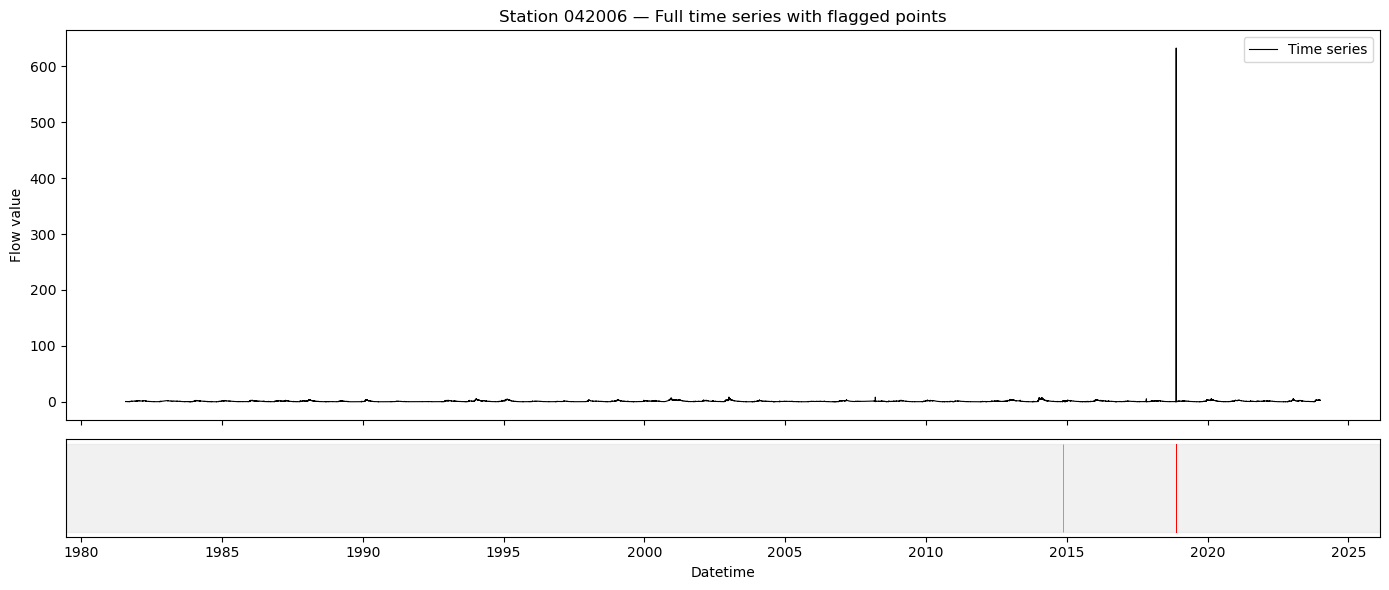

In [18]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), 
                                gridspec_kw={"height_ratios": [4, 1]}, 
                                sharex=True)

# --- Top panel: full time series with flagged points highlighted ---
ax1.plot(df.index, df["value"], color="black", linewidth=0.8, label="Time series")
# ax1.scatter(df.loc[flagged_rows].index, df.loc[flagged_rows, "value"],
#             color="red", zorder=5, s=20, label="Flagged values")
ax1.set_ylabel("Flow value")
ax1.legend()
ax1.set_title(f"Station {station_id} — Full time series with flagged points")

# --- Bottom panel: flagged timestamp locations ---
ax2.axhspan(0, 1, color="lightgrey", alpha=0.3)
ax2.vlines(
    df.loc[flagged_rows].index,
    ymin=0, ymax=1,
    color="red", linewidth=0.5, alpha=0.7
)
ax2.set_yticks([])
ax2.set_xlabel("Datetime")

fig.tight_layout()
plt.show()

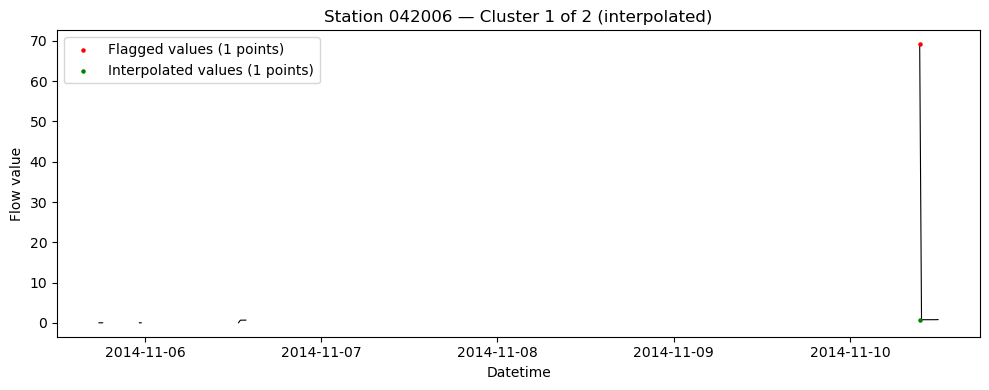

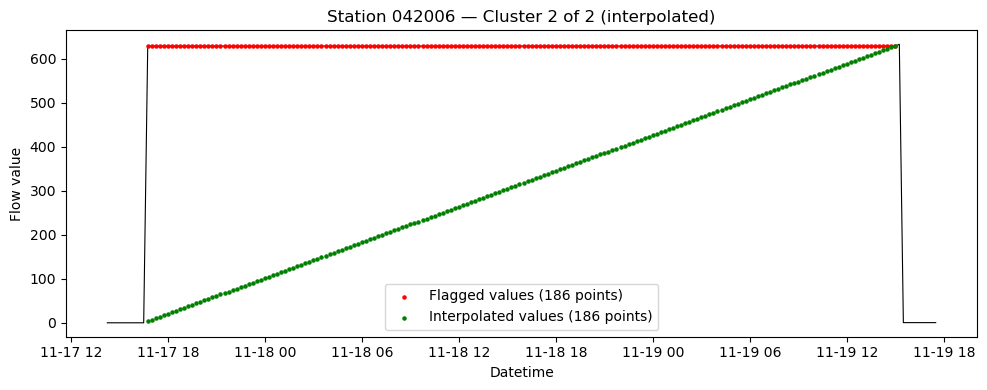

In [50]:
# =============================================================================
# VISUALISATION: ZOOMED VIEW AROUND EACH FLAGGED CLUSTER
# =============================================================================
# Set show_interpolated to True to show the interpolated values,
# or False to show only the original flagged values.

show_interpolated = True  # <--- TOGGLE HERE

for i, cluster in enumerate(clusters):

    window_start, window_end = get_window_with_real_values(df, cluster, n=10)

    # Always reconstruct the original time series as the base line
    df_window = df.iloc[window_start:window_end + 1].copy()
    cluster_datetimes = df.index[cluster]
    log_indexed = interp_log.set_index("datetime")

    df_window.loc[cluster_datetimes, "value"] = log_indexed.loc[cluster_datetimes, "old_value"].values

    fig, ax = plt.subplots(figsize=(10, 4))

    # Plot the original time series
    ax.plot(df_window.index, df_window["value"],
            color="black", linewidth=0.8)
#     ax.scatter(df_window.index, df_window["value"],
#                color="black", s=20, label="Time series")

    if show_interpolated:
            # Show the original flagged values in red
            old_values_cluster = log_indexed.loc[cluster_datetimes, "old_value"]
            ax.scatter(cluster_datetimes, old_values_cluster,
                       color="red", zorder=5, s=5, label=f"Flagged values ({len(cluster)} points)")

            # Show the interpolated (new) values in green
            new_values = log_indexed.loc[cluster_datetimes, "new_value"]
            ax.scatter(cluster_datetimes, new_values,
                       color="green", zorder=6, s=5, label=f"Interpolated values ({len(cluster)} points)")

            # Mark any that could not be interpolated in orange
            still_nan = log_indexed.loc[cluster_datetimes, "new_value"][log_indexed.loc[cluster_datetimes, "new_value"].isna()]
            if not still_nan.empty:
                ax.scatter(still_nan.index, log_indexed.loc[still_nan.index, "old_value"],
                           color="orange", zorder=6, s=5, marker="x",
                           label=f"Could not interpolate ({len(still_nan)} points)")
    else:
            # Highlight the original flagged values in red only
            old_values_cluster = log_indexed.loc[cluster_datetimes, "old_value"]
            ax.scatter(cluster_datetimes, old_values_cluster,
                       color="red", zorder=5, s=5, label=f"Flagged values ({len(cluster)} points)")

    ax.set_title(f"Station {station_id} — Cluster {i + 1} of {len(clusters)} "
                 f"({'interpolated' if show_interpolated else 'original'})")
    ax.set_xlabel("Datetime")
    ax.set_ylabel("Flow value")
    ax.legend()
    fig.tight_layout()
    plt.show()

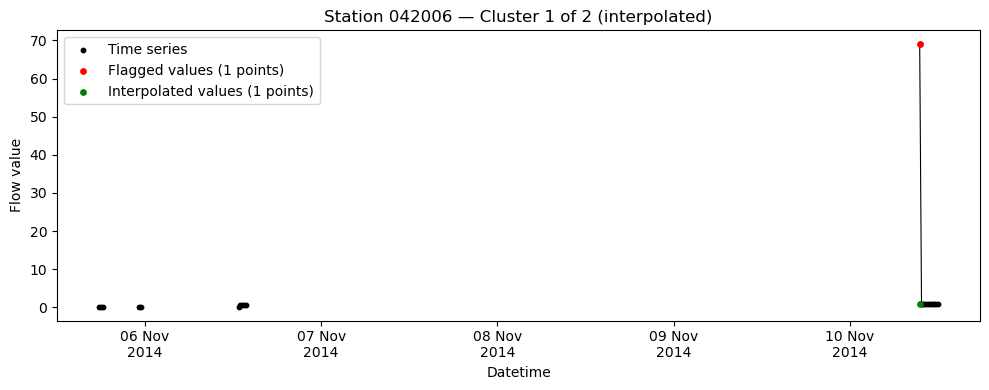

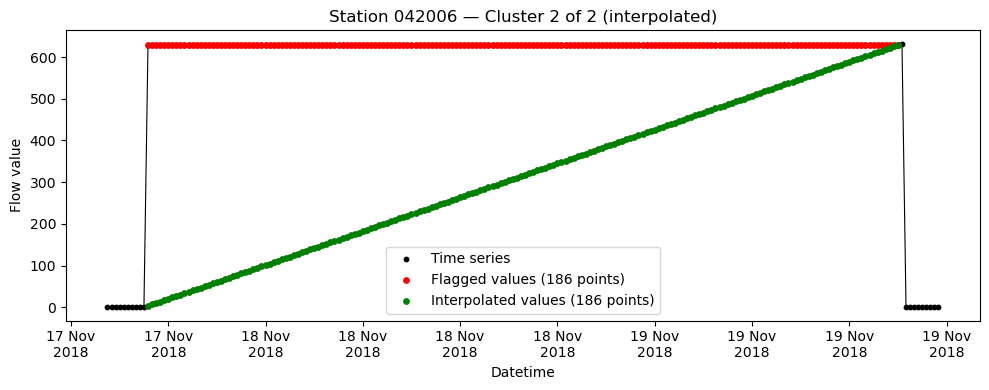

In [52]:
# =============================================================================
# VISUALISATION: ZOOMED VIEW AROUND EACH FLAGGED CLUSTER
# =============================================================================
import matplotlib.dates as mdates
show_interpolated = True  # <--- TOGGLE HERE

for i, cluster in enumerate(clusters):

    window_start, window_end = get_window_with_real_values(df, cluster, n=10)

    df_window = df.iloc[window_start:window_end + 1].copy()
    cluster_datetimes = df.index[cluster]
    log_indexed = interp_log.set_index("datetime")

    df_window.loc[cluster_datetimes, "value"] = log_indexed.loc[cluster_datetimes, "old_value"].values

    # --- Scale scatter point size based on number of points in the window ---
    n_points = len(df_window)
    point_size = max(10, min(80, 800 / n_points))

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.plot(df_window.index, df_window["value"],
            color="black", linewidth=0.8)
    ax.scatter(df_window.index, df_window["value"],
               color="black", s=point_size, label="Time series")

    if show_interpolated:
        old_values_cluster = log_indexed.loc[cluster_datetimes, "old_value"]
        ax.scatter(cluster_datetimes, old_values_cluster,
                   color="red", zorder=5, s=point_size * 1.5, label=f"Flagged values ({len(cluster)} points)")

        new_values = log_indexed.loc[cluster_datetimes, "new_value"]
        ax.scatter(cluster_datetimes, new_values,
                   color="green", zorder=6, s=point_size * 1.5, label=f"Interpolated values ({len(cluster)} points)")

        still_nan = log_indexed.loc[cluster_datetimes, "new_value"][log_indexed.loc[cluster_datetimes, "new_value"].isna()]
        if not still_nan.empty:
            ax.scatter(still_nan.index, log_indexed.loc[still_nan.index, "old_value"],
                       color="orange", zorder=6, s=point_size * 1.5, marker="x",
                       label=f"Could not interpolate ({len(still_nan)} points)")
    else:
        old_values_cluster = log_indexed.loc[cluster_datetimes, "old_value"]
        ax.scatter(cluster_datetimes, old_values_cluster,
                   color="red", zorder=5, s=point_size * 1.5, label=f"Flagged values ({len(cluster)} points)")

    # --- Format x axis based on the time range of the window ---
    time_range = df_window.index[-1] - df_window.index[0]

    if time_range <= pd.Timedelta(days=2):
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
    elif time_range <= pd.Timedelta(days=30):
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Y"))
    else:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

    plt.setp(ax.xaxis.get_majorticklabels(), rotation=0, ha="center")

    ax.set_title(f"Station {station_id} — Cluster {i + 1} of {len(clusters)} "
                 f"({'interpolated' if show_interpolated else 'original'})")
    ax.set_xlabel("Datetime")
    ax.set_ylabel("Flow value")
    ax.legend()
    fig.tight_layout()
    plt.show()

In [53]:
def plot_flagged_clusters(
    df: pd.DataFrame,
    clusters: list,
    interp_log: pd.DataFrame,
    station_id: str,
    show_interpolated: bool = False,
    n_context: int = 10,
):
    """
    Plot a zoomed window around each contiguous cluster of flagged values.

    Parameters
    ----------
    df : pd.DataFrame
        The dataframe after interpolation, with datetime index and 'value' column.
    clusters : list
        List of arrays of integer positions, one per contiguous cluster.
        Produced by: np.split(flagged_positions, np.where(np.diff(flagged_positions) > 1)[0] + 1)
    interp_log : pd.DataFrame
        Interpolation log with columns ['station', 'datetime', 'old_value', 'new_value'].
    station_id : str
        Station ID, used in plot titles.
    show_interpolated : bool
        If True, overlay interpolated (new) values in green alongside the
        original flagged values in red. Default is False.
    n_context : int
        Number of real (non-NaN) values to show either side of each cluster.
        Default is 10.
    """

    print(f"{len(clusters)} cluster(s) of flagged points found.")

    log_indexed = interp_log.set_index("datetime")

    for i, cluster in enumerate(clusters):

        window_start, window_end = get_window_with_real_values(df, cluster, n=n_context)

        df_window = df.iloc[window_start:window_end + 1].copy()
        cluster_datetimes = df.index[cluster]

        # Restore original values as the base line
        df_window.loc[cluster_datetimes, "value"] = log_indexed.loc[cluster_datetimes, "old_value"].values

        # Scale scatter point size based on number of points in the window
        n_points = len(df_window)
        point_size = max(10, min(80, 800 / n_points))

        fig, ax = plt.subplots(figsize=(10, 4))

        ax.plot(df_window.index, df_window["value"],
                color="black", linewidth=0.8)
        ax.scatter(df_window.index, df_window["value"],
                   color="black", s=point_size, label="Time series")

        if show_interpolated:
            old_values_cluster = log_indexed.loc[cluster_datetimes, "old_value"]
            ax.scatter(cluster_datetimes, old_values_cluster,
                       color="red", zorder=5, s=point_size * 1.5,
                       label=f"Flagged values ({len(cluster)} points)")

            new_values = log_indexed.loc[cluster_datetimes, "new_value"]
            ax.scatter(cluster_datetimes, new_values,
                       color="green", zorder=6, s=point_size * 1.5,
                       label=f"Interpolated values ({len(cluster)} points)")

            still_nan = new_values[new_values.isna()]
            if not still_nan.empty:
                ax.scatter(still_nan.index, log_indexed.loc[still_nan.index, "old_value"],
                           color="orange", zorder=6, s=point_size * 1.5, marker="x",
                           label=f"Could not interpolate ({len(still_nan)} points)")
        else:
            old_values_cluster = log_indexed.loc[cluster_datetimes, "old_value"]
            ax.scatter(cluster_datetimes, old_values_cluster,
                       color="red", zorder=5, s=point_size * 1.5,
                       label=f"Flagged values ({len(cluster)} points)")

        # Format x axis based on time range of the window
        time_range = df_window.index[-1] - df_window.index[0]
        if time_range <= pd.Timedelta(days=2):
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
        elif time_range <= pd.Timedelta(days=30):
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Y"))
        else:
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

        plt.setp(ax.xaxis.get_majorticklabels(), rotation=0, ha="center")

        ax.set_title(f"Station {station_id} — Cluster {i + 1} of {len(clusters)} "
                     f"({'interpolated' if show_interpolated else 'original'})")
        ax.set_xlabel("Datetime")
        ax.set_ylabel("Flow value")
        ax.legend()
        fig.tight_layout()
        plt.show()

2 cluster(s) of flagged points found.


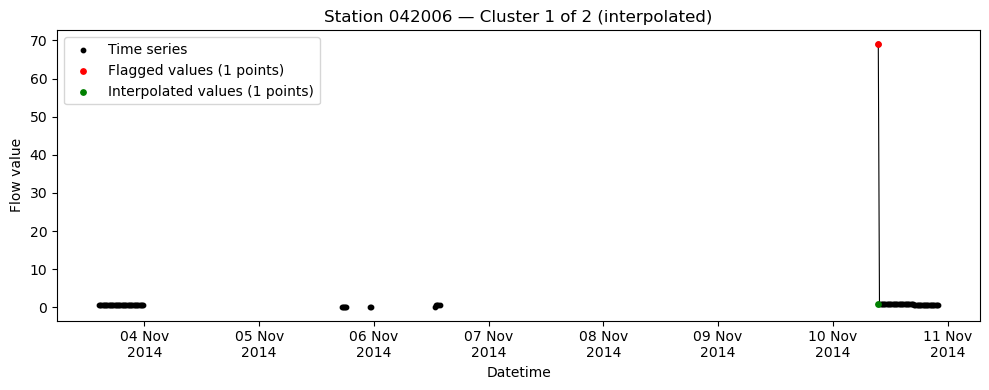

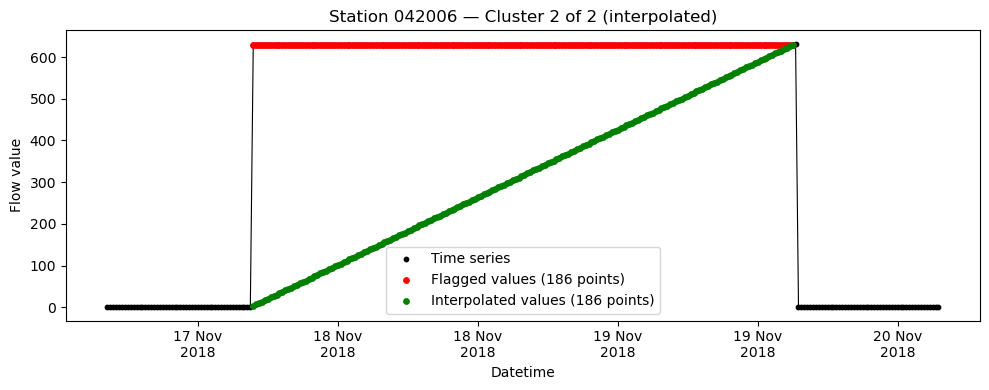

In [57]:
# # Show original flagged values
# plot_flagged_clusters(df, clusters, interp_log, station_id)

# # Show with interpolated values overlaid
# plot_flagged_clusters(df, clusters, interp_log, station_id, show_interpolated=True)

# Adjust context window size
plot_flagged_clusters(df, clusters, interp_log, station_id, n_context=50, show_interpolated=True)